# Part 2 – Logistic Regression from Scratch: Predicting Best-Selling Books
**Module:** Programming for Data Analytics 2 (PDAN8412/w)

**Business question:** can we predict, from information that is available about a book,
whether it will be a *best seller*?

**Approach (follows the brief):**
1. Source a dataset and justify it
2. Exploratory Data Analysis (EDA) + data cleaning
3. Feature selection (p-values: backward AND forward elimination)
4. Train a logistic regression **written from scratch with NumPy** (gradient descent)
5. Evaluate and interpret with Python libraries (scikit-learn metrics)
6. Retrain with improved hyper-parameters and compare

Note on libraries: the model itself (sigmoid, loss, gradient descent, Newton–Raphson,
Wald p-values) uses **only NumPy**. scikit-learn is used only for (a) splitting data,
(b) computing evaluation metrics, and (c) *validating* that my scratch model gives
the same answer as a trusted implementation.

In [1]:
# ----------------------------------------------------------------------------
# 0. IMPORTS AND SETTINGS
# ----------------------------------------------------------------------------
import json
import os
import re
import warnings

import matplotlib
matplotlib.use("Agg")                      # draw figures to files (no pop-up windows)
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats                    # only used for the normal CDF (p-values)
from sklearn.linear_model import LogisticRegression   # ONLY used to validate my model
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, log_loss, matthews_corrcoef, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings("ignore")
RANDOM_STATE = 42                          # makes every result reproducible
np.random.seed(RANDOM_STATE)

DATA_FILE = "books.csv"                    # Goodbooks-10k (Goodreads) – see section 1
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Consistent, colour-blind-friendly palette used on every figure
BLUE, ORANGE, GREY = "#2F5D8A", "#D9822B", "#8C8C8C"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "font.size": 9})
RESULTS = {}                               # everything the report needs is collected here


def savefig(name):
    """Save the current figure into the outputs folder and close it."""
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/{name}.png", dpi=160, bbox_inches="tight")
    plt.close()
    try:                                   # in a notebook, also show the saved figure under the cell
        from IPython import get_ipython
        if get_ipython() is not None:
            from IPython.display import Image, display
            display(Image(filename=f"{OUT_DIR}/{name}.png", width=760))
    except Exception:
        pass

## 0.1 Workflow overview
The diagram below shows the eight stages of this study in the order they are carried out.

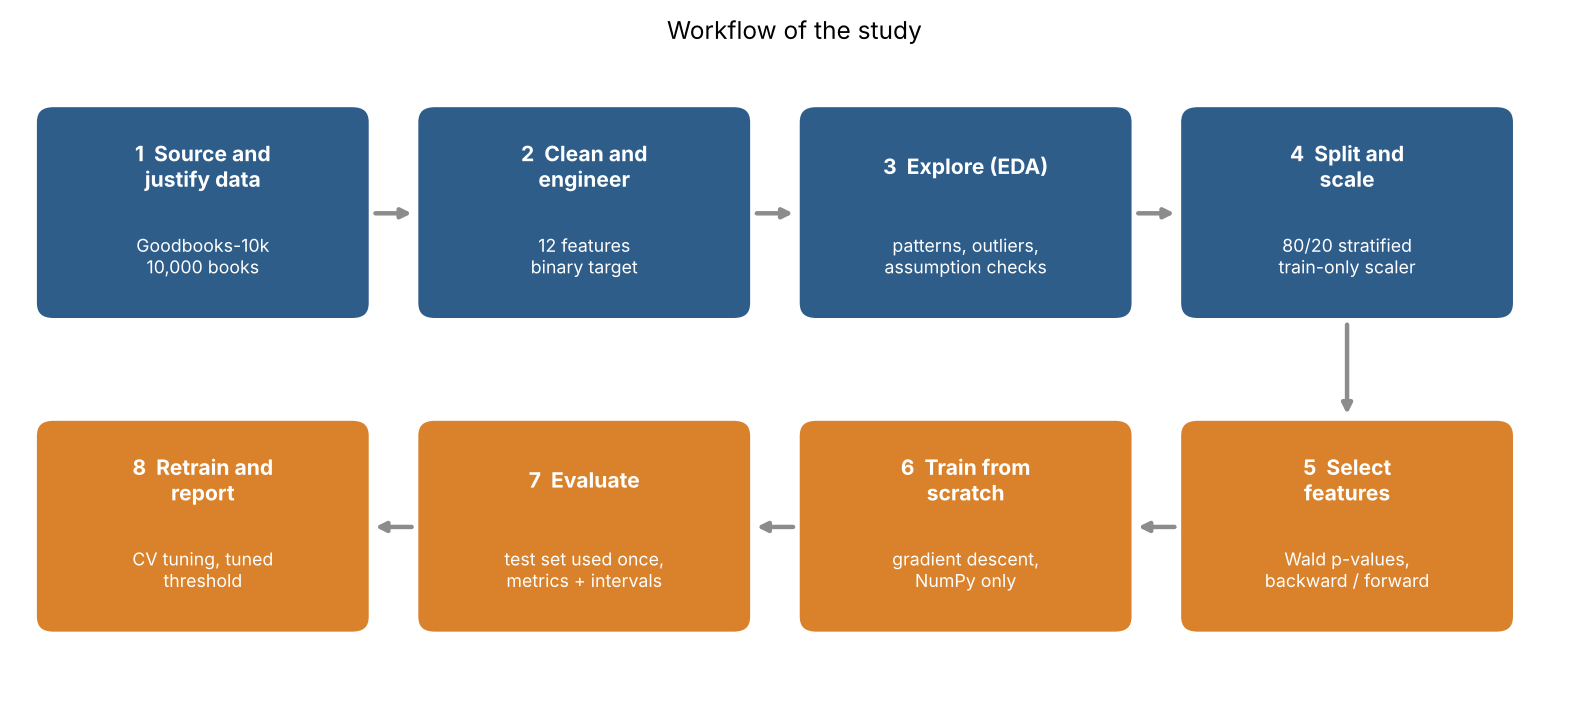

In [2]:
from matplotlib.patches import FancyBboxPatch

steps = [("1  Source and\njustify data", "Goodbooks-10k\n10,000 books"),
         ("2  Clean and\nengineer", "12 features\nbinary target"),
         ("3  Explore (EDA)", "patterns, outliers,\nassumption checks"),
         ("4  Split and\nscale", "80/20 stratified\ntrain-only scaler"),
         ("5  Select\nfeatures", "Wald p-values,\nbackward / forward"),
         ("6  Train from\nscratch", "gradient descent,\nNumPy only"),
         ("7  Evaluate", "test set used once,\nmetrics + intervals"),
         ("8  Retrain and\nreport", "CV tuning, tuned\nthreshold")]
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4.6)
# top row runs left to right, bottom row runs right to left (a "snake")
pos = [(0.15 + i * 2.45, 2.75) for i in range(4)] + [(0.15 + (3 - i) * 2.45, 0.55) for i in range(4)]
for n, ((title, sub), (x, y)) in enumerate(zip(steps, pos)):
    ax.add_patch(FancyBboxPatch((x, y), 2.1, 1.45, boxstyle="round,pad=0.03,rounding_size=0.12",
                                fc=BLUE if n < 4 else ORANGE, ec="white", lw=2))
    ax.text(x + 1.05, y + 1.05, title, ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
    ax.text(x + 1.05, y + 0.42, sub, ha="center", va="center", color="white", fontsize=8)
for n in range(7):
    (x0, y0), (x1, y1) = pos[n], pos[n + 1]
    if n < 3:      # top row: arrow to the right
        a, b = (x0 + 2.13, y0 + 0.72), (x1 - 0.03, y1 + 0.72)
    elif n == 3:   # drop from the end of row 1 to row 2
        a, b = (x0 + 1.05, y0 - 0.03), (x1 + 1.05, y1 + 1.48)
    else:          # bottom row: arrow to the left
        a, b = (x0 - 0.03, y0 + 0.72), (x1 + 2.13, y1 + 0.72)
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color=GREY, lw=2))
ax.set_title("Workflow of the study", fontsize=11)
savefig("fig13_workflow")

## 1. Dataset: sourcing, quality and suitability
**Dataset:** *Goodbooks-10k* (Goodreads), 10,000 popular books, one row per book
(author, publication year, language, average rating, number of editions, rating counts).

**Why it is suitable for a best-seller classifier**
* It is about **books**, the client's product, and has 10,000 rows (plenty for a
  12-feature logistic regression; rule of thumb is >=10 events per variable).
* Logistic regression needs a **binary target**. Public *sales* data is not
  available, so the target is built from **reader-engagement**: a book is a
  *best seller* if its number of ratings is in the **top 20 %** of the dataset.
  Number of ratings is a widely used popularity proxy because every rating is a
  reader who bought/borrowed and read the book.
* Features are a mix of numeric and categorical information, so cleaning, encoding and
  feature selection are all meaningful.

**Leakage control (a common pitfall):** columns that are *part of* the target
(`ratings_count`, `work_ratings_count`, `ratings_1..5`, `work_text_reviews_count`)
are **not allowed as features** - the model would just read the answer.

**Known limitations (reported honestly):** popularity is a proxy for sales; the dataset
is already "popular books only" (selection bias); Goodreads users are not all book buyers.

In [3]:
raw = pd.read_csv(DATA_FILE)
print("Raw shape:", raw.shape)

# ---- Data quality audit ------------------------------------------------------
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "unique": raw.nunique(),
})
print(audit[audit["missing"] > 0])
print("Duplicate book_id :", raw.book_id.duplicated().sum())
print("Duplicate work_id :", raw.work_id.duplicated().sum())
print("Duplicate titles  :", raw.title.duplicated().sum(), "(different works sharing a title - kept)")
print("Publication year range:", raw.original_publication_year.min(), "to", raw.original_publication_year.max())
print("Books published before 1800 (genuine classics, not errors):",
      int((raw.original_publication_year < 1800).sum()))
check = (raw[["ratings_1", "ratings_2", "ratings_3", "ratings_4", "ratings_5"]].sum(axis=1)
         - raw.work_ratings_count).abs().max()
print("Consistency check: max |sum(ratings_1..5) - work_ratings_count| =", check)

RESULTS["data_quality"] = {
    "rows": int(raw.shape[0]), "columns": int(raw.shape[1]),
    "missing": {k: int(v) for k, v in raw.isna().sum().items() if v > 0},
    "duplicate_book_id": int(raw.book_id.duplicated().sum()),
    "duplicate_work_id": int(raw.work_id.duplicated().sum()),
    "duplicate_titles": int(raw.title.duplicated().sum()),
    "pre_1800": int((raw.original_publication_year < 1800).sum()),
    "ratings_consistency_max_diff": float(check),
}

Raw shape: (10000, 23)
                             dtype  missing  missing_%  unique
isbn                           str      700        7.0    9300
isbn13                     float64      585        5.9    9153
original_publication_year  float64       21        0.2     293
original_title                 str      585        5.9    9274
language_code                  str     1084       10.8      25
Duplicate book_id : 0
Duplicate work_id : 0
Duplicate titles  : 36 (different works sharing a title - kept)
Publication year range: -1750.0 to 2017.0
Books published before 1800 (genuine classics, not errors): 125
Consistency check: max |sum(ratings_1..5) - work_ratings_count| = 0


## 2. Data cleaning and feature engineering
Decisions (each one is justified):
| Problem | Action | Reason |
|---|---|---|
| 21 missing publication years | fill with the **median** | median is robust to the extreme old years |
| 1,084 missing language codes | new category **"unknown"** (`lang_unknown`) | missingness may itself be informative |
| 700 missing ISBNs | binary flag `has_isbn` | ISBN itself is an ID, not a predictor |
| Very old years (to -1750) | convert to *age*, cap at the 99th percentile, then `log1p` | stops a few ancient books dominating |
| `books_count` very right-skewed (max 3,455) | `log1p` transform | logistic regression behaves best with roughly symmetric inputs |
| Many language codes (eng, en-US, en-GB ...) | 3 groups: English (reference), `lang_other`, `lang_unknown` | collapses near-duplicates; English as the large reference group avoids the dummy-variable collinearity trap |
| Title contains series info "(Series, #2)" | extract `is_series`, `is_series_book1` | series books are commercially different |

In [4]:
df = raw.copy()

# --- 2.1 Create the TARGET -----------------------------------------------------
threshold_count = df["work_ratings_count"].quantile(0.80)
df["bestseller"] = (df["work_ratings_count"] >= threshold_count).astype(int)
print(f"Best seller = at least {threshold_count:,.0f} ratings (top 20%)")
print(df["bestseller"].value_counts(normalize=True).round(3))
RESULTS["target"] = {"threshold_ratings": float(threshold_count),
                     "bestseller_share": float(df.bestseller.mean()),
                     "n_bestsellers": int(df.bestseller.sum())}

# --- 2.2 Handle missing values -------------------------------------------------
median_year = df["original_publication_year"].median()
df["original_publication_year"] = df["original_publication_year"].fillna(median_year)
df["language_code"] = df["language_code"].fillna("unknown")

# --- 2.3 Engineer features -----------------------------------------------------
REFERENCE_YEAR = 2017                                     # latest year in the data
age = REFERENCE_YEAR - df["original_publication_year"]
age = age.clip(upper=age.quantile(0.99))                  # winsorise extreme ages
df["log_book_age"] = np.log1p(age)

df["log_books_count"] = np.log1p(df["books_count"])       # number of editions, log scale
is_en = df["language_code"].str.lower().str.startswith("en")
df["lang_unknown"] = (df["language_code"] == "unknown").astype(int)
df["lang_other"] = ((~is_en) & (df["lang_unknown"] == 0)).astype(int)   # known, non-English; English = reference group
df["has_isbn"] = df["isbn"].notna().astype(int)

# Series information is written inside the title, e.g. "The Hunger Games (The Hunger Games, #1)"
series = df["title"].str.extract(r"\(([^()]*?),?\s*#(\d+(?:\.\d+)?)\)\s*$")
df["is_series"] = series[0].notna().astype(int)
df["is_series_book1"] = (pd.to_numeric(series[1], errors="coerce") == 1).astype(int)

clean_title = df["title"].str.replace(r"\s*\([^()]*\)\s*$", "", regex=True)
df["title_words"] = clean_title.str.split().str.len().clip(upper=15)   # cap very long titles
df["has_subtitle"] = clean_title.str.contains(":").astype(int)

df["n_authors"] = df["authors"].str.split(",").str.len().clip(upper=5)  # includes illustrators etc.
first_author = df["authors"].str.split(",").str[0].str.strip()
df["log_author_titles"] = np.log1p(first_author.map(first_author.value_counts()))  # prolific author?

FEATURES = ["average_rating", "log_books_count", "log_book_age", "lang_other", "lang_unknown",
            "has_isbn", "is_series", "is_series_book1", "title_words", "has_subtitle",
            "n_authors", "log_author_titles"]
print("\nCandidate features:", len(FEATURES))
print("Missing values left in model data:", int(df[FEATURES + ['bestseller']].isna().sum().sum()))

model_df = df[FEATURES + ["bestseller", "title", "authors", "work_ratings_count"]].copy()
model_df.to_csv(f"{OUT_DIR}/cleaned_model_data.csv", index=False)

Best seller = at least 55,674 ratings (top 20%)
bestseller
0    0.8
1    0.2
Name: proportion, dtype: float64

Candidate features: 12
Missing values left in model data: 0


## 3. Exploratory Data Analysis (EDA)
Goal: understand the target, each feature, and how the features relate to a best seller.

                     count  mean   std   min   25%   50%   75%    max
average_rating     10000.0  4.00  0.25  2.47  3.85  4.02  4.18   4.82
log_books_count    10000.0  3.73  0.96  0.69  3.18  3.71  4.22   8.15
log_book_age       10000.0  2.72  1.01  0.00  1.95  2.64  3.33   5.69
lang_other         10000.0  0.02  0.14  0.00  0.00  0.00  0.00   1.00
lang_unknown       10000.0  0.11  0.31  0.00  0.00  0.00  0.00   1.00
has_isbn           10000.0  0.93  0.26  0.00  1.00  1.00  1.00   1.00
is_series          10000.0  0.43  0.50  0.00  0.00  0.00  1.00   1.00
is_series_book1    10000.0  0.16  0.37  0.00  0.00  0.00  0.00   1.00
title_words        10000.0  3.89  2.87  1.00  2.00  3.00  5.00  15.00
has_subtitle       10000.0  0.13  0.34  0.00  0.00  0.00  0.00   1.00
n_authors          10000.0  1.29  0.66  1.00  1.00  1.00  1.00   5.00
log_author_titles  10000.0  1.85  0.99  0.69  1.10  1.79  2.64   4.60


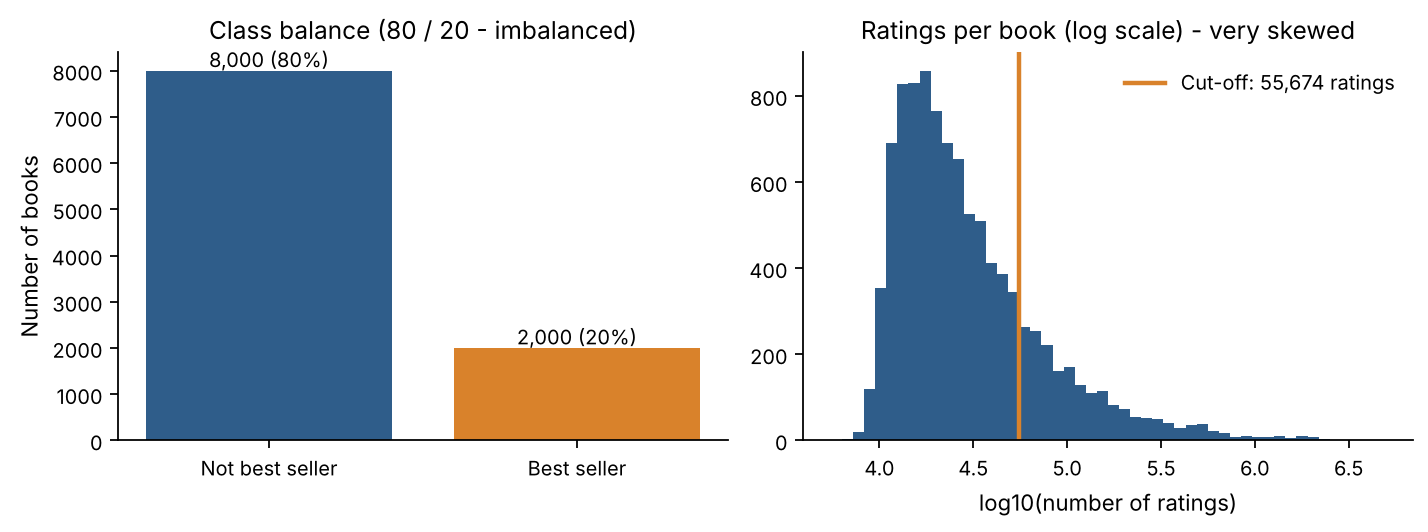

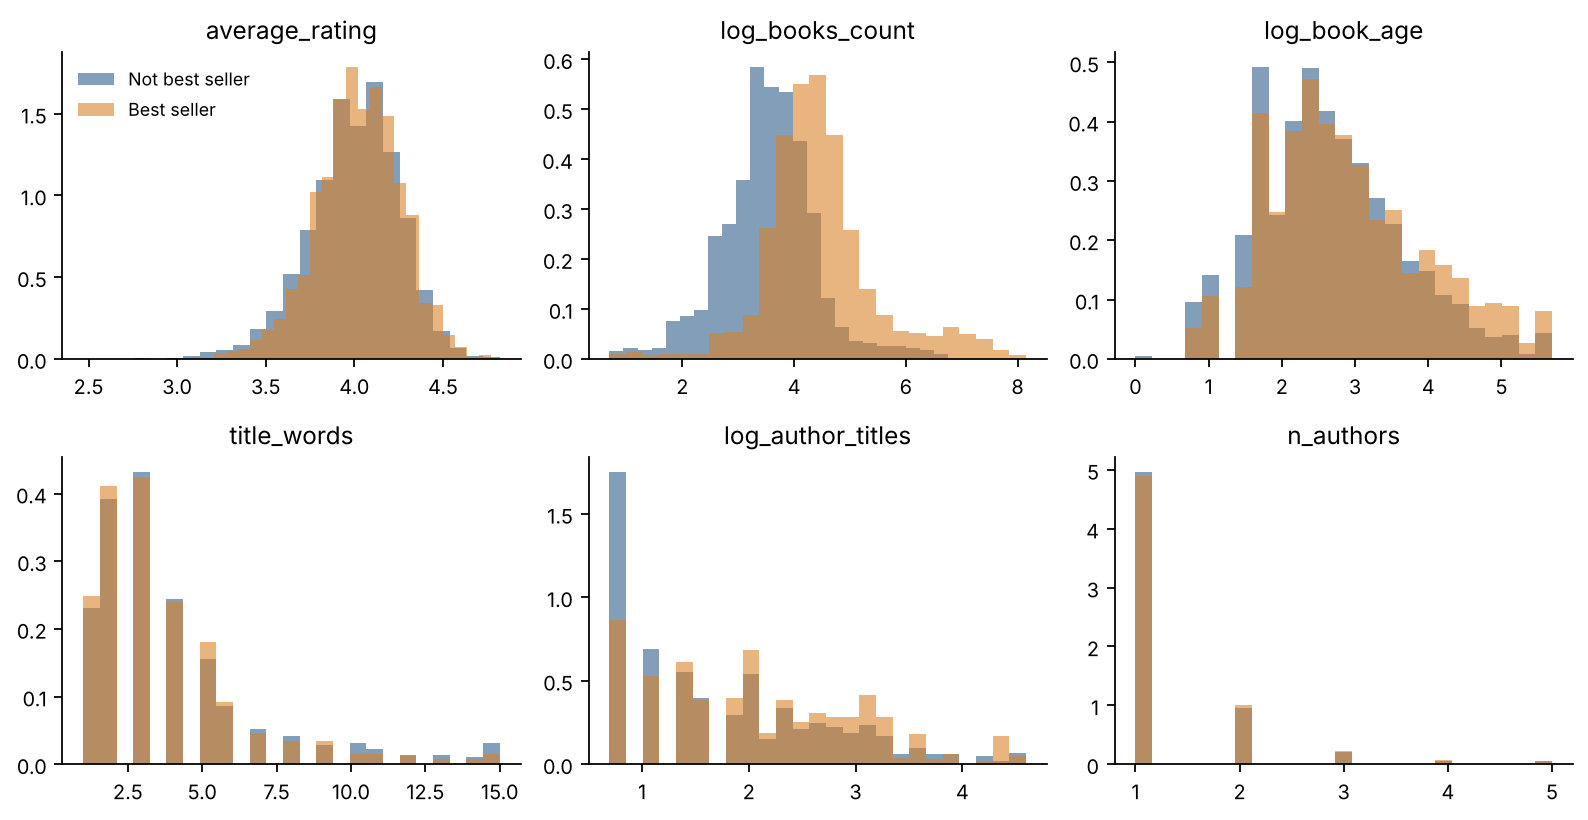

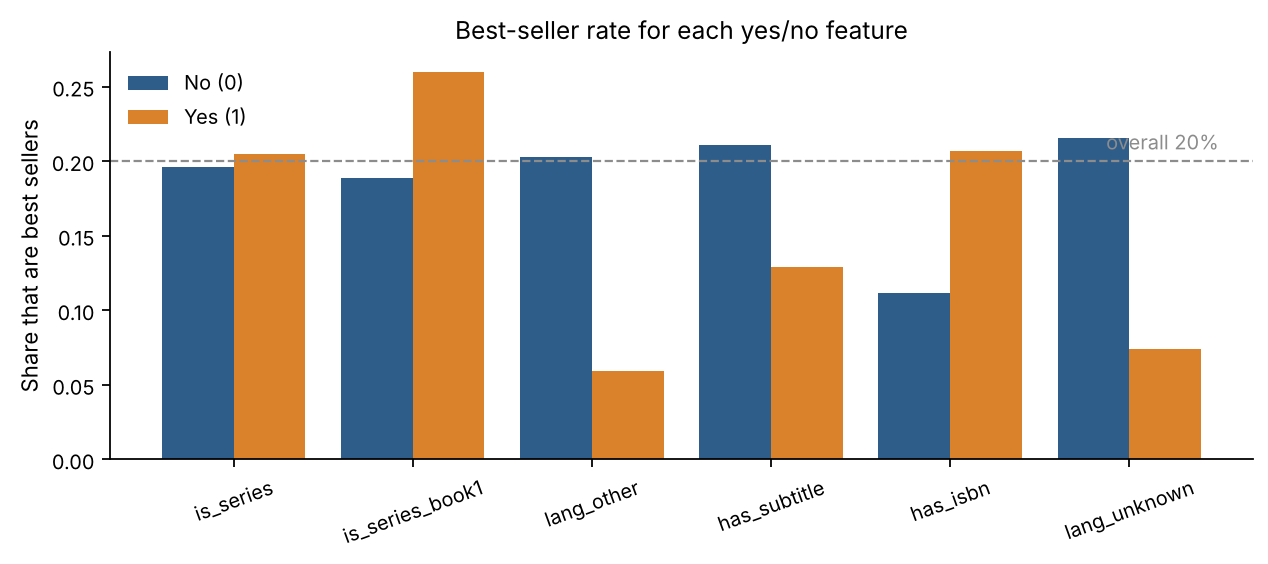

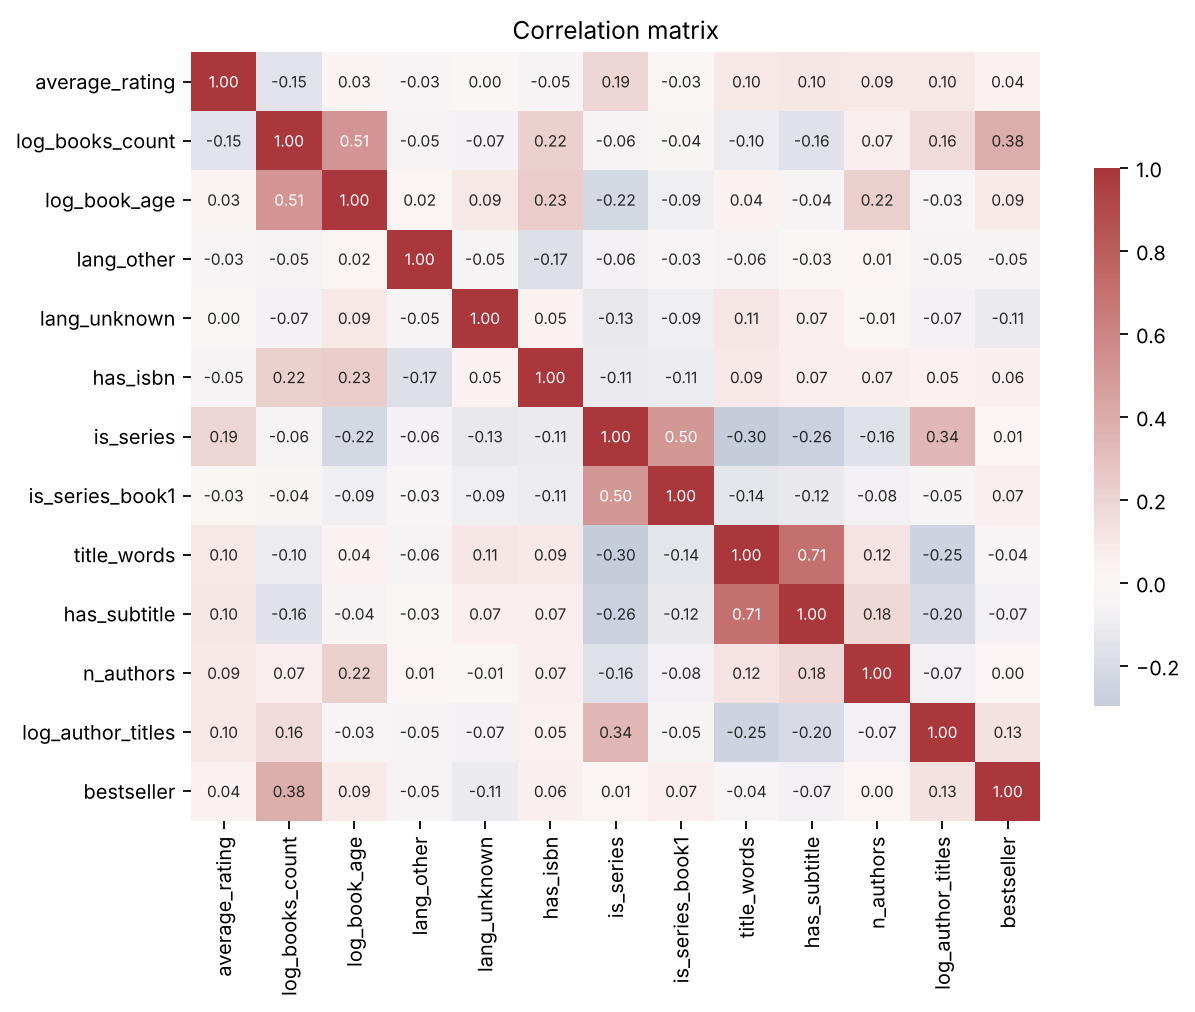


Correlation with bestseller:
 log_books_count      0.383
log_author_titles    0.132
lang_unknown        -0.110
log_book_age         0.092
has_subtitle        -0.069
is_series_book1      0.066
has_isbn             0.061
lang_other          -0.048
average_rating       0.045
title_words         -0.037
is_series            0.011
n_authors            0.004
Name: bestseller, dtype: float64


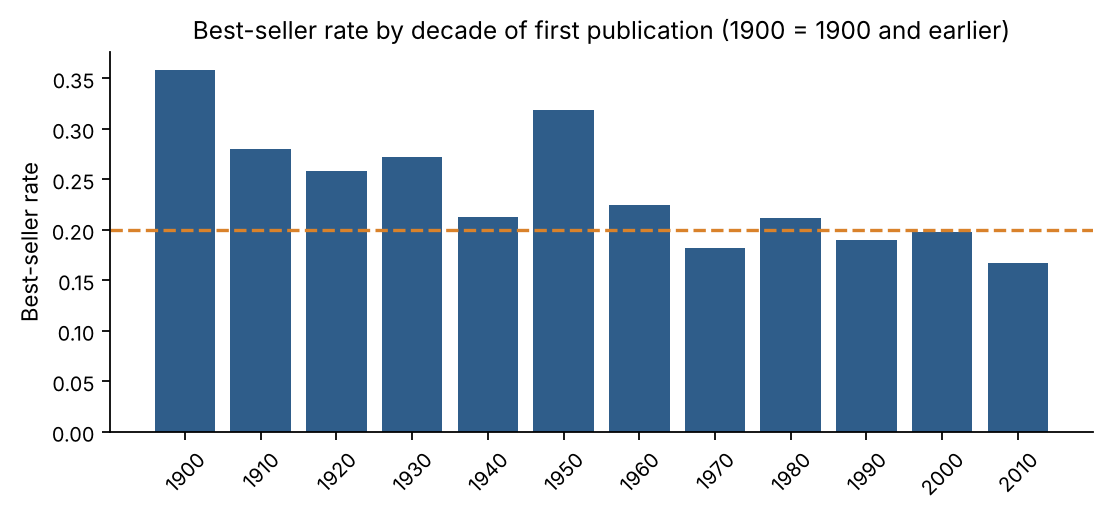

books_count: 844 IQR outliers (8.4%) -> handled with log transform
work_ratings_count: 1143 IQR outliers (11.4%) -> handled with log transform

VIF (values above 5 would signal a problem):
 title_words          2.13
has_subtitle         2.11
is_series            1.92
log_book_age         1.60
log_books_count      1.55
is_series_book1      1.48
log_author_titles    1.31
average_rating       1.17
has_isbn             1.13
n_authors            1.11
lang_other           1.05
lang_unknown         1.05
dtype: float64


In [5]:
# --- 3.1 Summary statistics -----------------------------------------------------
summary = model_df[FEATURES].describe().T.round(2)
print(summary)
summary.to_csv(f"{OUT_DIR}/summary_stats.csv")
RESULTS["summary_stats"] = summary.reset_index().rename(columns={"index": "feature"}).to_dict("records")

# --- 3.2 Target: class balance and the 'best seller' cut-off ---------------------
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
counts = model_df["bestseller"].value_counts().sort_index()
ax[0].bar(["Not best seller", "Best seller"], counts.values, color=[BLUE, ORANGE])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 80, f"{v:,} ({v / len(model_df):.0%})", ha="center")
ax[0].set_title("Class balance (80 / 20 - imbalanced)")
ax[0].set_ylabel("Number of books")
ax[1].hist(np.log10(model_df["work_ratings_count"]), bins=50, color=BLUE)
ax[1].axvline(np.log10(threshold_count), color=ORANGE, lw=2, label=f"Cut-off: {threshold_count:,.0f} ratings")
ax[1].set_title("Ratings per book (log scale) - very skewed")
ax[1].set_xlabel("log10(number of ratings)")
ax[1].legend(frameon=False)
savefig("fig01_class_balance")

# --- 3.3 Numeric features by class -----------------------------------------------
num_feats = ["average_rating", "log_books_count", "log_book_age", "title_words",
             "log_author_titles", "n_authors"]
fig, axes = plt.subplots(2, 3, figsize=(10, 5.2))
for a, f in zip(axes.ravel(), num_feats):
    for cls, col, lab in [(0, BLUE, "Not best seller"), (1, ORANGE, "Best seller")]:
        a.hist(model_df.loc[model_df.bestseller == cls, f], bins=25, alpha=0.6, color=col,
               label=lab, density=True)
    a.set_title(f)
axes[0, 0].legend(frameon=False, fontsize=8)
savefig("fig02_distributions")

# --- 3.4 Best-seller rate for the binary features ---------------------------------
bin_feats = ["is_series", "is_series_book1", "lang_other", "has_subtitle", "has_isbn", "lang_unknown"]
rates = []
for f in bin_feats:
    for v in (0, 1):
        rates.append({"feature": f, "value": v, "rate": model_df.loc[model_df[f] == v, "bestseller"].mean()})
rates = pd.DataFrame(rates)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(bin_feats))
ax.bar(x - 0.2, rates[rates.value == 0].rate, 0.4, color=BLUE, label="No (0)")
ax.bar(x + 0.2, rates[rates.value == 1].rate, 0.4, color=ORANGE, label="Yes (1)")
ax.axhline(model_df.bestseller.mean(), color=GREY, ls="--", lw=1)
ax.text(len(bin_feats) - 0.5, model_df.bestseller.mean() + 0.008, "overall 20%", color=GREY, ha="right")
ax.set_xticks(x); ax.set_xticklabels(bin_feats, rotation=20)
ax.set_ylabel("Share that are best sellers"); ax.set_title("Best-seller rate for each yes/no feature")
ax.legend(frameon=False)
savefig("fig03_binary_rates")
RESULTS["binary_rates"] = rates.round(4).to_dict("records")

# --- 3.5 Correlation heat-map (feature-feature and feature-target) ------------------
corr = model_df[FEATURES + ["bestseller"]].corr()
plt.figure(figsize=(8, 6.4))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix")
savefig("fig04_correlation")
target_corr = corr["bestseller"].drop("bestseller").sort_values(key=abs, ascending=False)
print("\nCorrelation with bestseller:\n", target_corr.round(3))
RESULTS["target_corr"] = target_corr.round(4).to_dict()

# --- 3.6 Trend over time ------------------------------------------------------------
decade = (df["original_publication_year"] // 10 * 10).clip(lower=1900)
dec = model_df.groupby(decade)["bestseller"].agg(["mean", "size"])
dec = dec[dec["size"] >= 30]
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(dec.index.astype(int).astype(str), dec["mean"], color=BLUE)
ax.axhline(model_df.bestseller.mean(), color=ORANGE, ls="--"); ax.set_ylabel("Best-seller rate")
ax.set_title("Best-seller rate by decade of first publication (1900 = 1900 and earlier)")
plt.xticks(rotation=45)
savefig("fig05_decade")
RESULTS["decade_rates"] = {str(int(k)): round(float(v), 4) for k, v in dec["mean"].items()}

# --- 3.7 Outlier check (IQR rule) on the skewed raw variables ----------------------------
for col in ["books_count", "work_ratings_count"]:
    q1, q3 = raw[col].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((raw[col] > q3 + 1.5 * iqr) | (raw[col] < q1 - 1.5 * iqr)).sum())
    print(f"{col}: {n_out} IQR outliers ({n_out / len(raw):.1%}) -> handled with log transform")

# --- 3.8 Multicollinearity: Variance Inflation Factor (VIF), written from scratch ---------------------------
def vif_table(frame):
    """VIF_j = 1 / (1 - R^2_j), where R^2_j comes from regressing feature j on all the others."""
    X = frame.values.astype(float)
    out = {}
    for j, name in enumerate(frame.columns):
        y_j = X[:, j]
        others = np.column_stack([np.ones(len(X)), np.delete(X, j, axis=1)])
        beta, *_ = np.linalg.lstsq(others, y_j, rcond=None)
        resid = y_j - others @ beta
        r2 = 1 - resid.var() / y_j.var()
        out[name] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

vif = vif_table(model_df[FEATURES])
print("\nVIF (values above 5 would signal a problem):\n", vif.round(2))
RESULTS["vif"] = vif.round(3).to_dict()

### 3.9 Further visual exploration
The charts below look at the data from more angles: composition (pie and donut charts), spread (box and
violin plots), relationships (scatter, heat-map, pair plot) and concentration (Pareto curve).
They are for understanding only - nothing here changes the model or its results.

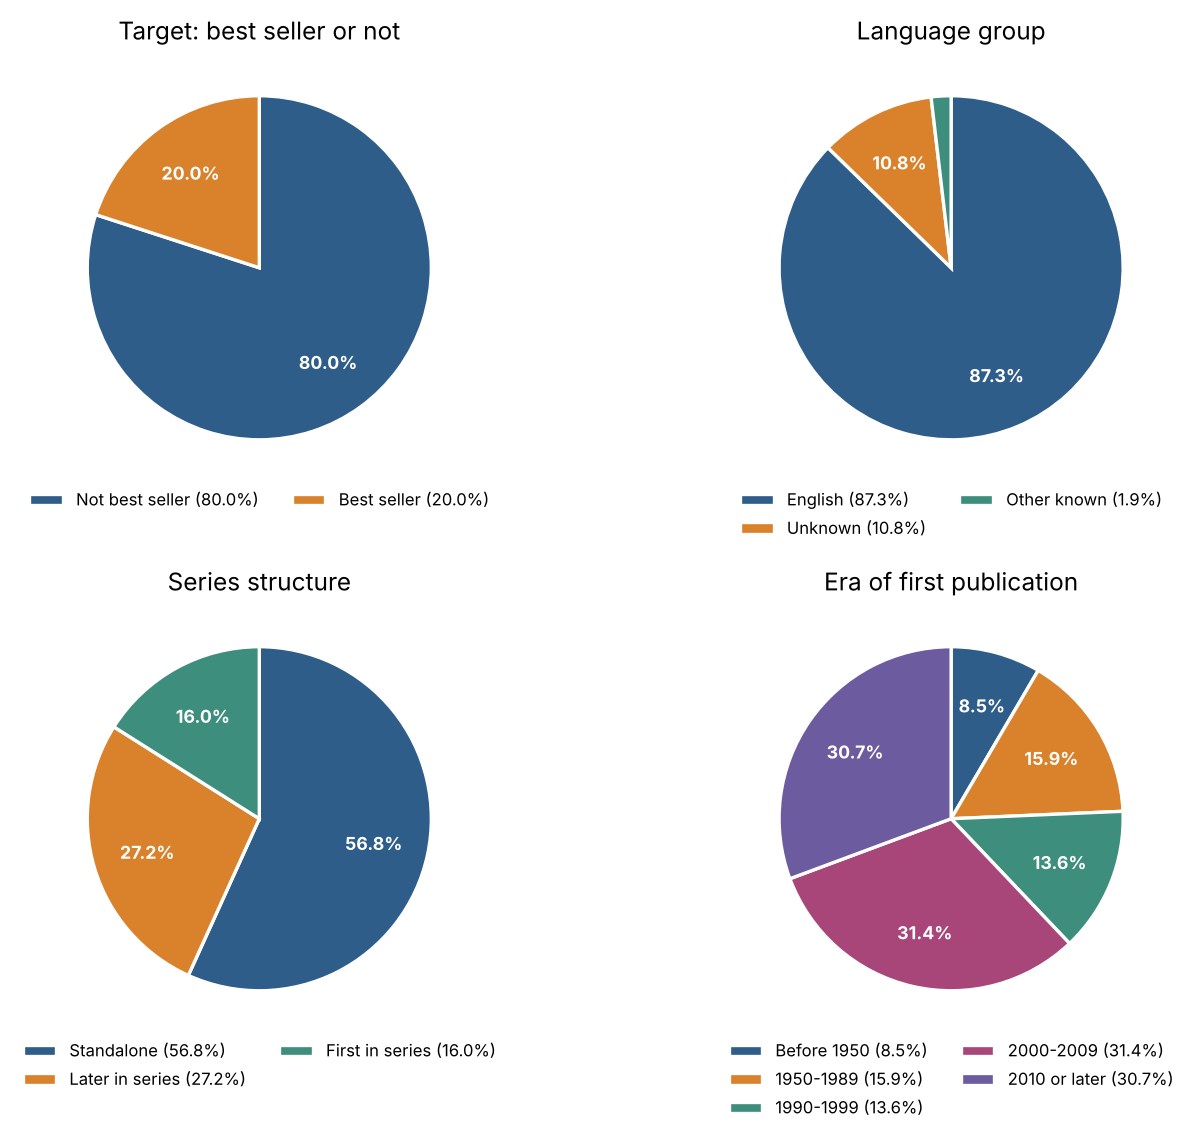

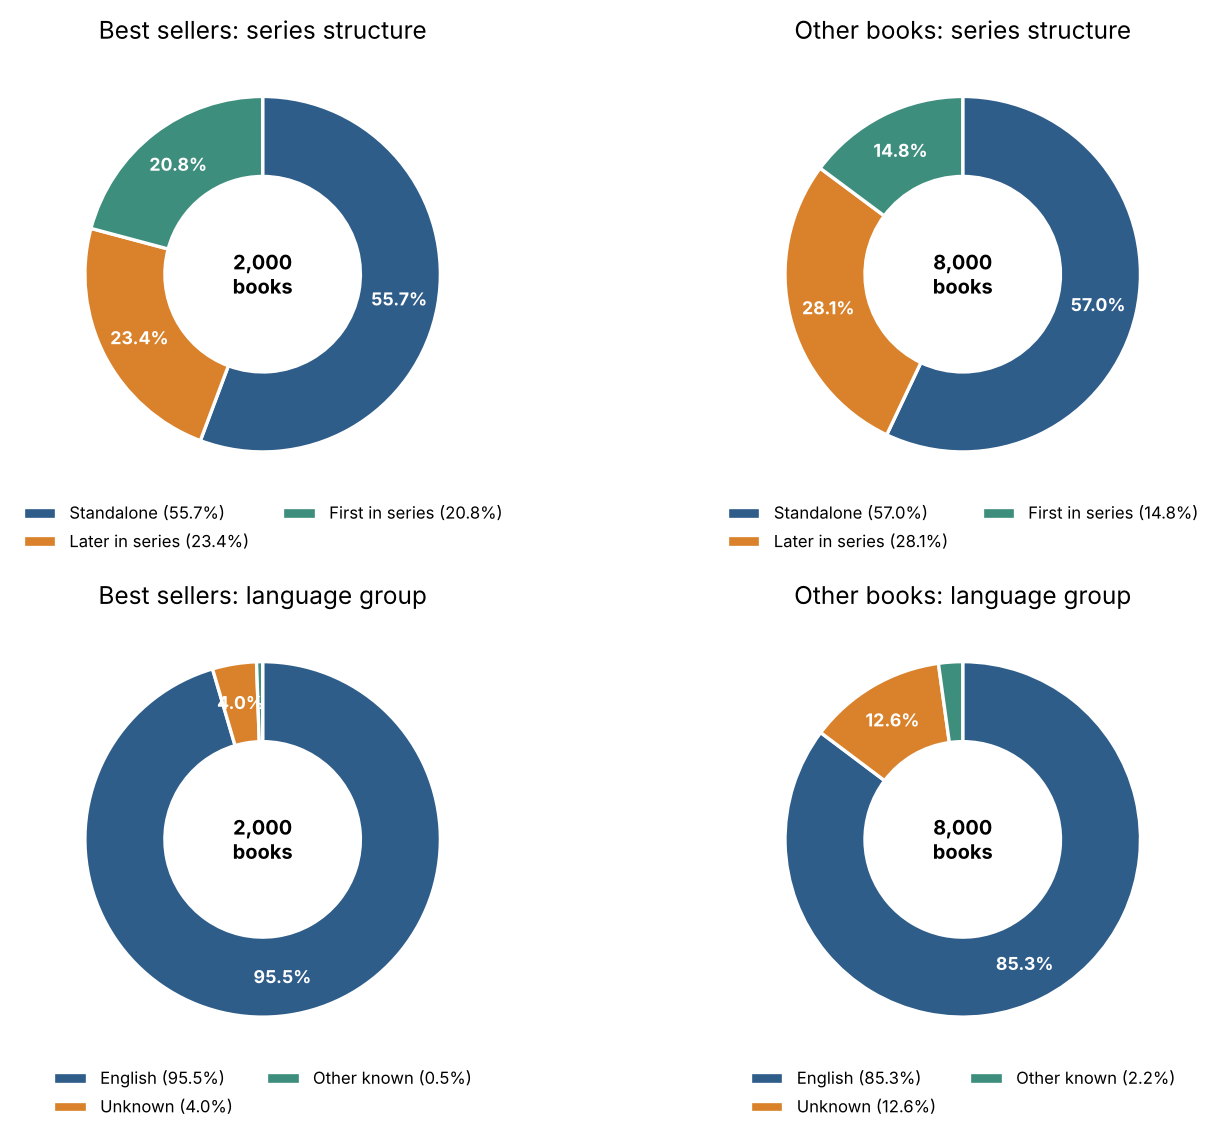

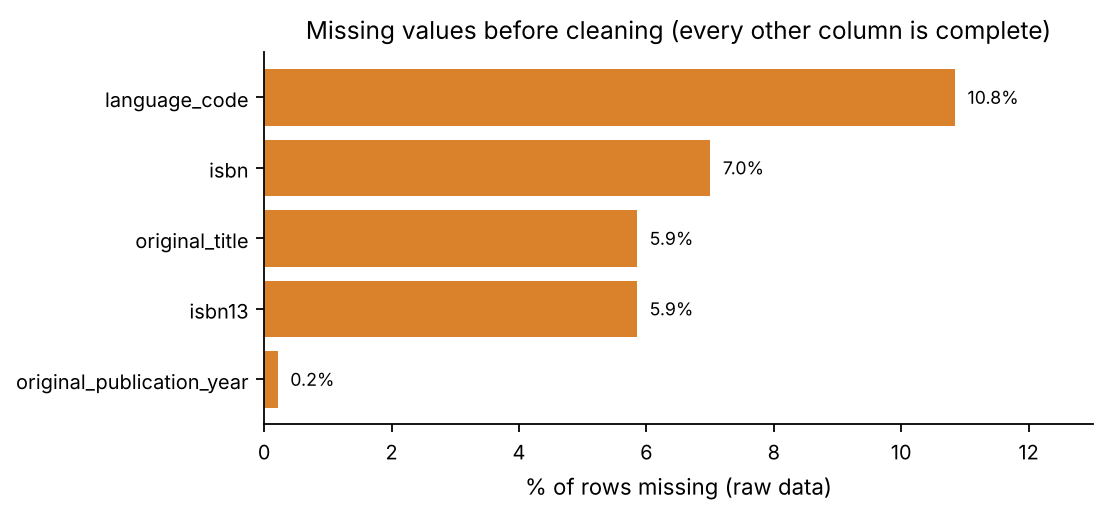

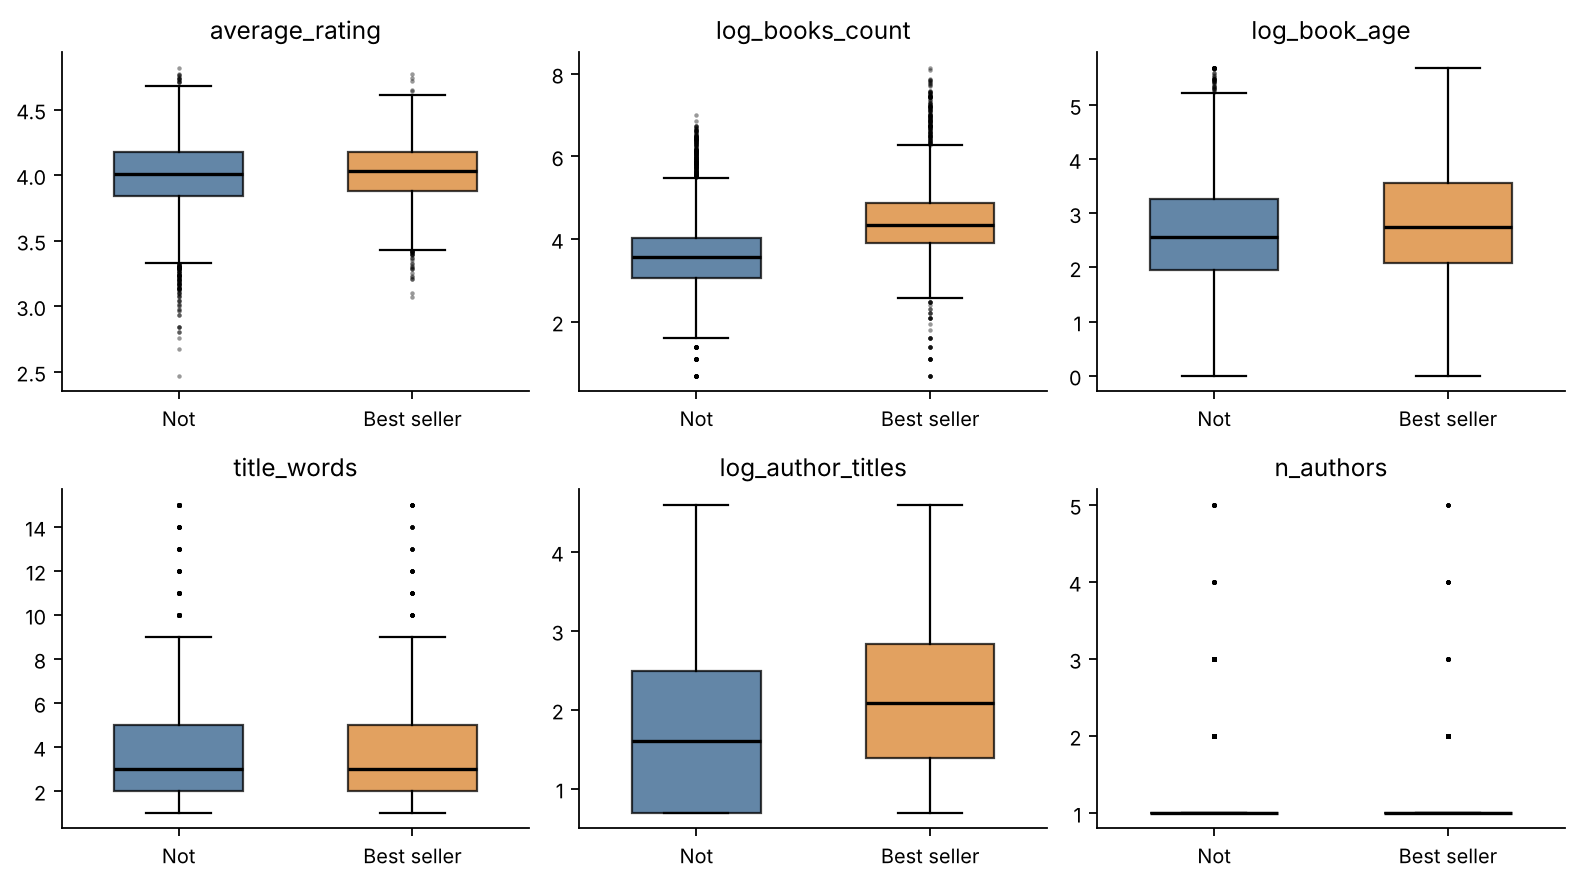

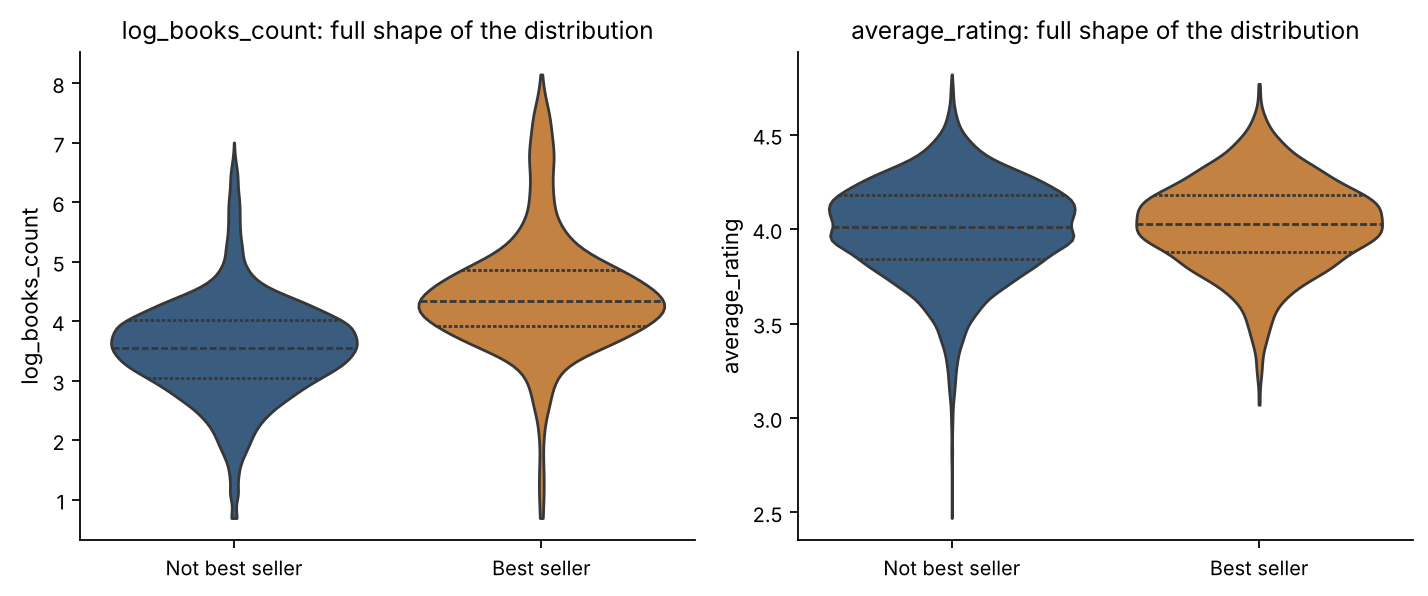

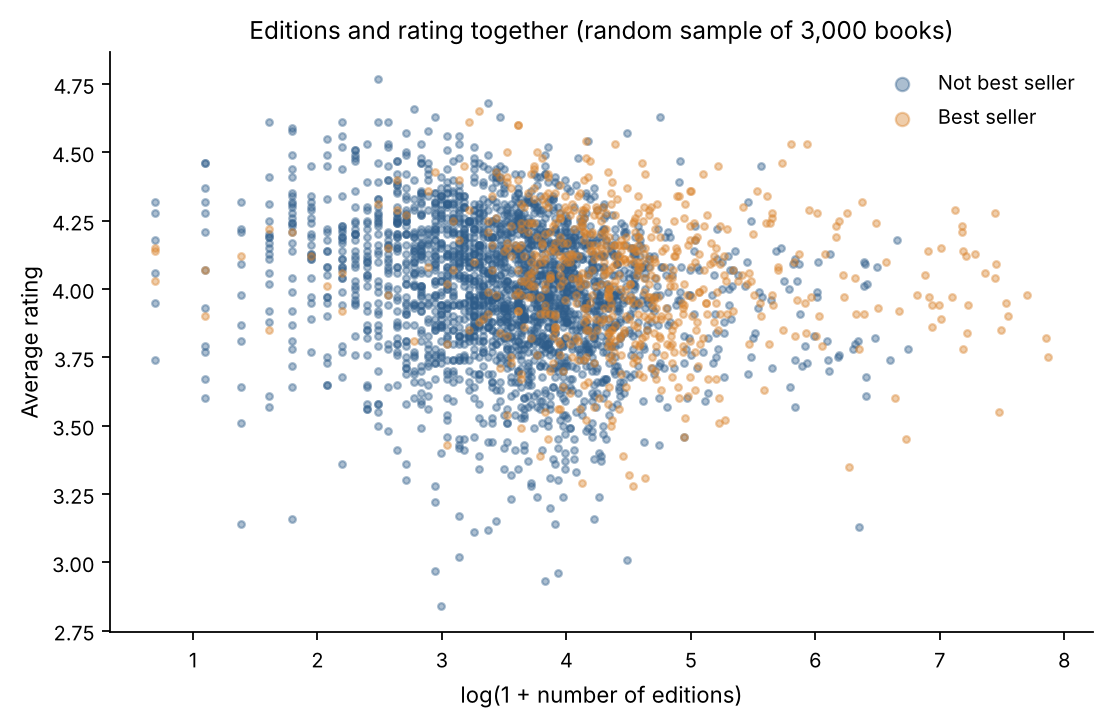

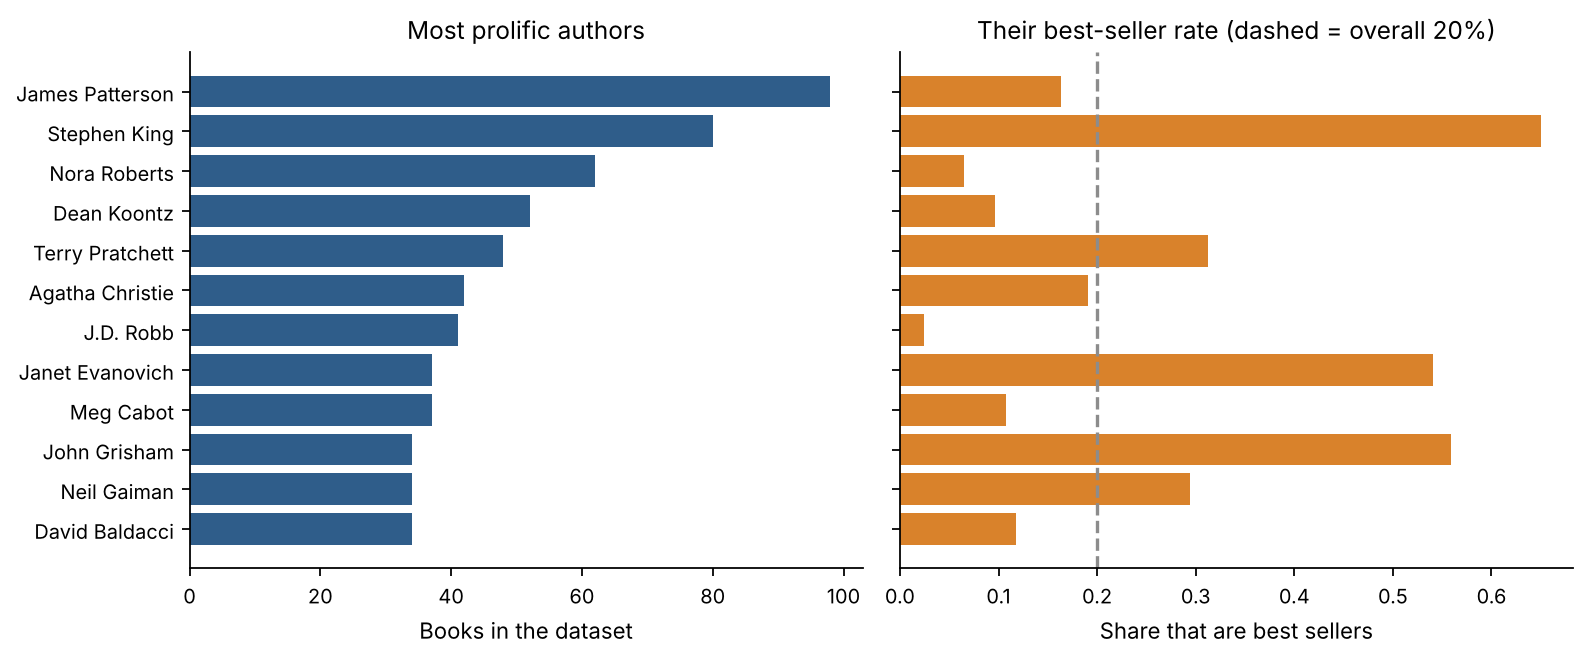

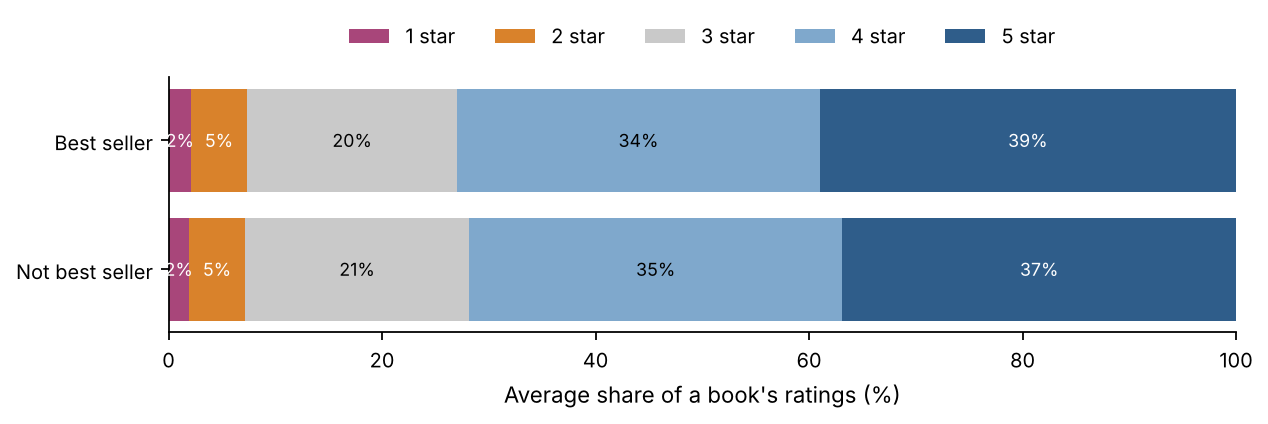

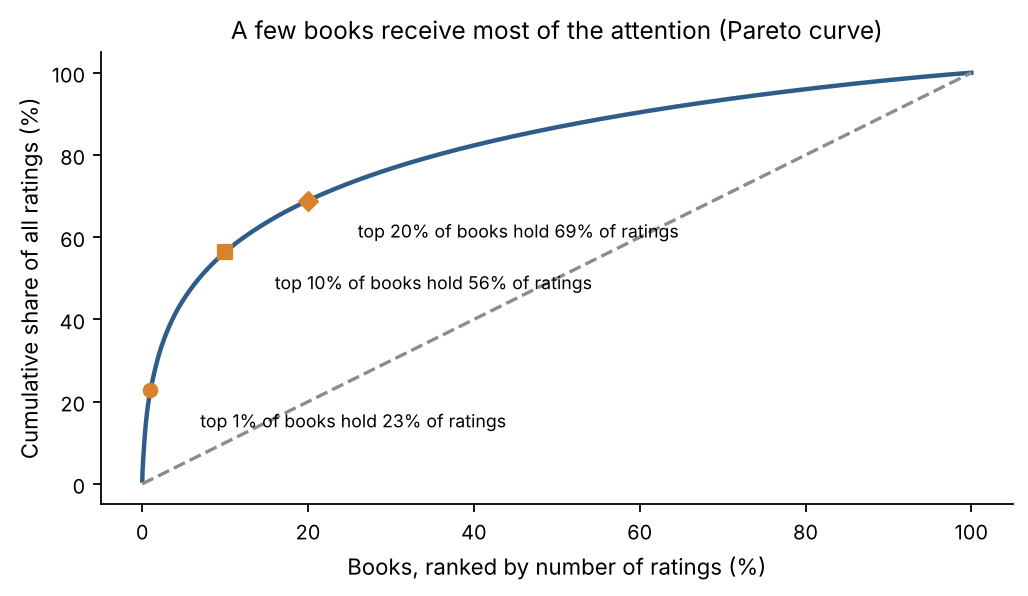

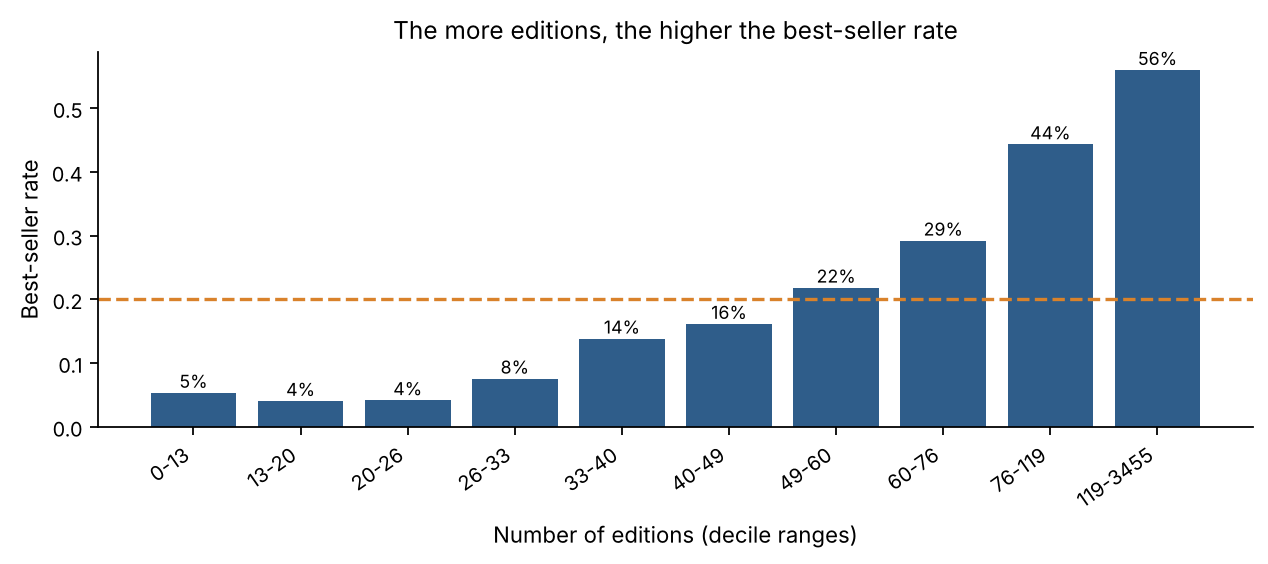

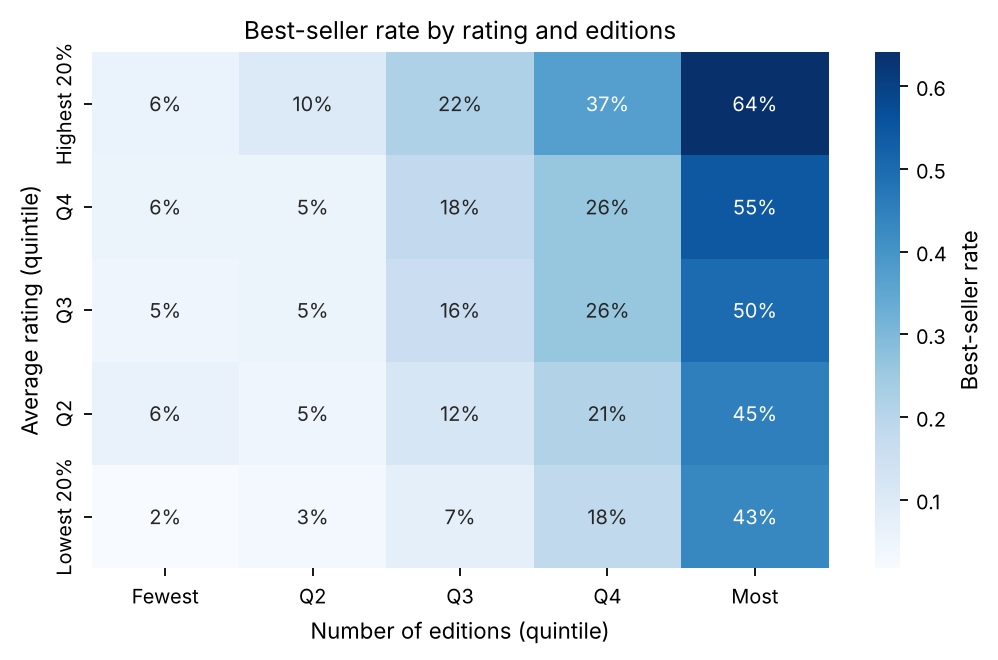

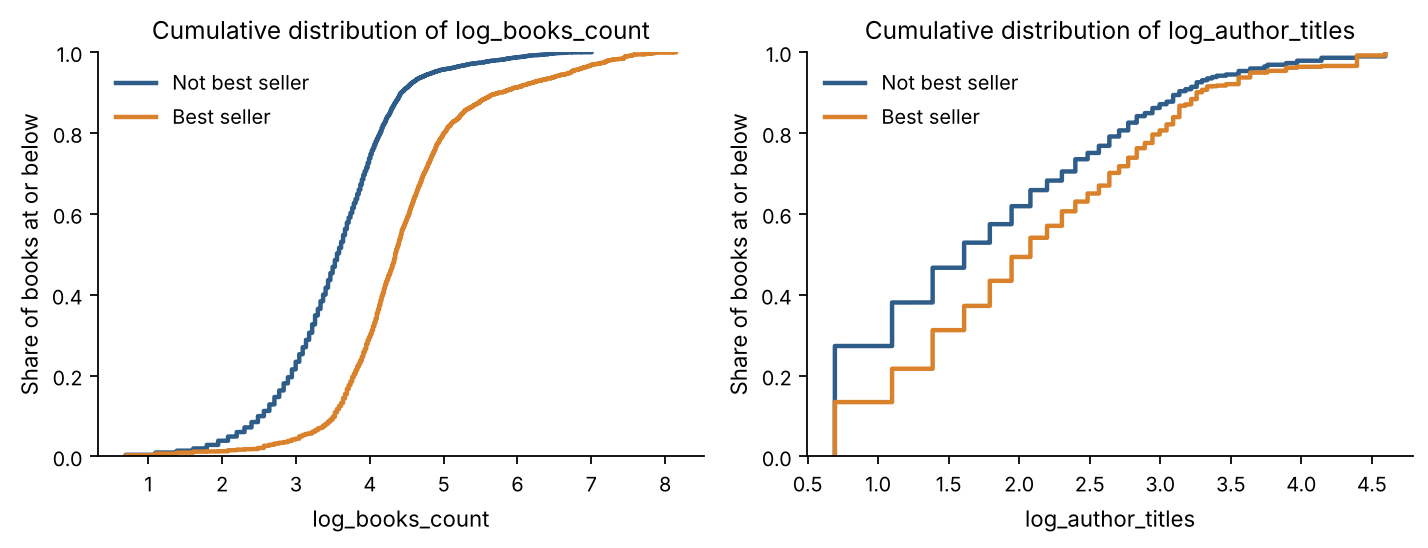

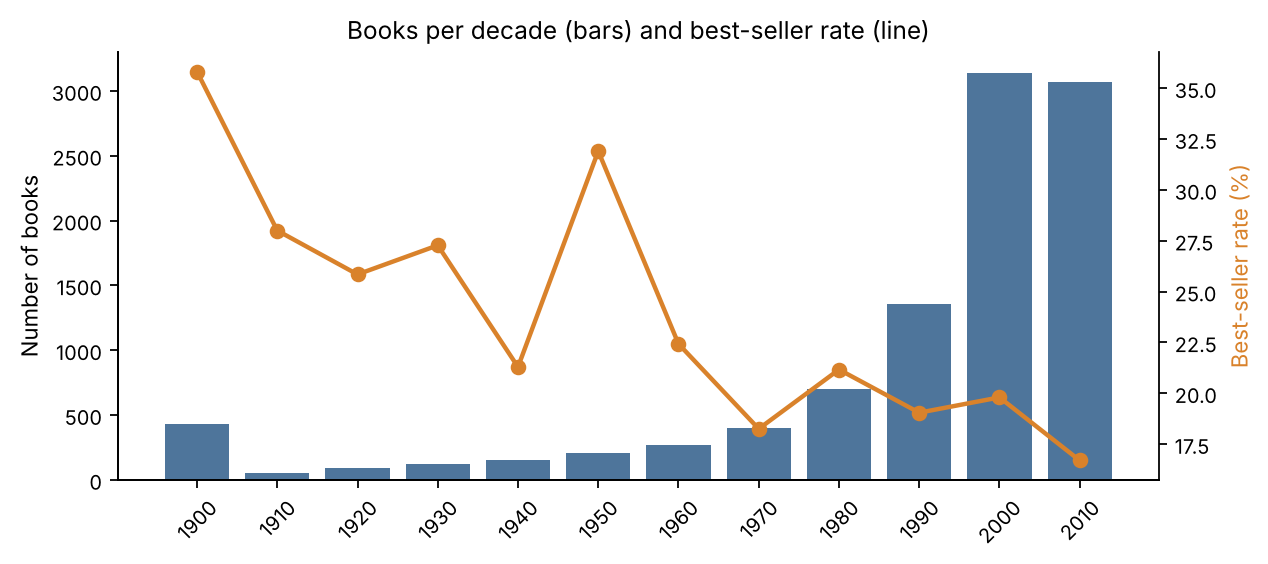

In [6]:
PAL = [BLUE, ORANGE, "#3E8E7E", "#A8467A", "#6C5B9E"]      # colour-blind-friendly, white text readable on all
EXTRA = {}                                                  # numbers from this section, saved for the report
cls_name = {0: "Not best seller", 1: "Best seller"}
bs = model_df["bestseller"].values

# Group labels used by several charts
lang_grp = np.where(df["lang_unknown"] == 1, "Unknown", np.where(df["lang_other"] == 1, "Other known", "English"))
series_grp = np.where(df["is_series_book1"] == 1, "First in series",
                      np.where(df["is_series"] == 1, "Later in series", "Standalone"))
era = pd.cut(df["original_publication_year"], [-3000, 1949, 1989, 1999, 2009, 2100],
             labels=["Before 1950", "1950-1989", "1990-1999", "2000-2009", "2010 or later"])


def pie(ax, labels, values, title, colors=None, donut=False):
    """Pie / donut. Small slices (< 4%) get no label on the wedge; every slice is named in the legend below."""
    wedge = dict(edgecolor="white", linewidth=1.5)
    if donut:
        wedge["width"] = 0.45
    cols = colors or PAL[:len(values)]
    total = float(np.sum(values))
    _, _, autot = ax.pie(values, colors=cols, autopct=lambda p: f"{p:.1f}%" if p >= 4 else "", startangle=90,
                         counterclock=False, wedgeprops=wedge, textprops={"fontsize": 8},
                         pctdistance=0.78 if donut else 0.68)
    for t in autot:
        t.set_color("white"); t.set_fontweight("bold"); t.set_fontsize(8)
    ax.legend([f"{l} ({v / total:.1%})" for l, v in zip(labels, values)], loc="upper center", bbox_to_anchor=(0.5, 0.02),
              frameon=False, fontsize=7.5, ncol=2)
    ax.set_title(title)


# --- 3.9a Pie charts: what is in the dataset? -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(9, 7.2))
pie(axes[0, 0], ["Not best seller", "Best seller"], [int((bs == 0).sum()), int((bs == 1).sum())],
    "Target: best seller or not", colors=[BLUE, ORANGE])
lg = pd.Series(lang_grp).value_counts()
pie(axes[0, 1], lg.index, lg.values, "Language group")
sg = pd.Series(series_grp).value_counts()
pie(axes[1, 0], sg.index, sg.values, "Series structure")
er = era.value_counts(sort=False)
pie(axes[1, 1], er.index, er.values, "Era of first publication")
savefig("fig13_pies_overview")
EXTRA["pie_target"] = {cls_name[k]: float(v) for k, v in pd.Series(bs).value_counts(normalize=True).items()}
EXTRA["pie_language"] = (lg / lg.sum()).round(4).to_dict()
EXTRA["pie_series"] = (sg / sg.sum()).round(4).to_dict()
EXTRA["pie_era"] = (er / er.sum()).round(4).to_dict()

# --- 3.9b Donuts: do best sellers look different from the rest? --------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(9, 7.2))
for j, (cls, lab) in enumerate([(1, "Best sellers"), (0, "Other books")]):
    m = bs == cls
    s_ = pd.Series(series_grp[m]).value_counts()
    pie(axes[0, j], s_.index, s_.values, f"{lab}: series structure", donut=True)
    axes[0, j].text(0, 0, f"{m.sum():,}\nbooks", ha="center", va="center", fontsize=9, fontweight="bold")
    l_ = pd.Series(lang_grp[m]).value_counts()
    pie(axes[1, j], l_.index, l_.values, f"{lab}: language group", donut=True)
    axes[1, j].text(0, 0, f"{m.sum():,}\nbooks", ha="center", va="center", fontsize=9, fontweight="bold")
    EXTRA[f"donut_series_{lab}"] = (s_ / s_.sum()).round(4).to_dict()
    EXTRA[f"donut_lang_{lab}"] = (l_ / l_.sum()).round(4).to_dict()
savefig("fig14_donuts_composition")

# --- 3.9c Missing values before cleaning ---------------------------------------------------------------------
miss = (raw.isna().mean() * 100)
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.barh(miss.index, miss.values, color=ORANGE)
for i, v in enumerate(miss.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% of rows missing (raw data)"); ax.set_title("Missing values before cleaning (every other column is complete)")
ax.set_xlim(0, max(miss.values) * 1.2)
savefig("fig15_missing_values")
EXTRA["missing_pct"] = miss.round(2).to_dict()

# --- 3.9d Box plots ---------------------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(10, 5.6))
for a, f in zip(axes.ravel(), num_feats):
    data = [model_df.loc[model_df.bestseller == c, f] for c in (0, 1)]
    bp = a.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color="black", lw=1.5),
                   flierprops=dict(marker=".", markersize=2, alpha=0.4), tick_labels=["Not", "Best seller"])
    for patch, col in zip(bp["boxes"], [BLUE, ORANGE]):
        patch.set_facecolor(col); patch.set_alpha(0.75)
    a.set_title(f)
savefig("fig16_boxplots")
EXTRA["median_by_class"] = {f: {cls_name[c]: float(model_df.loc[model_df.bestseller == c, f].median()) for c in (0, 1)}
                            for f in num_feats}
EXTRA["raw_editions_median"] = {cls_name[c]: float(df.loc[df.bestseller == c, "books_count"].median()) for c in (0, 1)}

# --- 3.9e Violin plots ---------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for a, f in zip(axes, ["log_books_count", "average_rating"]):
    sns.violinplot(data=model_df, x="bestseller", y=f, hue="bestseller", palette=[BLUE, ORANGE], inner="quartile",
                   legend=False, ax=a, cut=0)
    a.set_xticks([0, 1]); a.set_xticklabels(["Not best seller", "Best seller"]); a.set_xlabel("")
    a.set_title(f"{f}: full shape of the distribution")
savefig("fig17_violins")

# --- 3.9f Scatter: the two strongest signals together ---------------------------------------------------------
samp = model_df.sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 4.6))
for c, col in [(0, BLUE), (1, ORANGE)]:
    s_ = samp[samp.bestseller == c]
    ax.scatter(s_.log_books_count, s_.average_rating, s=9, alpha=0.4, color=col, label=cls_name[c])
ax.set_xlabel("log(1 + number of editions)"); ax.set_ylabel("Average rating")
ax.set_title("Editions and rating together (random sample of 3,000 books)"); ax.legend(frameon=False, markerscale=2)
savefig("fig18_scatter_editions_rating")

# --- 3.9g Most prolific authors ----------------------------------------------------------------------------------
top_a = first_author.value_counts().head(12)
a_rate = df.groupby(first_author)["bestseller"].mean().loc[top_a.index]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
axes[0].barh(top_a.index[::-1], top_a.values[::-1], color=BLUE); axes[0].set_xlabel("Books in the dataset")
axes[0].set_title("Most prolific authors")
axes[1].barh(a_rate.index[::-1], a_rate.values[::-1], color=ORANGE)
axes[1].axvline(bs.mean(), color=GREY, ls="--"); axes[1].set_xlabel("Share that are best sellers")
axes[1].set_title("Their best-seller rate (dashed = overall 20%)")
savefig("fig19_top_authors")
EXTRA["top_authors"] = [{"author": k, "books": int(top_a[k]), "rate": round(float(a_rate[k]), 3)} for k in top_a.index]

# --- 3.9h How do readers rate best sellers? (descriptive only - star counts are NOT model features) ----------
stars = raw[["ratings_1", "ratings_2", "ratings_3", "ratings_4", "ratings_5"]].div(raw["work_ratings_count"], axis=0)
star_mean = stars.groupby(df["bestseller"]).mean() * 100
fig, ax = plt.subplots(figsize=(8, 2.9))
star_cols = ["#A8467A", ORANGE, "#C9C9C9", "#7FA8CC", BLUE]
left = np.zeros(2)
for k, col in zip(range(5), star_cols):
    vals = star_mean.iloc[:, k].values
    ax.barh(["Not best seller", "Best seller"], vals, left=left, color=col, label=f"{k + 1} star")
    for i, v in enumerate(vals):
        ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white" if k in (0, 1, 4) else "black", fontsize=8)
    left += vals
ax.set_xlim(0, 100); ax.set_xlabel("Average share of a book's ratings (%)"); ax.legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.28))
savefig("fig20_star_distribution")
EXTRA["star_share"] = {cls_name[c]: star_mean.loc[c].round(2).tolist() for c in (0, 1)}

# --- 3.9i Pareto: how concentrated are ratings? -----------------------------------------------------------------
srt = np.sort(raw["work_ratings_count"].values)[::-1]
cum = np.cumsum(srt) / srt.sum()
xb = np.arange(1, len(srt) + 1) / len(srt) * 100
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(xb, cum * 100, color=BLUE, lw=2); ax.plot([0, 100], [0, 100], color=GREY, ls="--")
for pctb, mk in [(1, "o"), (10, "s"), (20, "D")]:
    y_ = cum[int(len(srt) * pctb / 100) - 1] * 100
    ax.scatter([pctb], [y_], color=ORANGE, zorder=3, marker=mk)
    ax.annotate(f"top {pctb}% of books hold {y_:.0f}% of ratings", (pctb, y_), xytext=(pctb + 6, y_ - 9), fontsize=8)
ax.set_xlabel("Books, ranked by number of ratings (%)"); ax.set_ylabel("Cumulative share of all ratings (%)")
ax.set_title("A few books receive most of the attention (Pareto curve)")
savefig("fig21_pareto")
EXTRA["pareto"] = {f"top_{p}pct": round(float(cum[int(len(srt) * p / 100) - 1] * 100), 1) for p in (1, 10, 20)}

# --- 3.9j Best-seller rate by number of editions (deciles) -----------------------------------------------------
ed_bin = pd.qcut(df["books_count"], 10, duplicates="drop")
ed_rate = df.groupby(ed_bin, observed=True)["bestseller"].mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
labs = [f"{int(iv.left) if iv.left > 0 else 0}-{int(iv.right)}" for iv in ed_rate.index]
ax.bar(range(len(ed_rate)), ed_rate.values, color=BLUE)
ax.axhline(bs.mean(), color=ORANGE, ls="--"); ax.set_xticks(range(len(ed_rate))); ax.set_xticklabels(labs, rotation=35, ha="right")
for i, v in enumerate(ed_rate.values):
    ax.text(i, v + 0.008, f"{v:.0%}", ha="center", fontsize=8)
ax.set_xlabel("Number of editions (decile ranges)"); ax.set_ylabel("Best-seller rate")
ax.set_title("The more editions, the higher the best-seller rate")
savefig("fig22_rate_by_editions")
EXTRA["rate_by_editions_decile"] = [{"range": l, "rate": round(float(v), 3)} for l, v in zip(labs, ed_rate.values)]

# --- 3.9k Heat-map: rating x editions -----------------------------------------------------------------------------
q_r = pd.qcut(df["average_rating"], 5, labels=["Lowest 20%", "Q2", "Q3", "Q4", "Highest 20%"])
q_e = pd.qcut(df["books_count"].rank(method="first"), 5, labels=["Fewest", "Q2", "Q3", "Q4", "Most"])
hm = df.pivot_table(index=q_r, columns=q_e, values="bestseller", aggfunc="mean", observed=True)
plt.figure(figsize=(6.5, 4.2))
sns.heatmap(hm.iloc[::-1], annot=True, fmt=".0%", cmap="Blues", cbar_kws={"label": "Best-seller rate"})
plt.xlabel("Number of editions (quintile)"); plt.ylabel("Average rating (quintile)")
plt.title("Best-seller rate by rating and editions")
savefig("fig23_heatmap_rating_editions")
EXTRA["heat_corner"] = {"most_editions_highest_rating": round(float(hm.loc["Highest 20%", "Most"]), 3),
                        "fewest_editions_lowest_rating": round(float(hm.loc["Lowest 20%", "Fewest"]), 3),
                        "fewest_editions_highest_rating": round(float(hm.loc["Highest 20%", "Fewest"]), 3),
                        "most_editions_lowest_rating": round(float(hm.loc["Lowest 20%", "Most"]), 3)}

# --- 3.9l ECDF -------------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for a, f in zip(axes, ["log_books_count", "log_author_titles"]):
    for c, col in [(0, BLUE), (1, ORANGE)]:
        sns.ecdfplot(model_df.loc[model_df.bestseller == c, f], ax=a, color=col, label=cls_name[c], lw=2)
    a.set_title(f"Cumulative distribution of {f}"); a.set_ylabel("Share of books at or below"); a.legend(frameon=False)
savefig("fig24_ecdf")

# --- 3.9m Pair plot -------------------------------------------------------------------------------------------------
pp_df = model_df.sample(1200, random_state=RANDOM_STATE)[["average_rating", "log_books_count", "log_book_age", "log_author_titles", "bestseller"]].copy()
pp_df["Class"] = pp_df["bestseller"].map(cls_name)
g = sns.pairplot(pp_df.drop(columns="bestseller"), hue="Class", palette={"Not best seller": BLUE, "Best seller": ORANGE},
                 corner=True, plot_kws=dict(alpha=0.35, s=10), diag_kind="kde", height=1.9)
g.figure.suptitle("Pair plot of the four strongest numeric features (1,200 random books)", y=1.0, fontsize=10)
g.savefig(f"{OUT_DIR}/fig25_pairplot.png", dpi=150, bbox_inches="tight"); plt.close("all")

# --- 3.9n Books per decade + best-seller rate ----------------------------------------------------------------------------
dec_all = model_df.groupby(decade)["bestseller"].agg(["mean", "size"])
dec_all = dec_all[dec_all["size"] >= 30]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(dec_all.index.astype(int).astype(str), dec_all["size"], color=BLUE, alpha=0.85)
ax.set_ylabel("Number of books"); plt.xticks(rotation=45)
ax2 = ax.twinx(); ax2.plot(dec_all.index.astype(int).astype(str), dec_all["mean"] * 100, color=ORANGE, marker="o", lw=2)
ax2.set_ylabel("Best-seller rate (%)", color=ORANGE); ax2.spines["right"].set_visible(True)
ax.set_title("Books per decade (bars) and best-seller rate (line)")
savefig("fig26_decade_counts_rate")
EXTRA["books_per_decade"] = {str(int(k)): int(v) for k, v in dec_all["size"].items()}

### EDA - what we learned
* **Class imbalance (80/20):** accuracy alone will be misleading (a model that always says
  "not a best seller" is already 80% accurate), so I will use precision, recall, F1, ROC-AUC and PR-AUC.
* **Number of editions (`log_books_count`)** and **author's number of titles** show the clearest separation.
* **Series books / first-in-series** have a higher best-seller rate.
* **Average rating** differs only slightly - being well liked and being widely read are different things.
* All VIF values are below 5 (language is coded with English as the reference group), so
  multicollinearity is not a problem for interpreting coefficients.

## 3b. Extended EDA: composition, spread, relationships and assumption checks
The first EDA looked at the target, the features and their correlations. This second pass adds:
* **composition** (pie / donut charts of how books are split by class, language, series and era),
* **spread and outliers** (box plots, violin plots, raw-versus-log comparisons),
* **relationships** (scatter, hexbin, pair plot, rank correlations, statistical tests),
* **concentration** (a Lorenz curve of ratings), and
* **logistic-regression assumptions** (is each continuous feature linear in the log-odds?).

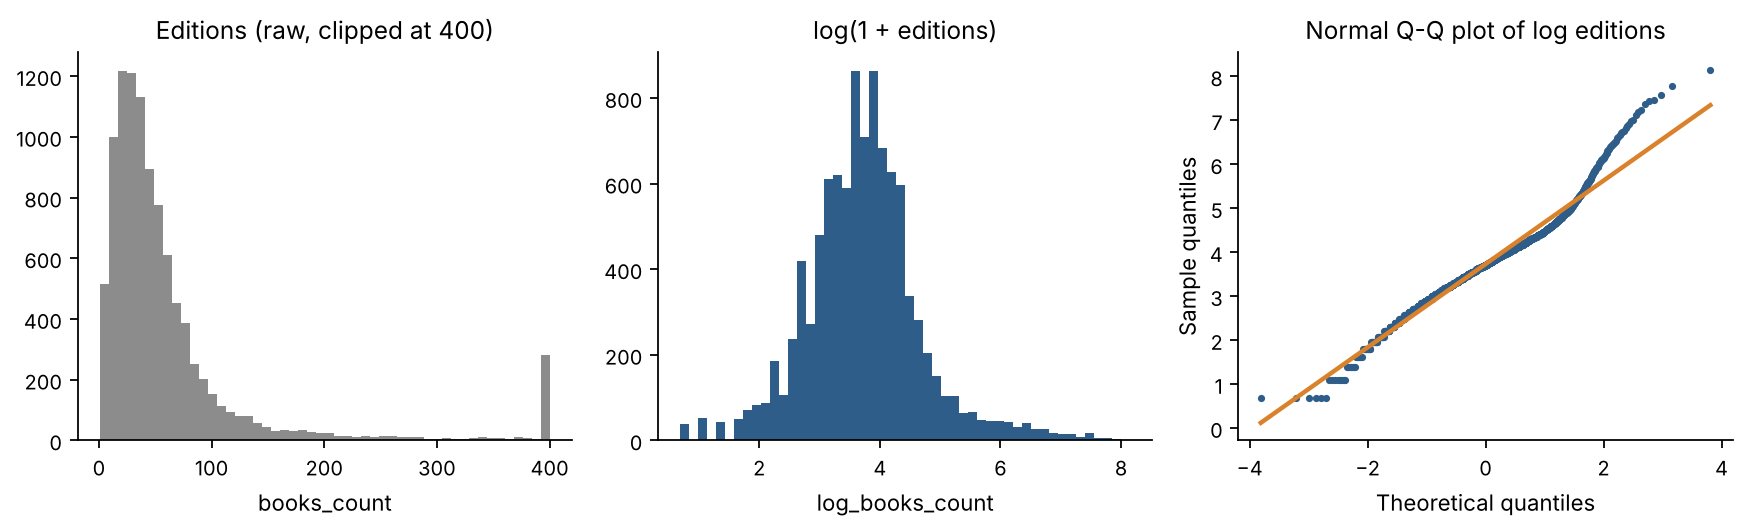

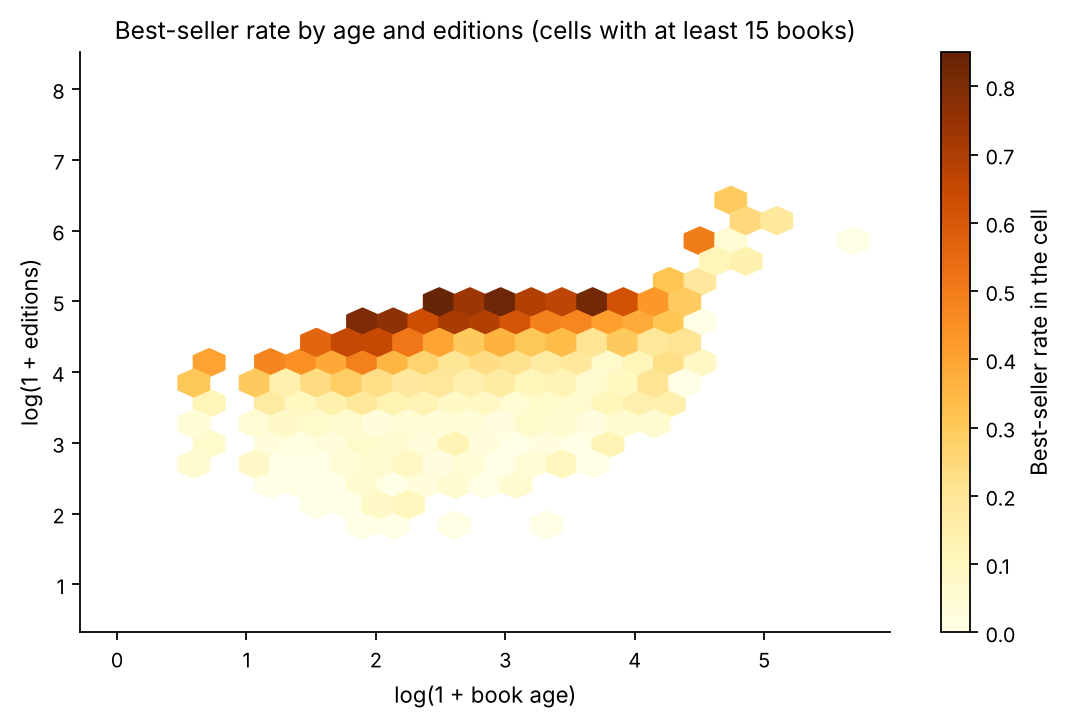

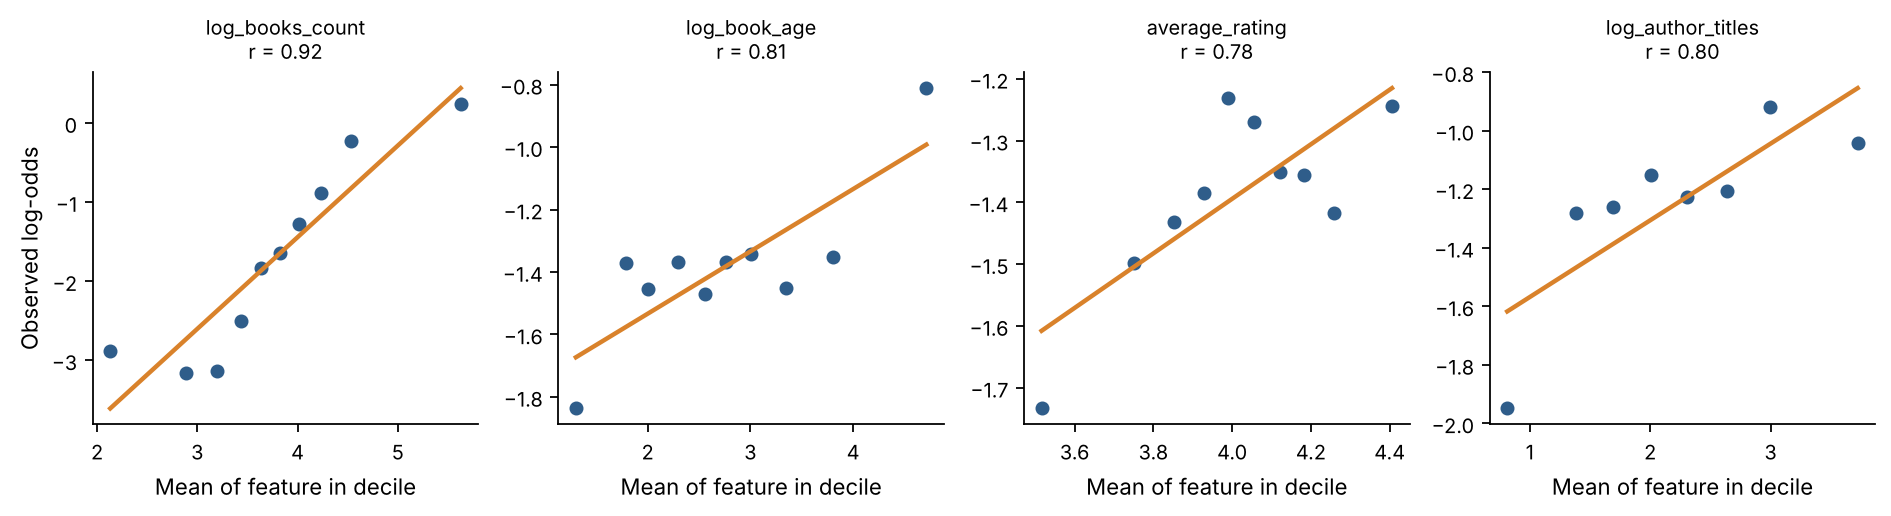

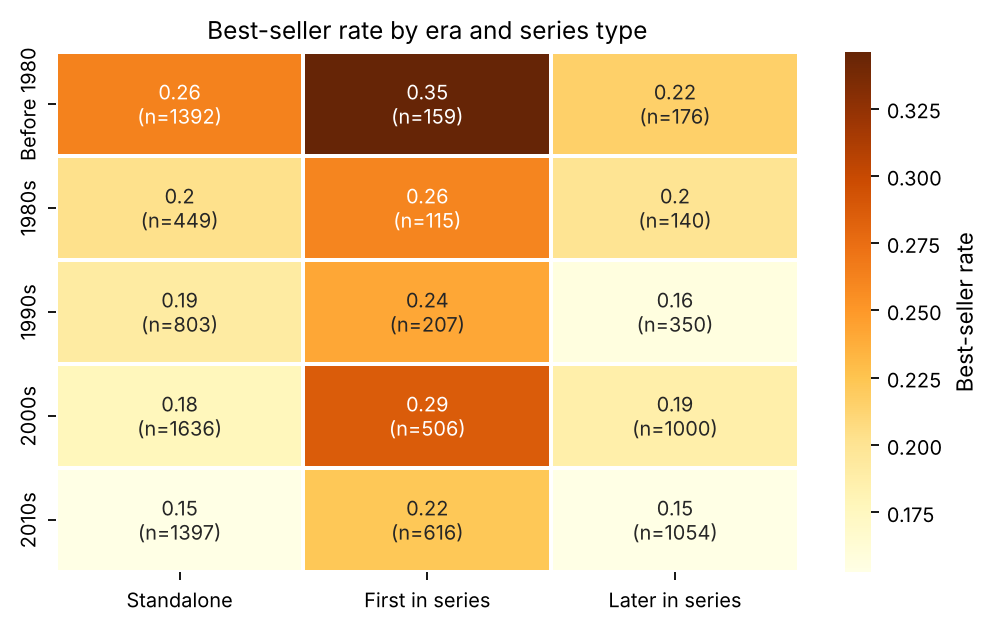

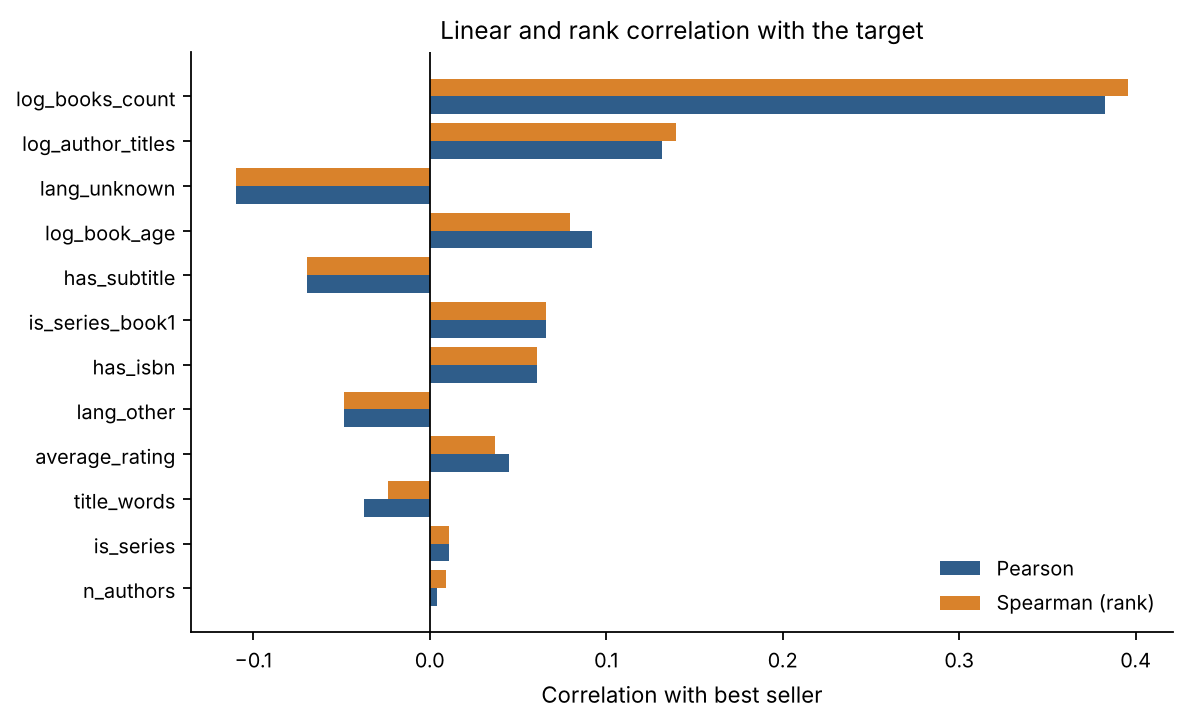

              feature            test     statistic  effect       p
0           is_series      chi-square  1.112400e+00  0.0105  0.2916
1     is_series_book1      chi-square  4.270310e+01  0.0653  0.0000
2          lang_other      chi-square  2.261450e+01  0.0476  0.0000
3        lang_unknown      chi-square  1.201358e+02  0.1096  0.0000
4            has_isbn      chi-square  3.631190e+01  0.0603  0.0000
5        has_subtitle      chi-square  4.757860e+01  0.0690  0.0000
6      average_rating  Mann-Whitney U  8.428709e+06  0.0536  0.0002
7     log_books_count  Mann-Whitney U  1.256977e+07  0.5712  0.0000
8        log_book_age  Mann-Whitney U  8.913960e+06  0.1142  0.0000
9   log_author_titles  Mann-Whitney U  9.595472e+06  0.1994  0.0000
10        title_words  Mann-Whitney U  7.731068e+06 -0.0336  0.0180
11          n_authors  Mann-Whitney U  8.072928e+06  0.0091  0.3714


In [7]:
EX = {}                                   # extra numbers collected here for the report
LANG = np.where(df["lang_unknown"] == 1, "Unknown", np.where(df["lang_other"] == 1, "Other known", "English"))
SERIES = np.where(df["is_series_book1"] == 1, "First in series",
                  np.where(df["is_series"] == 1, "Later in series", "Standalone"))
ERA = pd.cut(df["original_publication_year"], [-3000, 1979, 1989, 1999, 2009, 2100],
             labels=["Before 1980", "1980s", "1990s", "2000s", "2010s"])
df["lang_group"], df["series_type"], df["era"] = LANG, SERIES, ERA
best_mask = df["bestseller"] == 1


def donut(ax, counts, labels, colors, title, centre=None):
    """Draw a donut chart with a legend that shows each share as a percentage."""
    counts = np.asarray(counts, float)
    ax.pie(counts, colors=colors, startangle=90, counterclock=False,
           wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1.5))
    ax.set_title(title, fontsize=10)
    if centre:
        ax.text(0, 0, centre, ha="center", va="center", fontsize=11, fontweight="bold")
    ax.legend([f"{l} ({c / counts.sum():.1%})" for l, c in zip(labels, counts)], loc="upper center",
              bbox_to_anchor=(0.5, 0.03), frameon=False, fontsize=8)


ser_order = ["Standalone", "First in series", "Later in series"]      # order used by the heat map below

# --- 3b.7 Raw versus log scale for editions (skew and normality) ----------------------------------------------------
raw_bc = df["books_count"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].hist(raw_bc.clip(upper=400), bins=50, color=GREY)
axes[0].set_title("Editions (raw, clipped at 400)"); axes[0].set_xlabel("books_count")
axes[1].hist(df["log_books_count"], bins=50, color=BLUE)
axes[1].set_title("log(1 + editions)"); axes[1].set_xlabel("log_books_count")
(osm, osr), (slope, intercept, r_qq) = stats.probplot(df["log_books_count"], dist="norm")
idx_q = np.linspace(0, len(osm) - 1, 1500).astype(int)
axes[2].scatter(osm[idx_q], osr[idx_q], s=5, color=BLUE)
axes[2].plot(osm, slope * osm + intercept, color=ORANGE, lw=2)
axes[2].set_title("Normal Q-Q plot of log editions"); axes[2].set_xlabel("Theoretical quantiles"); axes[2].set_ylabel("Sample quantiles")
savefig("fig20_raw_vs_log")
EX["skew"] = {"books_count_raw": round(float(stats.skew(raw_bc)), 2), "log_books_count": round(float(stats.skew(df["log_books_count"])), 2),
              "age_raw": round(float(stats.skew(age)), 2), "log_book_age": round(float(stats.skew(df["log_book_age"])), 2)}

# --- 3b.9 Hexbin: best-seller rate over age and editions ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 4.6))
hb = ax.hexbin(model_df["log_book_age"], model_df["log_books_count"], C=model_df["bestseller"], gridsize=24,
               reduce_C_function=np.mean, mincnt=15, cmap="YlOrBr")
plt.colorbar(hb, ax=ax, label="Best-seller rate in the cell")
ax.set_xlabel("log(1 + book age)"); ax.set_ylabel("log(1 + editions)")
ax.set_title("Best-seller rate by age and editions (cells with at least 15 books)")
savefig("fig22_hexbin")

# --- 3b.12 Linearity of the log-odds (a logistic-regression assumption) -------------------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
EX["linearity_r"] = {}
for a, f in zip(axes, ["log_books_count", "log_book_age", "average_rating", "log_author_titles"]):
    bins = pd.qcut(model_df[f], 10, duplicates="drop")
    gb = model_df.groupby(bins, observed=True).agg(x=(f, "mean"), p=("bestseller", "mean"))
    logit = np.log(gb["p"].clip(1e-3, 1 - 1e-3) / (1 - gb["p"].clip(1e-3, 1 - 1e-3)))
    a.scatter(gb["x"], logit, color=BLUE, s=28)
    m_, c_ = np.polyfit(gb["x"], logit, 1)
    a.plot(gb["x"], m_ * gb["x"] + c_, color=ORANGE, lw=2)
    r_ = float(np.corrcoef(gb["x"], logit)[0, 1]); EX["linearity_r"][f] = round(r_, 3)
    a.set_title(f"{f}\nr = {r_:.2f}", fontsize=9); a.set_xlabel("Mean of feature in decile")
axes[0].set_ylabel("Observed log-odds")
savefig("fig25_linearity")

# --- 3b.15 Best-seller rate by era and series type (heat map) ---------------------------------------------------------------------------
pv = df.pivot_table(index="era", columns="series_type", values="bestseller", aggfunc="mean", observed=True)[ser_order]
cnt = df.pivot_table(index="era", columns="series_type", values="bestseller", aggfunc="size", observed=True)[ser_order]
annot = pv.round(2).astype(str) + "\n(n=" + cnt.astype(str) + ")"
plt.figure(figsize=(6.4, 4.0))
sns.heatmap(pv, annot=annot, fmt="", cmap="YlOrBr", cbar_kws={"label": "Best-seller rate"}, linewidths=1, linecolor="white")
plt.title("Best-seller rate by era and series type"); plt.ylabel(""); plt.xlabel("")
savefig("fig28_era_series_heatmap")
EX["era_series_rates"] = {str(i): {c: round(float(v), 3) for c, v in row.items()} for i, row in pv.iterrows()}

# --- 3b.17 Pearson versus Spearman correlation with the target ---------------------------------------------------------------------------------
pear = model_df[FEATURES].corrwith(model_df["bestseller"])
spear = model_df[FEATURES].corrwith(model_df["bestseller"], method="spearman")
order_c = pear.abs().sort_values().index
fig, ax = plt.subplots(figsize=(7.5, 4.6))
yy = np.arange(len(order_c))
ax.barh(yy - 0.2, pear[order_c], 0.4, color=BLUE, label="Pearson")
ax.barh(yy + 0.2, spear[order_c], 0.4, color=ORANGE, label="Spearman (rank)")
ax.set_yticks(yy); ax.set_yticklabels(order_c); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlation with best seller"); ax.legend(frameon=False); ax.set_title("Linear and rank correlation with the target")
savefig("fig30_pearson_spearman")
EX["spearman"] = {k: round(float(v), 3) for k, v in spear.items()}

# --- 3b.18 Hypothesis tests for each feature against the target ------------------------------------------------------------------------------------
tests = []
for f in ["is_series", "is_series_book1", "lang_other", "lang_unknown", "has_isbn", "has_subtitle"]:
    ct = pd.crosstab(model_df[f], model_df["bestseller"])
    chi2, p_chi, _, _ = stats.chi2_contingency(ct)
    tests.append({"feature": f, "test": "chi-square", "statistic": float(chi2), "effect": float(np.sqrt(chi2 / len(model_df))), "p": float(p_chi)})
for f in ["average_rating", "log_books_count", "log_book_age", "log_author_titles", "title_words", "n_authors"]:
    x1 = model_df.loc[model_df.bestseller == 1, f]; x0 = model_df.loc[model_df.bestseller == 0, f]
    u, p_u = stats.mannwhitneyu(x1, x0, alternative="two-sided")
    tests.append({"feature": f, "test": "Mann-Whitney U", "statistic": float(u), "effect": float(2 * u / (len(x1) * len(x0)) - 1), "p": float(p_u)})
tests_df = pd.DataFrame(tests)
print(tests_df.round(4))
EX["tests"] = tests_df.round(5).to_dict("records")
RESULTS["extra_eda_b"] = EX

## 4. Train / test split and scaling
* **Stratified 80/20 split** keeps the 20% best-seller rate in both parts.
* The test set is **locked away** and only used once at the end.
* Features are **standardised** (mean 0, sd 1) using **training data only**
  (using the test set would be data leakage). Scaling makes gradient descent converge quickly
  and lets coefficients be compared on one scale.

In [8]:
X_all = model_df[FEATURES].values.astype(float)
y_all = model_df["bestseller"].values.astype(float)
idx_train, idx_test = train_test_split(np.arange(len(model_df)), test_size=0.20,
                                       stratify=y_all, random_state=RANDOM_STATE)
X_train_raw, X_test_raw = X_all[idx_train], X_all[idx_test]
y_train, y_test = y_all[idx_train], y_all[idx_test]
print(f"Train: {len(y_train):,} rows ({y_train.mean():.1%} best sellers) | "
      f"Test: {len(y_test):,} rows ({y_test.mean():.1%} best sellers)")


def fit_scaler(X):
    mu, sd = X.mean(axis=0), X.std(axis=0)
    sd[sd == 0] = 1.0
    return mu, sd


mu, sd = fit_scaler(X_train_raw)                 # learned from TRAIN only
X_train = (X_train_raw - mu) / sd
X_test = (X_test_raw - mu) / sd
RESULTS["split"] = {"n_train": int(len(y_train)), "n_test": int(len(y_test)),
                    "train_rate": float(y_train.mean()), "test_rate": float(y_test.mean())}

Train: 8,000 rows (20.0% best sellers) | Test: 2,000 rows (20.0% best sellers)


## 5. Logistic regression written from scratch
**Model:** probability of best seller  p = sigmoid(w.x + b), where sigmoid(z) = 1 / (1 + e^-z)

**Loss** (binary cross-entropy / log-loss, with optional L2 penalty and class weights):
L = -mean( s_i [ y log p + (1-y) log(1-p) ] ) + (lambda/2) ||w||^2

**Gradient descent update:** w <- w - lr * dL/dw, where dL/dw = X^T (s*(p - y)) / n + lambda*w

I also write **Newton-Raphson (IRLS)** to get standard errors and **p-values** (Wald test),
which are needed for backward / forward feature selection.

In [9]:
def sigmoid(z):
    """Numerically stable sigmoid (avoids overflow in exp for large |z|)."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


class LogisticRegressionScratch:
    """Binary logistic regression trained with batch gradient descent (NumPy only)."""

    def __init__(self, lr=0.1, n_iter=1000, l2=0.0, class_weight=None, tol=1e-9):
        self.lr = lr                      # learning rate (step size)
        self.n_iter = n_iter              # maximum number of gradient steps
        self.l2 = l2                      # L2 (ridge) penalty strength
        self.class_weight = class_weight  # None or 'balanced'
        self.tol = tol                    # stop early when the loss stops improving
        self.w, self.b, self.loss_history = None, 0.0, []

    def _sample_weights(self, y):
        if self.class_weight == "balanced":          # rare class counts more
            n, n_pos = len(y), y.sum()
            w_pos, w_neg = n / (2 * n_pos), n / (2 * (n - n_pos))
            return np.where(y == 1, w_pos, w_neg)
        return np.ones_like(y)

    def fit(self, X, y):
        n, d = X.shape
        self.w, self.b, self.loss_history = np.zeros(d), 0.0, []
        sw = self._sample_weights(y)
        for _ in range(self.n_iter):
            p = sigmoid(X @ self.w + self.b)                     # 1. forward pass
            eps = 1e-12
            loss = (-np.mean(sw * (y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)))
                    + 0.5 * self.l2 * (self.w @ self.w))         # 2. loss
            self.loss_history.append(loss)
            err = sw * (p - y)                                   # 3. gradient
            grad_w = X.T @ err / n + self.l2 * self.w            #    (intercept is not penalised)
            grad_b = err.mean()
            self.w -= self.lr * grad_w                           # 4. update
            self.b -= self.lr * grad_b
            if len(self.loss_history) > 1 and abs(self.loss_history[-2] - loss) < self.tol:
                break                                            # converged
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def newton_logit(X, y, n_iter=50, tol=1e-9):
    """Un-penalised logistic regression by Newton-Raphson, returning coefficients,
    standard errors, z statistics and two-sided p-values (Wald test)."""
    Xd = np.column_stack([np.ones(len(X)), X])        # first column = intercept
    beta = np.zeros(Xd.shape[1])
    for _ in range(n_iter):
        p = sigmoid(Xd @ beta)
        W = p * (1 - p)
        H = Xd.T @ (Xd * W[:, None])                  # Hessian (Fisher information)
        step = np.linalg.solve(H, Xd.T @ (y - p))
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    cov = np.linalg.inv(H)                            # covariance matrix of the estimates
    se = np.sqrt(np.diag(cov))
    z = beta / se
    pvals = 2 * (1 - stats.norm.cdf(np.abs(z)))
    return pd.DataFrame({"coef": beta, "se": se, "z": z, "p_value": pvals})

## 6. Feature selection using p-values
Plan: fit an un-penalised model, then
* **Backward elimination:** start with all features, repeatedly drop the least significant (p > 0.05).
* **Forward selection:** start empty, repeatedly add the most significant feature (p < 0.05).
If both methods agree the selection is robust. Done on **training data only**.

FULL MODEL (all 12 features):
                      coef      se        z  p_value
intercept         -1.9349  0.0414 -46.7326   0.0000
average_rating     0.4567  0.0375  12.1637   0.0000
log_books_count    1.6904  0.0551  30.6537   0.0000
log_book_age      -0.7014  0.0432 -16.2532   0.0000
lang_other        -0.2441  0.0538  -4.5387   0.0000
lang_unknown      -0.2868  0.0455  -6.3027   0.0000
has_isbn           0.0894  0.0407   2.1974   0.0280
is_series         -0.3271  0.0448  -7.2942   0.0000
is_series_book1    0.4053  0.0373  10.8708   0.0000
title_words        0.1547  0.0500   3.0922   0.0020
has_subtitle      -0.1406  0.0532  -2.6424   0.0082
n_authors         -0.1323  0.0397  -3.3316   0.0009
log_author_titles  0.2193  0.0350   6.2624   0.0000



=== alpha = 0.05 ===
Backward removed (in order): nothing
Backward kept  : ['average_rating', 'log_books_count', 'log_book_age', 'lang_other', 'lang_unknown', 'has_isbn', 'is_series', 'is_series_book1', 'title_words', 'has_subtitle', 'n_authors', 'log_author_titles']
Forward added  : [('log_books_count', '1.0e-16'), ('average_rating', '1.0e-16'), ('log_book_age', '1.0e-16'), ('is_series_book1', '1.0e-16'), ('lang_unknown', '1.2e-08'), ('is_series', '2.8e-07'), ('log_author_titles', '1.2e-10'), ('lang_other', '2.5e-06'), ('n_authors', '5.7e-04'), ('has_isbn', '2.3e-02')]
Forward kept   : ['log_books_count', 'average_rating', 'log_book_age', 'is_series_book1', 'lang_unknown', 'is_series', 'log_author_titles', 'lang_other', 'n_authors', 'has_isbn']
Methods agree  : False



=== alpha = 0.01 ===
Backward removed (in order): [('has_isbn', 0.028)]
Backward kept  : ['average_rating', 'log_books_count', 'log_book_age', 'lang_other', 'lang_unknown', 'is_series', 'is_series_book1', 'title_words', 'has_subtitle', 'n_authors', 'log_author_titles']
Forward added  : [('log_books_count', '1.0e-16'), ('average_rating', '1.0e-16'), ('log_book_age', '1.0e-16'), ('is_series_book1', '1.0e-16'), ('lang_unknown', '1.2e-08'), ('is_series', '2.8e-07'), ('log_author_titles', '1.2e-10'), ('lang_other', '2.5e-06'), ('n_authors', '5.7e-04')]
Forward kept   : ['log_books_count', 'average_rating', 'log_book_age', 'is_series_book1', 'lang_unknown', 'is_series', 'log_author_titles', 'lang_other', 'n_authors']
Methods agree  : False

FINAL FEATURES ( 11 ): ['average_rating', 'log_books_count', 'log_book_age', 'lang_other', 'lang_unknown', 'is_series', 'is_series_book1', 'title_words', 'has_subtitle', 'n_authors', 'log_author_titles']
Dropped: ['has_isbn']


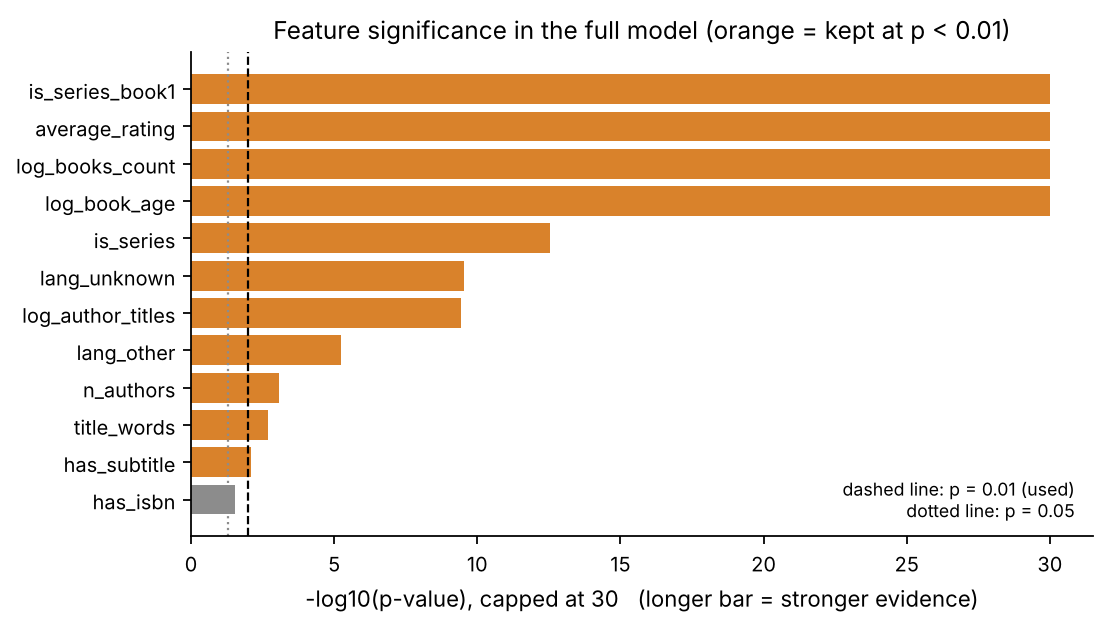

In [10]:
ALPHA_MAIN = 0.01          # main significance level (see note below)
ALPHA_CONVENTIONAL = 0.05  # reported as a sensitivity check
# Why 0.01? (1) 12 features are tested at once, so a stricter level guards against false positives
# (Bonferroni would suggest 0.05/12 = 0.004); (2) with 8,000 rows even tiny effects get p < 0.05.
col_idx = {f: i for i, f in enumerate(FEATURES)}


def fit_subset(features):
    cols = [col_idx[f] for f in features]
    res = newton_logit(X_train[:, cols], y_train)
    res.index = ["intercept"] + list(features)
    return res


def backward_elimination(alpha):
    """Start with every feature; repeatedly drop the one with the largest p-value while p > alpha."""
    current, log = list(FEATURES), []
    while True:
        pv = fit_subset(current)["p_value"].drop("intercept")
        worst = pv.idxmax()
        if pv[worst] > alpha:
            log.append({"removed": worst, "p_value": float(pv[worst]), "remaining": len(current) - 1})
            current.remove(worst)
        else:
            return current, log


def forward_selection(alpha):
    """Start empty; repeatedly add the candidate with the smallest p-value while p < alpha."""
    selected, log = [], []
    while True:
        best_feat, best_p = None, 1.0
        for cand in [f for f in FEATURES if f not in selected]:
            p_cand = fit_subset(selected + [cand]).loc[cand, "p_value"]
            if p_cand < best_p:
                best_feat, best_p = cand, p_cand
        if best_feat is not None and best_p < alpha:
            selected.append(best_feat)
            log.append({"added": best_feat, "p_value": float(best_p)})
        else:
            return selected, log


# --- Full model p-values ------------------------------------------------------------
full_fit = fit_subset(FEATURES)
print("FULL MODEL (all 12 features):\n", full_fit.round(4))
RESULTS["full_model_pvalues"] = full_fit.round(5).reset_index().rename(columns={"index": "term"}).to_dict("records")

fs = {}
for alpha in (ALPHA_CONVENTIONAL, ALPHA_MAIN):
    bsel, blog = backward_elimination(alpha)
    fsel, flog = forward_selection(alpha)
    fs[alpha] = {"backward_selected": bsel, "backward_log": blog, "forward_selected": fsel, "forward_log": flog,
                 "agree": set(bsel) == set(fsel)}
    print(f"\n=== alpha = {alpha} ===")
    print("Backward removed (in order):", [(x["removed"], round(x["p_value"], 4)) for x in blog] or "nothing")
    print("Backward kept  :", bsel)
    print("Forward added  :", [(x["added"], f"{max(x['p_value'], 1e-16):.1e}") for x in flog])
    print("Forward kept   :", fsel)
    print("Methods agree  :", fs[alpha]["agree"])

ALPHA = ALPHA_MAIN
# Final set = backward elimination at alpha 0.01. Backward is preferred because it judges every feature
# *given all the others*, so it keeps features that only matter in combination (forward selection can miss these).
SELECTED = [f for f in FEATURES if f in fs[ALPHA_MAIN]["backward_selected"]]
print("\nFINAL FEATURES (", len(SELECTED), "):", SELECTED)
print("Dropped:", [f for f in FEATURES if f not in SELECTED])
RESULTS["feature_selection"] = {"alpha_main": ALPHA_MAIN, "alpha_conventional": ALPHA_CONVENTIONAL,
                                "by_alpha": {str(k): v for k, v in fs.items()},
                                "final": SELECTED, "dropped": [f for f in FEATURES if f not in SELECTED]}

# Visual: significance of every candidate feature in the full model
pv_full = full_fit["p_value"].drop("intercept").clip(lower=1e-30)
order = pv_full.sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(order, -np.log10(pv_full[order]),
        color=[ORANGE if f in SELECTED else GREY for f in order])
ax.axvline(-np.log10(ALPHA_MAIN), color="black", ls="--", lw=1)
ax.axvline(-np.log10(ALPHA_CONVENTIONAL), color=GREY, ls=":", lw=1)
ax.text(0.98, 0.04, "dashed line: p = 0.01 (used)\ndotted line: p = 0.05", transform=ax.transAxes, ha="right", fontsize=8)
ax.set_xlabel("-log10(p-value), capped at 30   (longer bar = stronger evidence)")
ax.set_title("Feature significance in the full model (orange = kept at p < 0.01)")
savefig("fig06_feature_pvalues")

## 6b. Model-fit statistics and influence diagnostics (training data)
Before training the final models I check three things on the selected-feature model:
1. **Overall fit:** likelihood-ratio test against an intercept-only model, McFadden pseudo-R-squared, AIC, BIC and the
   Hosmer-Lemeshow goodness-of-fit test.
2. **Sample size:** events per variable.
3. **Influential books:** leverage, Pearson residuals and Cook's distance. If a handful of unusual books drove the
   coefficients, the model would be fragile. I refit without the most influential 1% to test this.

{'loglik_full': -3064.2561, 'loglik_null': -4003.2194, 'lr_chi2': 1877.9265, 'lr_df': 11, 'lr_p': 0.0, 'mcfadden_r2': 0.2346, 'nagelkerke_r2': 0.3308, 'aic': 6152.5122, 'bic': 6236.3586, 'hosmer_lemeshow_chi2': 92.4032, 'hosmer_lemeshow_p': 0.0, 'events_per_variable': 145.4545}


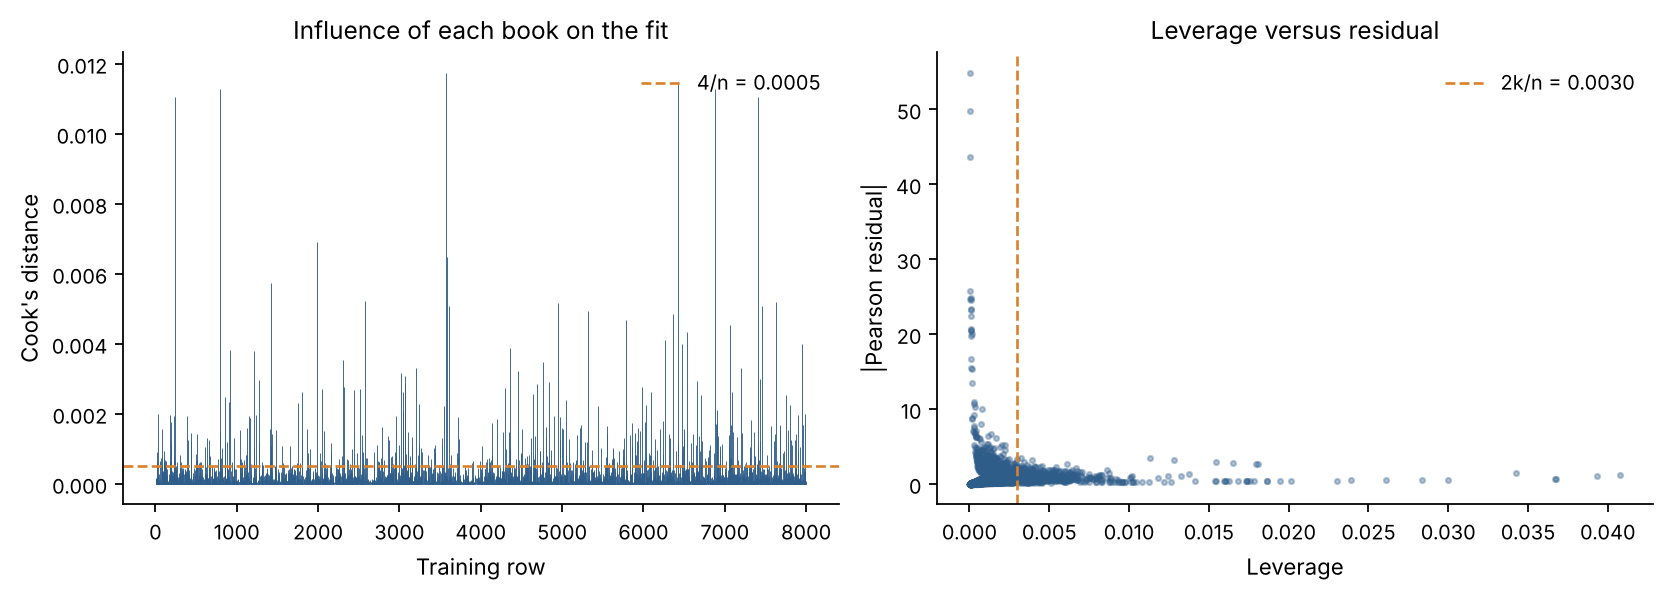

Influence: {'cook_max': 0.011745739329591217, 'cook_n_above': 453, 'cook_threshold': 0.0005, 'lev_max': 0.0407814532337139, 'lev_n_above': 701, 'robust_rows_removed': 80, 'robust_best_sellers_removed': 72, 'robust_sign_flips': 0, 'robust_shift_by_term': {'intercept': -0.977, 'average_rating': 0.065, 'log_books_count': 0.41, 'log_book_age': -0.197, 'lang_other': -4.996, 'lang_unknown': -0.145, 'is_series': 0.0, 'is_series_book1': 0.02, 'title_words': 0.006, 'has_subtitle': -0.021, 'n_authors': -0.168, 'log_author_titles': -0.037}, 'robust_max_slope_shift_excl_lang_other': 0.4097333517525332, 'lang_other_rows_train': 152, 'lang_other_best_sellers_full': 8, 'lang_other_best_sellers_after_trim': 0, 'lang_other_se_after_trim': 4331858.544248307}


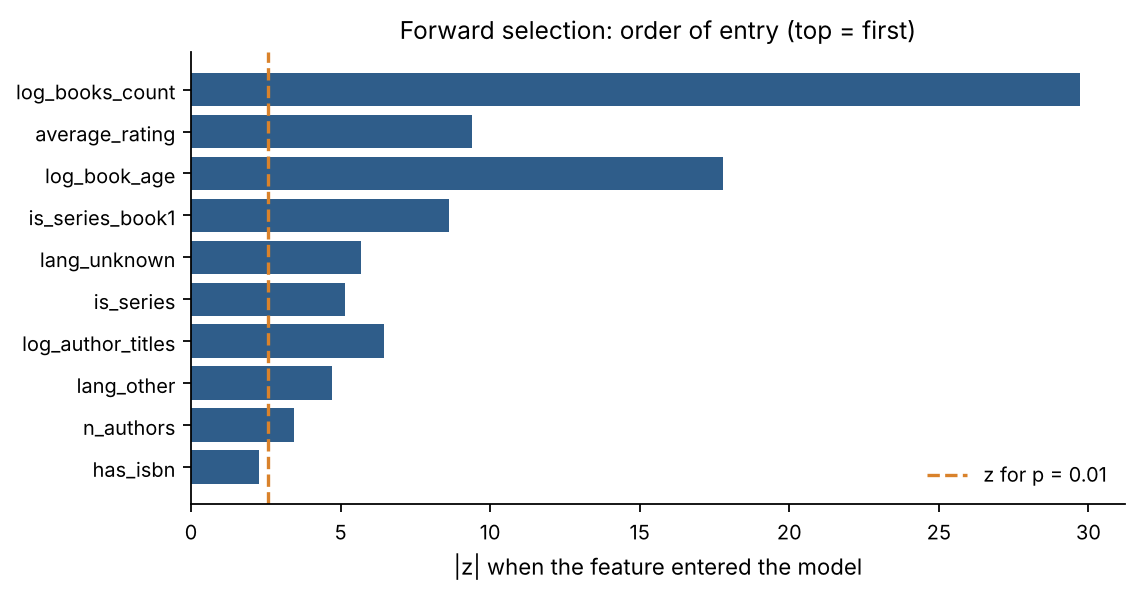

In [11]:
cols_sel = [col_idx[f] for f in SELECTED]
Xd_sel = np.column_stack([np.ones(len(X_train)), X_train[:, cols_sel]])
fit_sel = newton_logit(X_train[:, cols_sel], y_train)
beta_sel = fit_sel["coef"].values
p_sel = sigmoid(Xd_sel @ beta_sel)
w_sel = p_sel * (1 - p_sel)
hinv_sel = np.linalg.inv(Xd_sel.T @ (Xd_sel * w_sel[:, None]))
lev_sel = w_sel * np.einsum("ij,jk,ik->i", Xd_sel, hinv_sel, Xd_sel)        # leverage (hat values)
pearson_sel = (y_train - p_sel) / np.sqrt(w_sel)                           # Pearson residuals
k_par = Xd_sel.shape[1]
cooks_sel = pearson_sel ** 2 * lev_sel / (k_par * (1 - lev_sel) ** 2)       # Cook's distance

# --- Overall fit statistics ----------------------------------------------------------------------------------------
ll_full = float(np.sum(y_train * np.log(p_sel) + (1 - y_train) * np.log(1 - p_sel)))
p_bar = y_train.mean()
ll_null = float(len(y_train) * (p_bar * np.log(p_bar) + (1 - p_bar) * np.log(1 - p_bar)))
lr_chi2 = 2 * (ll_full - ll_null); lr_df = len(SELECTED)
lr_p = float(1 - stats.chi2.cdf(lr_chi2, lr_df))
mcfadden = 1 - ll_full / ll_null
n_tr = len(y_train)
cox_snell = 1 - np.exp(2 * (ll_null - ll_full) / n_tr)
nagelkerke = cox_snell / (1 - np.exp(2 * ll_null / n_tr))
aic = -2 * ll_full + 2 * k_par
bic = -2 * ll_full + k_par * np.log(n_tr)

# Hosmer-Lemeshow test: group books into 10 bands of predicted probability and compare observed with expected counts
bands = pd.qcut(pd.Series(p_sel).rank(method="first"), 10, labels=False)
hl = 0.0
hl_rows = []
for g_ in range(10):
    m_ = (bands == g_).values
    n_g, o_g, e_g = m_.sum(), y_train[m_].sum(), p_sel[m_].sum()
    hl += (o_g - e_g) ** 2 / (e_g * (1 - e_g / n_g))
    hl_rows.append({"band": g_ + 1, "n": int(n_g), "observed": int(o_g), "expected": round(float(e_g), 1)})
hl_p = float(1 - stats.chi2.cdf(hl, 8))
EX_FIT = {"loglik_full": ll_full, "loglik_null": ll_null, "lr_chi2": float(lr_chi2), "lr_df": lr_df, "lr_p": lr_p,
          "mcfadden_r2": float(mcfadden), "nagelkerke_r2": float(nagelkerke), "aic": float(aic), "bic": float(bic),
          "hosmer_lemeshow_chi2": float(hl), "hosmer_lemeshow_p": hl_p, "events_per_variable": float(y_train.sum() / len(SELECTED)),
          "hl_table": hl_rows}
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in EX_FIT.items() if k != "hl_table"})

# --- Influence: Cook's distance and leverage -----------------------------------------------------------------------------
cook_thr = 4 / n_tr
lev_thr = 2 * k_par / n_tr
top_inf = np.argsort(-cooks_sel)[:5]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].vlines(np.arange(n_tr), 0, cooks_sel, color=BLUE, lw=0.4)
axes[0].axhline(cook_thr, color=ORANGE, ls="--", lw=1.2, label=f"4/n = {cook_thr:.4f}")
axes[0].set_xlabel("Training row"); axes[0].set_ylabel("Cook's distance"); axes[0].set_title("Influence of each book on the fit")
axes[0].legend(frameon=False)
axes[1].scatter(lev_sel, np.abs(pearson_sel), s=5, alpha=0.35, color=BLUE)
axes[1].axvline(lev_thr, color=ORANGE, ls="--", lw=1.2, label=f"2k/n = {lev_thr:.4f}")
axes[1].set_xlabel("Leverage"); axes[1].set_ylabel("|Pearson residual|"); axes[1].set_title("Leverage versus residual")
axes[1].legend(frameon=False)
savefig("fig31_influence")
train_titles = model_df.iloc[idx_train]["title"].values
EX_FIT["cook_max"] = float(cooks_sel.max())
EX_FIT["cook_n_above"] = int((cooks_sel > cook_thr).sum())
EX_FIT["cook_threshold"] = float(cook_thr)
EX_FIT["lev_max"] = float(lev_sel.max())
EX_FIT["lev_n_above"] = int((lev_sel > lev_thr).sum())
EX_FIT["top_influential"] = [{"title": str(train_titles[i])[:55], "cooks": round(float(cooks_sel[i]), 4)} for i in top_inf]

# --- Robustness: refit without the 1% most influential books ---------------------------------------------------------------
keep = cooks_sel < np.quantile(cooks_sel, 0.99)
fit_rob = newton_logit(X_train[keep][:, cols_sel], y_train[keep])
terms = ["intercept"] + SELECTED
shift_by_term = dict(zip(terms, (fit_rob["coef"].values - fit_sel["coef"].values).tolist()))
sign_flips = int((np.sign(fit_rob["coef"].values[1:]) != np.sign(fit_sel["coef"].values[1:])).sum())
# Watch out for separation: if a rare group loses ALL its best sellers, its coefficient runs off towards minus infinity.
lo_raw = X_train_raw[:, col_idx["lang_other"]] == 1
events_full = int(y_train[lo_raw].sum()); events_trim = int(y_train[keep & lo_raw].sum())
slope_terms = [t for t in SELECTED if t != "lang_other"]
EX_FIT["robust_rows_removed"] = int((~keep).sum())
EX_FIT["robust_best_sellers_removed"] = int(y_train[~keep].sum())
EX_FIT["robust_sign_flips"] = sign_flips
EX_FIT["robust_shift_by_term"] = {k: round(v, 3) for k, v in shift_by_term.items()}
EX_FIT["robust_max_slope_shift_excl_lang_other"] = float(max(abs(shift_by_term[t]) for t in slope_terms))
EX_FIT["lang_other_rows_train"] = int(lo_raw.sum())
EX_FIT["lang_other_best_sellers_full"] = events_full
EX_FIT["lang_other_best_sellers_after_trim"] = events_trim
EX_FIT["lang_other_se_after_trim"] = float(fit_rob["se"].values[1 + SELECTED.index("lang_other")])
print("Influence:", {k: v for k, v in EX_FIT.items() if k.startswith(("cook", "lev", "robust", "lang_other"))})
RESULTS["model_fit"] = EX_FIT

# --- Forward-selection order, drawn as a bar chart of the Wald z statistic at the point each feature entered --------------
z_enter = []
order_f = [x["added"] for x in fs[ALPHA_CONVENTIONAL]["forward_log"]]
for i_, f_ in enumerate(order_f):
    z_enter.append(abs(float(fit_subset(order_f[: i_ + 1]).loc[f_, "z"])))
fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.barh(order_f[::-1], z_enter[::-1], color=BLUE)
ax.axvline(stats.norm.ppf(1 - 0.01 / 2), color=ORANGE, ls="--", label="z for p = 0.01")
ax.set_xlabel("|z| when the feature entered the model"); ax.set_title("Forward selection: order of entry (top = first)")
ax.legend(frameon=False)
savefig("fig32_forward_order")
RESULTS["forward_order"] = [{"feature": f_, "abs_z": round(z_, 2)} for f_, z_ in zip(order_f, z_enter)]

## 7. Train Model 1 (baseline): all features, default hyper-parameters
Default settings: learning rate 0.1, 1,000 iterations, no regularisation, no class weights,
decision threshold 0.5.

In [12]:
def evaluate(y_true, proba, thr=0.5):
    """All evaluation metrics (computed with scikit-learn) for one set of predictions."""
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"threshold": float(thr),
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "specificity": tn / (tn + fp),
            "f1": f1_score(y_true, pred),
            "roc_auc": roc_auc_score(y_true, proba),
            "pr_auc": average_precision_score(y_true, proba),
            "log_loss": log_loss(y_true, np.clip(proba, 1e-12, 1 - 1e-12)),
            "mcc": matthews_corrcoef(y_true, pred),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


model1 = LogisticRegressionScratch(lr=0.1, n_iter=1000, l2=0.0, class_weight=None)
model1.fit(X_train, y_train)
p1_train, p1_test = model1.predict_proba(X_train), model1.predict_proba(X_test)
m1_train, m1_test = evaluate(y_train, p1_train), evaluate(y_test, p1_test)
print("Model 1 TEST :", {k: round(v, 3) for k, v in m1_test.items() if k not in ("tn", "fp", "fn", "tp")})
print("Model 1 TRAIN:", {k: round(v, 3) for k, v in m1_train.items() if k in ("accuracy", "f1", "roc_auc")})
print("Majority-class baseline accuracy:", round(1 - y_test.mean(), 3))
RESULTS["model1"] = {"params": {"lr": 0.1, "n_iter": 1000, "l2": 0.0, "class_weight": None, "threshold": 0.5,
                                "features": FEATURES, "iterations_used": len(model1.loss_history)},
                     "train": m1_train, "test": m1_test, "majority_accuracy": float(1 - y_test.mean())}

Model 1 TEST : {'threshold': 0.5, 'accuracy': 0.844, 'precision': 0.754, 'recall': 0.323, 'specificity': np.float64(0.974), 'f1': 0.452, 'roc_auc': 0.813, 'pr_auc': 0.611, 'log_loss': 0.392, 'mcc': 0.424}
Model 1 TRAIN: {'accuracy': 0.841, 'f1': 0.454, 'roc_auc': 0.823}
Majority-class baseline accuracy: 0.8


**Reading Model 1:** it is accurate overall but it mostly predicts the majority class, so
**recall for best sellers is low** (it misses many real best sellers). That is exactly the
shortcoming of an un-tuned model on imbalanced data. Model 2 addresses it.

## 8. Retrain (Model 2): feature selection + hyper-parameter tuning
Changes made to fix the weaknesses of Model 1:
1. **Selected features only** (backward elimination at p < 0.01; simpler, less noise).
2. **Hyper-parameters tuned by 5-fold stratified cross-validation** on the training set: learning rate,
   L2 regularisation strength and class weights (None vs "balanced"), scored with PR-AUC, which suits
   imbalanced data.
3. **Decision threshold chosen from out-of-fold predictions** to maximise F1 (instead of the fixed 0.5), and
   class weights chosen by the F1 they reach at their own best threshold.
Nothing in this step uses the test set.

                     feature_set  n_features  cv_pr_auc  cv_roc_auc
0                All 12 features          12     0.5997      0.8218
1  Backward @ 0.01 (11 features)          11     0.5996      0.8219
2    Forward @ 0.01 (9 features)           9     0.5983      0.8221


     lr  n_iter     l2 class_weight  cv_pr_auc  cv_roc_auc
0  0.50    2000  0.000          NaN     0.6007      0.8216
1  0.10    2000  0.000          NaN     0.6006      0.8217
2  0.50    2000  0.001          NaN     0.5999      0.8218
3  0.10    2000  0.001          NaN     0.5999      0.8218
4  0.05    2000  0.000          NaN     0.5996      0.8219
5  0.05    2000  0.001          NaN     0.5989      0.8219
6  0.50    2000  0.010          NaN     0.5933      0.8220
7  0.10    2000  0.010          NaN     0.5932      0.8219


  class_weight   lr   l2  cv_pr_auc  cv_roc_auc  threshold   cv_f1
0         None  0.5  0.0     0.6007      0.8216       0.30  0.5682
1     balanced  0.5  0.0     0.5906      0.8213       0.61  0.5649

Chosen hyper-parameters: {'lr': 0.5, 'n_iter': 2000, 'l2': 0.0, 'class_weight': None}
Best threshold (max out-of-fold F1): 0.30  (F1 = 0.568)


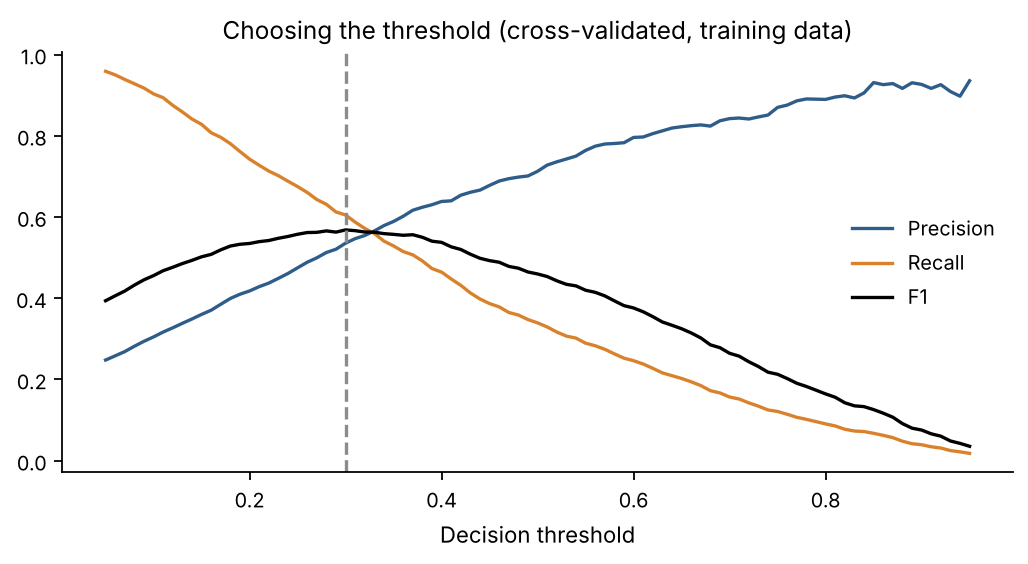

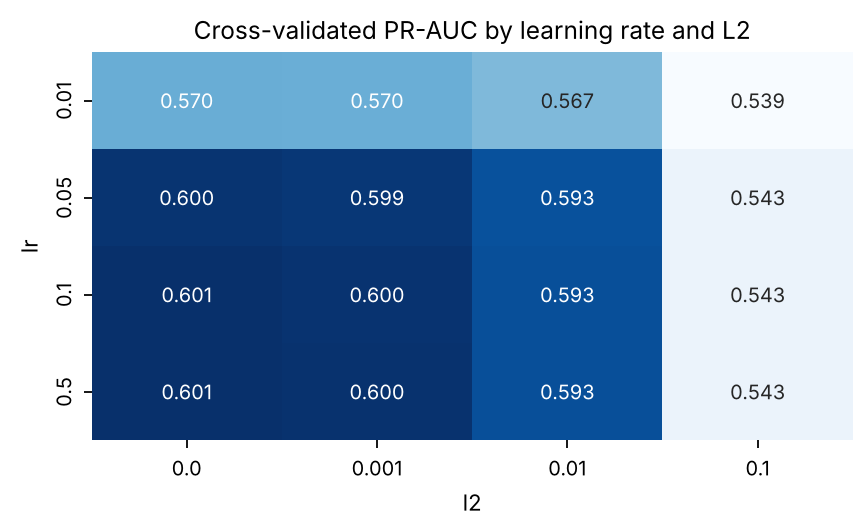

Model 2 TEST : {'threshold': 0.3, 'accuracy': 0.815, 'precision': 0.535, 'recall': 0.575, 'specificity': np.float64(0.875), 'f1': 0.554, 'roc_auc': 0.813, 'pr_auc': 0.61, 'log_loss': 0.393, 'mcc': 0.438}
Model 2 TRAIN: {'accuracy': 0.816, 'f1': 0.567, 'roc_auc': 0.823}


In [13]:
sel_cols = [col_idx[f] for f in SELECTED]
Xs_train_raw, Xs_test_raw = X_train_raw[:, sel_cols], X_test_raw[:, sel_cols]


def cross_validate(params, features=None, n_splits=5):
    """Stratified k-fold CV; scaling is re-fitted inside every fold (no leakage).
    Returns mean PR-AUC, mean ROC-AUC and the out-of-fold probabilities."""
    cols = [col_idx[f] for f in (features or SELECTED)]
    Xcv = X_train_raw[:, cols]
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(y_train))
    aps, aucs = [], []
    for tr, va in skf.split(Xcv, y_train):
        m_, s_ = fit_scaler(Xcv[tr])
        mdl = LogisticRegressionScratch(**params).fit((Xcv[tr] - m_) / s_, y_train[tr])
        pr = mdl.predict_proba((Xcv[va] - m_) / s_)
        oof[va] = pr
        aps.append(average_precision_score(y_train[va], pr))
        aucs.append(roc_auc_score(y_train[va], pr))
    return np.mean(aps), np.mean(aucs), oof


# --- 8.1 Does feature selection cost any accuracy? Compare feature sets with 5-fold CV (default settings) ---
default_params = dict(lr=0.1, n_iter=1000, l2=0.0, class_weight=None)
sets = {"All 12 features": FEATURES,
        f"Backward @ {ALPHA_MAIN} ({len(SELECTED)} features)": SELECTED,
        f"Forward @ {ALPHA_MAIN} ({len(fs[ALPHA_MAIN]['forward_selected'])} features)": fs[ALPHA_MAIN]["forward_selected"]}
set_rows = []
for name, feats in sets.items():
    ap, auc, _ = cross_validate(default_params, feats)
    set_rows.append({"feature_set": name, "n_features": len(feats), "cv_pr_auc": ap, "cv_roc_auc": auc})
set_cmp = pd.DataFrame(set_rows)
print(set_cmp.round(4))
RESULTS["feature_set_comparison"] = set_cmp.round(4).to_dict("records")

# --- 8.2 Hyper-parameter grid search (5-fold CV on the training set only) ---------------------------------
grid = []
for lr in [0.01, 0.05, 0.1, 0.5]:
    for l2 in [0.0, 0.001, 0.01, 0.1]:
        for cw in [None, "balanced"]:
            params = dict(lr=lr, n_iter=2000, l2=l2, class_weight=cw)
            ap, auc, _ = cross_validate(params)
            grid.append({**params, "cv_pr_auc": ap, "cv_roc_auc": auc})
grid = pd.DataFrame(grid).sort_values(["cv_pr_auc", "cv_roc_auc"], ascending=False).reset_index(drop=True)
print(grid.head(8).round(4))
grid.to_csv(f"{OUT_DIR}/tuning_grid.csv", index=False)

# --- 8.3 Choose class weights + threshold on EVIDENCE (cross-validation on the training set only) ----------
# PR-AUC only measures how well books are RANKED, and class weights barely change a ranking. What class
# weights and the decision threshold change is the OPERATING POINT (how many best sellers we catch vs how many
# false alarms). So for each class-weight option I (1) take its best lr / l2 by CV PR-AUC, (2) tune the decision
# threshold on out-of-fold predictions to maximise F1, and (3) compare the F1 each option reaches.
thr_grid = np.linspace(0.05, 0.95, 91)


def threshold_curves(oof):
    """Precision, recall and F1 at every threshold, computed on out-of-fold predictions."""
    pr_ = np.array([precision_score(y_train, (oof >= t).astype(int), zero_division=0) for t in thr_grid])
    rc_ = np.array([recall_score(y_train, (oof >= t).astype(int)) for t in thr_grid])
    f1_ = np.array([f1_score(y_train, (oof >= t).astype(int)) for t in thr_grid])
    return pr_, rc_, f1_


candidates = []
for cw in [None, "balanced"]:
    sub = grid[grid["class_weight"].isna()] if cw is None else grid[grid["class_weight"] == cw]
    row = sub.sort_values(["cv_pr_auc", "lr"], ascending=False).iloc[0]
    params = dict(lr=float(row["lr"]), n_iter=2000, l2=float(row["l2"]), class_weight=cw)
    ap, auc, oof = cross_validate(params)
    pr_, rc_, f1_ = threshold_curves(oof)
    candidates.append({"class_weight": str(cw), "lr": params["lr"], "l2": params["l2"], "cv_pr_auc": float(ap),
                       "cv_roc_auc": float(auc), "threshold": float(thr_grid[f1_.argmax()]),
                       "cv_f1": float(f1_.max()), "params": params, "curves": (pr_, rc_, f1_)})
cand_tbl = pd.DataFrame([{k: v for k, v in c.items() if k not in ("params", "curves")} for c in candidates])
print(cand_tbl.round(4))

# Choose the option with the highest CV F1. If they are within 0.002 (a tie) prefer 'balanced', because the
# weights make the model itself pay attention to the rare best-seller class instead of relying on the threshold alone.
best_c = max(candidates, key=lambda c: c["cv_f1"])
bal_c = [c for c in candidates if c["class_weight"] == "balanced"][0]
if best_c["cv_f1"] - bal_c["cv_f1"] <= 0.002:
    best_c = bal_c
best_params, best_thr = best_c["params"], best_c["threshold"]
prs, rcs, f1s = best_c["curves"]
best = best_c                                         # (used below when saving the results)
print("\nChosen hyper-parameters:", best_params)
print(f"Best threshold (max out-of-fold F1): {best_thr:.2f}  (F1 = {f1s.max():.3f})")
RESULTS["class_weight_comparison"] = cand_tbl.round(4).to_dict("records")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(thr_grid, prs, color=BLUE, label="Precision")
ax.plot(thr_grid, rcs, color=ORANGE, label="Recall")
ax.plot(thr_grid, f1s, color="black", label="F1")
ax.axvline(best_thr, color=GREY, ls="--"); ax.set_xlabel("Decision threshold")
ax.set_title("Choosing the threshold (cross-validated, training data)"); ax.legend(frameon=False)
savefig("fig07_threshold")

# --- Tuning heat-map (for the chosen class-weight option) ------------------------------------------------
_cw = best_params["class_weight"]
piv = (grid[grid.class_weight.isna()] if _cw is None else grid[grid.class_weight == _cw]).pivot(index="lr", columns="l2", values="cv_pr_auc")
plt.figure(figsize=(5.5, 3.4))
sns.heatmap(piv, annot=True, fmt=".3f", cmap="Blues", cbar=False)
plt.title("Cross-validated PR-AUC by learning rate and L2")
savefig("fig08_tuning_heatmap")

# --- Fit the final Model 2 on the full training set and test it ONCE -------------------------
mu_s, sd_s = fit_scaler(Xs_train_raw)
Xs_train, Xs_test = (Xs_train_raw - mu_s) / sd_s, (Xs_test_raw - mu_s) / sd_s
model2 = LogisticRegressionScratch(**best_params).fit(Xs_train, y_train)
p2_train, p2_test = model2.predict_proba(Xs_train), model2.predict_proba(Xs_test)
m2_train, m2_test = evaluate(y_train, p2_train, best_thr), evaluate(y_test, p2_test, best_thr)
print("Model 2 TEST :", {k: round(v, 3) for k, v in m2_test.items() if k not in ("tn", "fp", "fn", "tp")})
print("Model 2 TRAIN:", {k: round(v, 3) for k, v in m2_train.items() if k in ("accuracy", "f1", "roc_auc")})
RESULTS["model2"] = {"params": {**best_params, "threshold": best_thr, "features": SELECTED,
                                "iterations_used": len(model2.loss_history)},
                     "train": m2_train, "test": m2_test,
                     "cv_pr_auc": float(best["cv_pr_auc"]), "cv_roc_auc": float(best["cv_roc_auc"]),
                     "cv_f1_at_threshold": float(f1s.max())}
RESULTS["grid_top5"] = grid.head(5).round(4).to_dict("records")

## 9. Evaluation and interpretation
**Metrics chosen and why**
| Metric | What it answers | Why it matters here |
|---|---|---|
| Accuracy | share of all predictions that are right | easy to read but misleading at 80/20 |
| Precision | of books we call best sellers, how many are? | cost of over-printing / over-promoting a flop |
| Recall | of real best sellers, how many do we find? | cost of missing a hit |
| F1 | balance of precision and recall | single score for the rare class |
| ROC-AUC | ranking quality across all thresholds | threshold-free; 0.5 = guessing, 1 = perfect |
| PR-AUC | ranking quality focused on the rare class | the baseline equals the best-seller rate (0.20) |
| MCC | correlation of prediction and truth, uses all 4 confusion-matrix cells | robust on imbalanced data |
| Log-loss | quality of the predicted probabilities | training objective |

             Model 1 (baseline)  Model 2 (retrained)
threshold                 0.500                0.300
accuracy                  0.844                0.815
precision                 0.754                0.535
recall                    0.322                0.575
specificity               0.974                0.875
f1                        0.452                0.554
roc_auc                   0.813                0.813
pr_auc                    0.611                0.610
log_loss                  0.392                0.393
mcc                       0.424                0.438


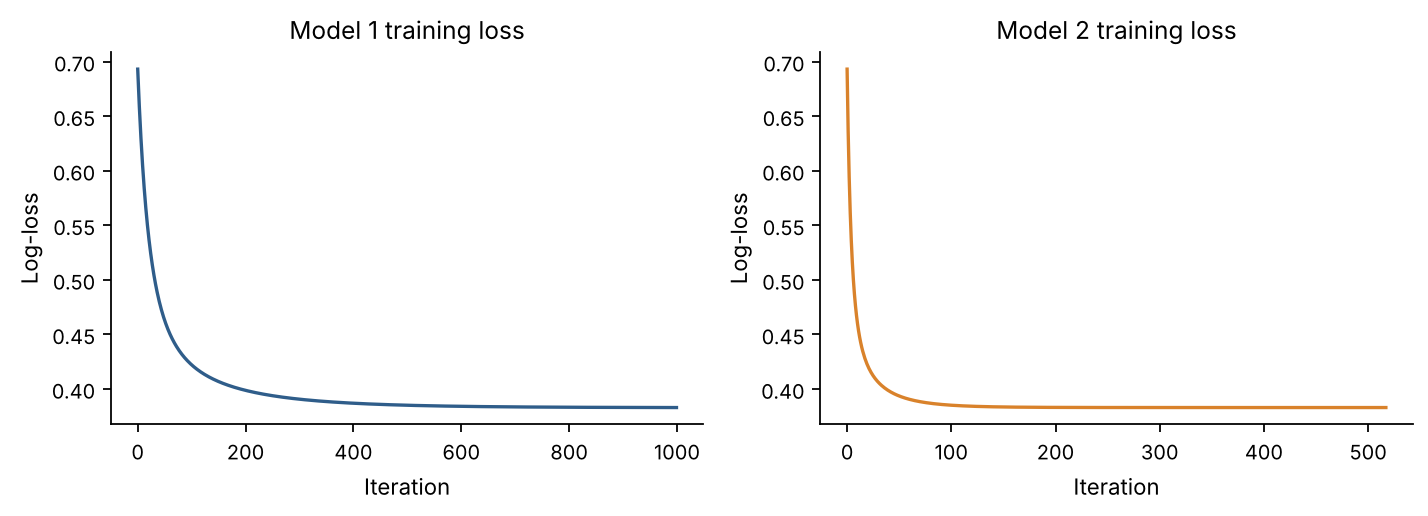

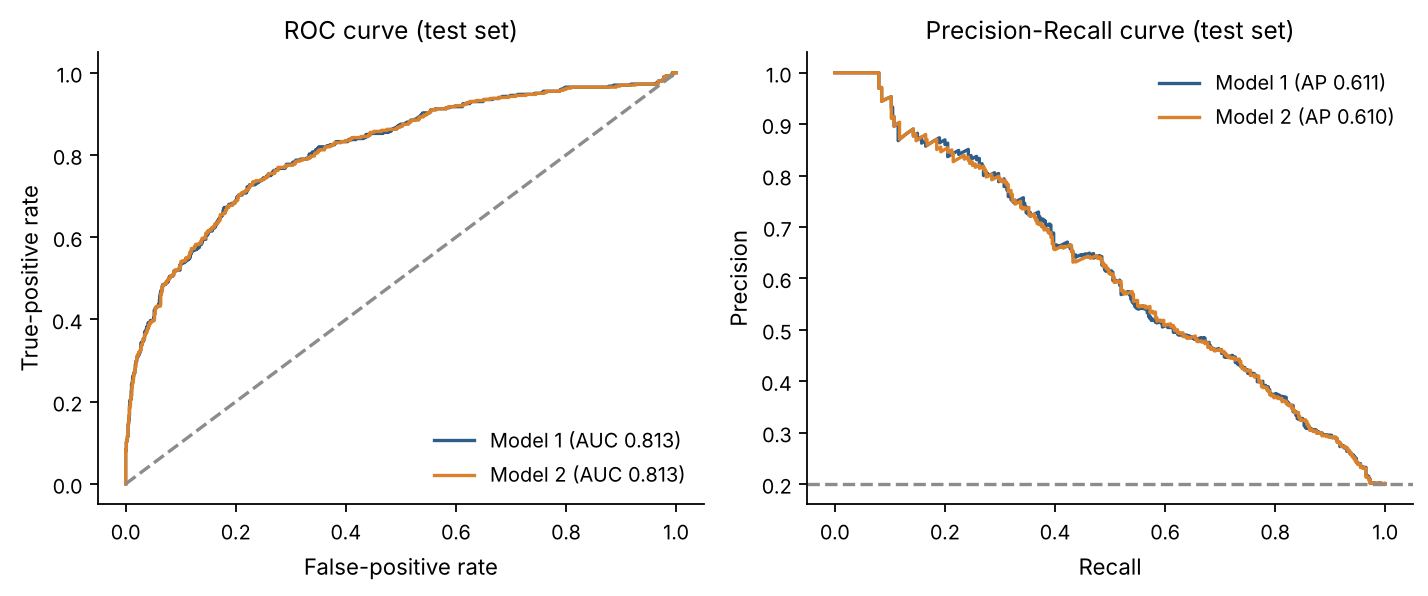

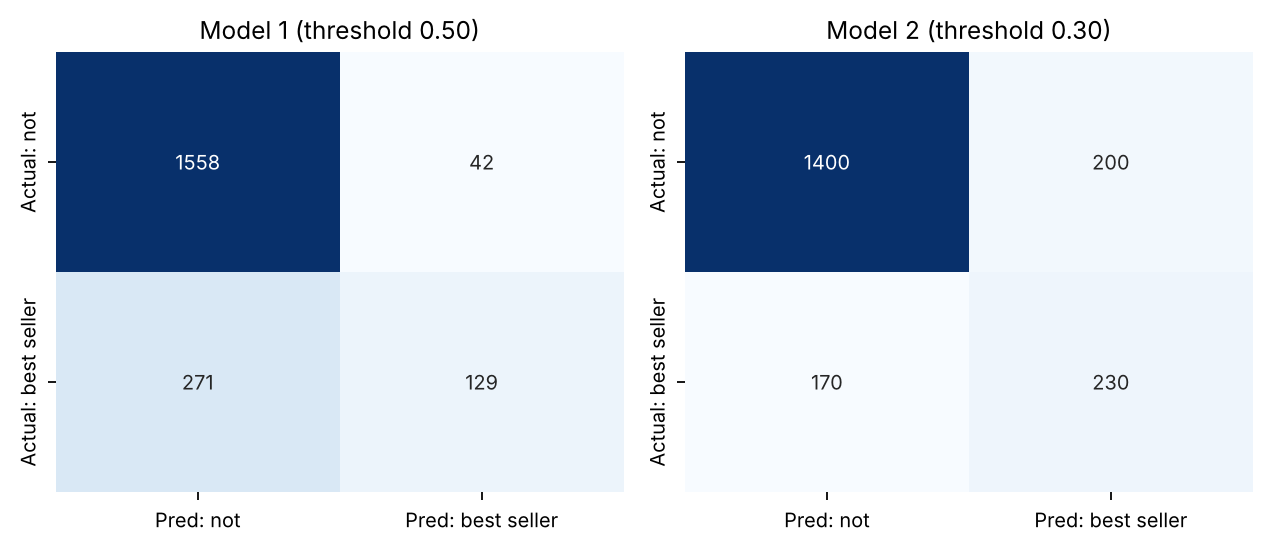

Model 2 test ROC-AUC 95% bootstrap CI: 0.786 - 0.838

Final model coefficients (per 1 standard deviation):
                      coef      se        z  p_value  odds_ratio  or_low  \
intercept         -1.9287  0.0412 -46.8202   0.0000      0.1453  0.1341   
average_rating     0.4494  0.0374  12.0194   0.0000      1.5673  1.4566   
log_books_count    1.6917  0.0551  30.6965   0.0000      5.4285  4.8727   
log_book_age      -0.6900  0.0428 -16.1062   0.0000      0.5016  0.4612   
lang_other        -0.2510  0.0540  -4.6501   0.0000      0.7781  0.7000   
lang_unknown      -0.2878  0.0455  -6.3214   0.0000      0.7499  0.6859   
is_series         -0.3268  0.0448  -7.2886   0.0000      0.7212  0.6605   
is_series_book1    0.4006  0.0372  10.7773   0.0000      1.4927  1.3878   
title_words        0.1593  0.0500   3.1846   0.0014      1.1727  1.0632   
has_subtitle      -0.1382  0.0533  -2.5948   0.0095      0.8709  0.7846   
n_authors         -0.1333  0.0398  -3.3479   0.0008      0.8752  0.

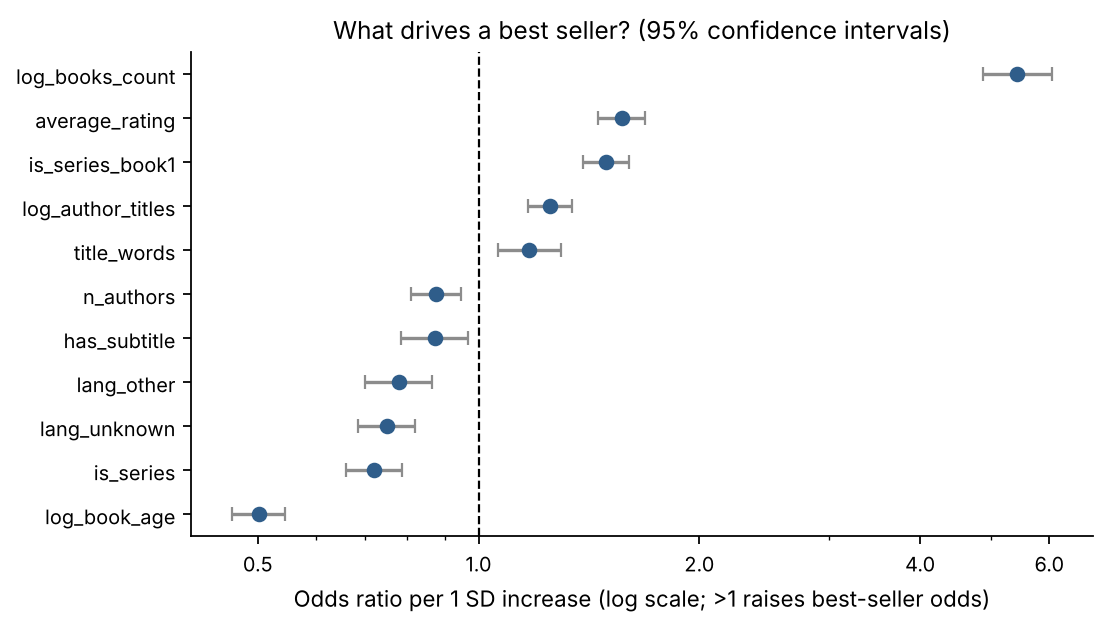


Most confident FALSE POSITIVES:
                                             title     proba  \
7067                                  Martin Eden  0.812616   
2341                         Beyond Good and Evil  0.805590   
3079  King Solomon's Mines (Allan Quatermain, #1)  0.776566   
8978             The Case-Book of Sherlock Holmes  0.776266   
2360                Kidnapped (David Balfour, #1)  0.774949   

      work_ratings_count  
7067               14933  
2341               43322  
3079               36163  
8978               14613  
2360               48520  

Most missed BEST SELLERS:
                                                   title     proba  \
1568                               The Gift of the Magi  0.000425   
1419  The Rise and Fall of the Third Reich: A Histor...  0.000438   
833                       Midnight Sun (Twilight, #1.5)  0.000768   
1122                                      Skeleton Crew  0.001667   
959            The Gathering Storm (Wheel of Time, #

In [14]:
# --- 9.1 Side-by-side comparison --------------------------------------------------------------------
comp = pd.DataFrame({"Model 1 (baseline)": m1_test, "Model 2 (retrained)": m2_test}).drop(
    ["tn", "fp", "fn", "tp"]).round(3)
print(comp)
comp.to_csv(f"{OUT_DIR}/model_comparison.csv")

# --- 9.2 Loss curves (did gradient descent converge?) ----------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(9, 3.3))
ax[0].plot(model1.loss_history, color=BLUE); ax[0].set_title("Model 1 training loss")
ax[1].plot(model2.loss_history, color=ORANGE); ax[1].set_title("Model 2 training loss")
for a in ax:
    a.set_xlabel("Iteration"); a.set_ylabel("Log-loss")
savefig("fig09_loss_curves")

# --- 9.3 ROC and Precision-Recall curves ----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for proba, lab, col in [(p1_test, "Model 1", BLUE), (p2_test, "Model 2", ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax[0].plot(fpr, tpr, color=col, label=f"{lab} (AUC {roc_auc_score(y_test, proba):.3f})")
    pr_, rc_, _ = precision_recall_curve(y_test, proba)
    ax[1].plot(rc_, pr_, color=col, label=f"{lab} (AP {average_precision_score(y_test, proba):.3f})")
ax[0].plot([0, 1], [0, 1], color=GREY, ls="--"); ax[0].set_xlabel("False-positive rate")
ax[0].set_ylabel("True-positive rate"); ax[0].set_title("ROC curve (test set)"); ax[0].legend(frameon=False)
ax[1].axhline(y_test.mean(), color=GREY, ls="--"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve (test set)"); ax[1].legend(frameon=False)
savefig("fig10_roc_pr")

# --- 9.4 Confusion matrices ------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5))
for a, m, title in [(ax[0], m1_test, "Model 1 (threshold 0.50)"), (ax[1], m2_test, f"Model 2 (threshold {best_thr:.2f})")]:
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["Pred: not", "Pred: best seller"], yticklabels=["Actual: not", "Actual: best seller"])
    a.set_title(title)
savefig("fig11_confusion")

# --- 9.5 Bootstrap 95% confidence interval for the test ROC-AUC -------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_test), len(y_test))
    if y_test[i].min() != y_test[i].max():
        boot.append(roc_auc_score(y_test[i], p2_test[i]))
auc_ci = (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)))
print(f"Model 2 test ROC-AUC 95% bootstrap CI: {auc_ci[0]:.3f} - {auc_ci[1]:.3f}")
RESULTS["auc_ci"] = auc_ci

# --- 9.6 Interpreting the coefficients as odds ratios (un-penalised Newton fit, with 95% CI) ---------------
final_fit = newton_logit(Xs_train, y_train)
final_fit.index = ["intercept"] + SELECTED
final_fit["odds_ratio"] = np.exp(final_fit["coef"])
final_fit["or_low"] = np.exp(final_fit["coef"] - 1.96 * final_fit["se"])
final_fit["or_high"] = np.exp(final_fit["coef"] + 1.96 * final_fit["se"])
print("\nFinal model coefficients (per 1 standard deviation):\n", final_fit.round(4))
final_fit.to_csv(f"{OUT_DIR}/final_model_coefficients.csv")
RESULTS["final_coefficients"] = final_fit.round(5).reset_index().rename(columns={"index": "term"}).to_dict("records")

orf = final_fit.drop("intercept").sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(orf["odds_ratio"], range(len(orf)),
            xerr=[orf["odds_ratio"] - orf["or_low"], orf["or_high"] - orf["odds_ratio"]],
            fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(1, color="black", ls="--", lw=1); ax.set_xscale("log")
ax.set_xticks([0.5, 1, 2, 4, 6]); ax.xaxis.set_major_formatter(matplotlib.ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_yticks(range(len(orf))); ax.set_yticklabels(orf.index)
ax.set_xlabel("Odds ratio per 1 SD increase (log scale; >1 raises best-seller odds)")
ax.set_title("What drives a best seller? (95% confidence intervals)")
savefig("fig12_odds_ratios")

# --- 9.7 Error analysis: which books does the model get most wrong? ----------------------------------------------
test_info = model_df.iloc[idx_test][["title", "authors", "work_ratings_count"]].copy()
test_info["proba"] = p2_test
test_info["actual"] = y_test
fp_ex = test_info[test_info.actual == 0].nlargest(5, "proba")
fn_ex = test_info[test_info.actual == 1].nsmallest(5, "proba")
print("\nMost confident FALSE POSITIVES:\n", fp_ex[["title", "proba", "work_ratings_count"]])
print("\nMost missed BEST SELLERS:\n", fn_ex[["title", "proba", "work_ratings_count"]])
RESULTS["false_positives"] = fp_ex.assign(title=fp_ex.title.str[:60]).round(3).to_dict("records")
RESULTS["false_negatives"] = fn_ex.assign(title=fn_ex.title.str[:60]).round(3).to_dict("records")

### 9.8 Sensitivity check: is "number of editions" doing all the work?
Editions are partly a *consequence* of success (popular books get re-published), and public-domain classics
have many editions. A publisher who wants to predict **before** publishing would not have this feature,
so I re-train the same model without it.

In [15]:
feats_no_ed = [f for f in SELECTED if f != "log_books_count"]
cols_ne = [col_idx[f] for f in feats_no_ed]
m_ne, s_ne = fit_scaler(X_train_raw[:, cols_ne])
model_ne = LogisticRegressionScratch(**best_params).fit((X_train_raw[:, cols_ne] - m_ne) / s_ne, y_train)
p_ne = model_ne.predict_proba((X_test_raw[:, cols_ne] - m_ne) / s_ne)
sens = {"roc_auc": float(roc_auc_score(y_test, p_ne)), "pr_auc": float(average_precision_score(y_test, p_ne))}
print("Without editions -> test ROC-AUC", round(sens["roc_auc"], 3), "| PR-AUC", round(sens["pr_auc"], 3))
RESULTS["sensitivity_no_editions"] = sens

Without editions -> test ROC-AUC 0.675 | PR-AUC 0.346


### What the evaluation tells us
* **Ranking power is the same** for both models (test ROC-AUC 0.813, 95% bootstrap interval about 0.79 - 0.84).
  Tuning the learning rate and L2 strength changed almost nothing, and class weights did not help once the
  threshold was tuned (cross-validated F1 0.568 without weights vs 0.565 with them), so Model 2 uses none.
* **The real gain is the decision threshold.** Moving it from 0.50 to 0.30 raises recall from 0.32 to 0.58 and
  F1 from 0.45 to 0.55 at the cost of precision (0.75 to 0.54) and accuracy (0.84 to 0.82).
  Model 2 keeps well-calibrated probabilities (log-loss 0.393, the same as Model 1).
* **Drivers:** editions, average rating, first-in-series, author catalogue size raise the odds;
  older age (given editions), later books in a series, non-English or unknown language and subtitles lower them.
* **Caution:** without the editions feature the ROC-AUC drops to about 0.67, and the confident false positives are
  public-domain classics with many editions. The model is a screening tool, not a sales forecast.

### 9.9 More diagnostics and visuals
These charts explain *how* the model works (sigmoid, loss surface, learning rates) and test it from more
angles (probability separation, calibration, gains and lift, permutation importance, learning curve,
per-fold stability, individual predictions and performance by segment).
Hyper-parameters and the threshold were fixed earlier on the training data; the test set is used here only
to describe the finished model, never to change it.

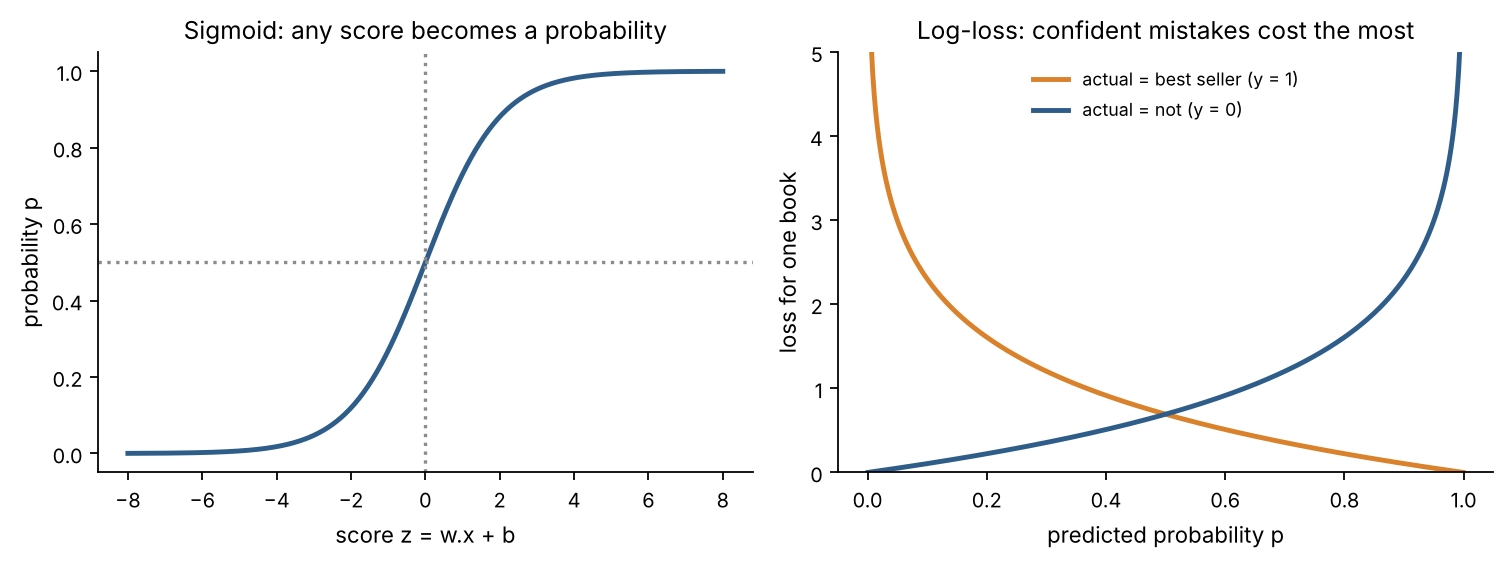

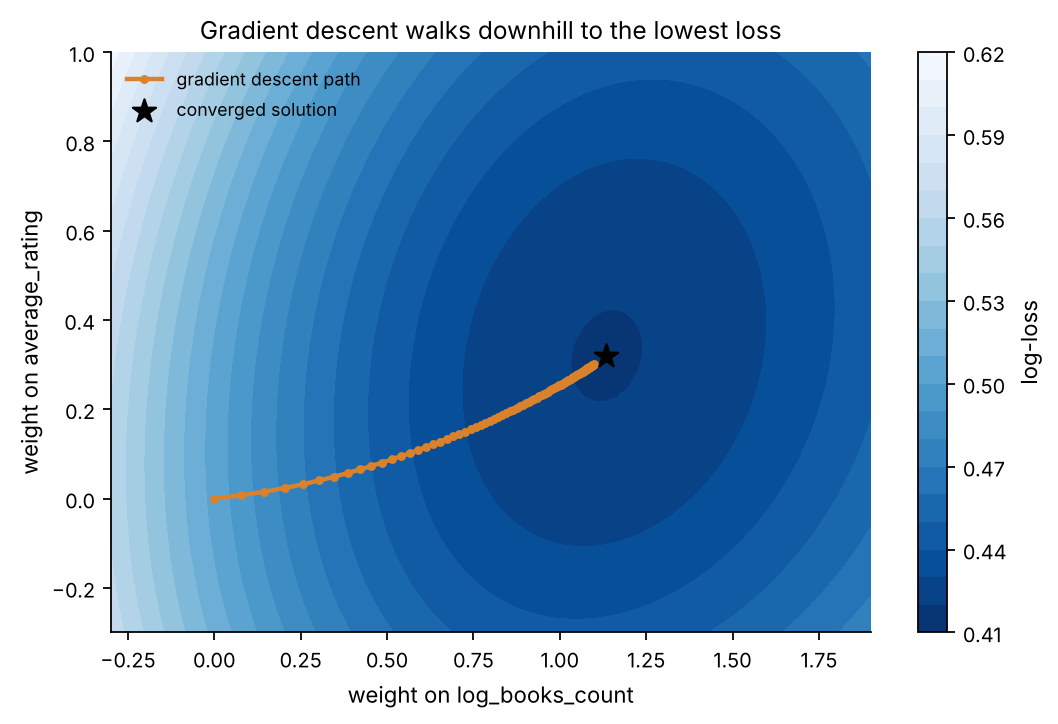

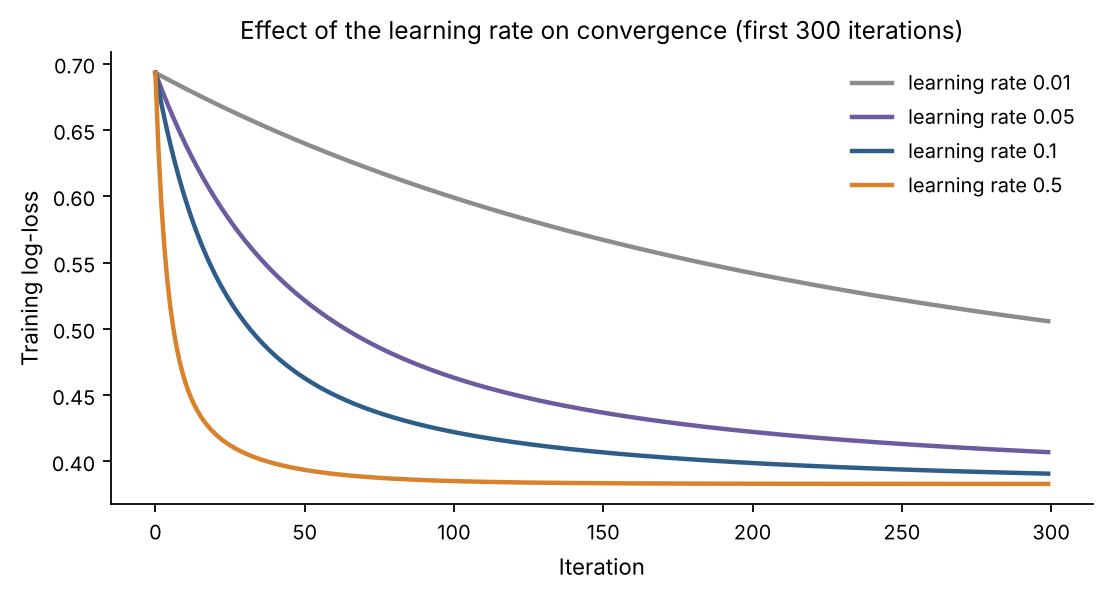

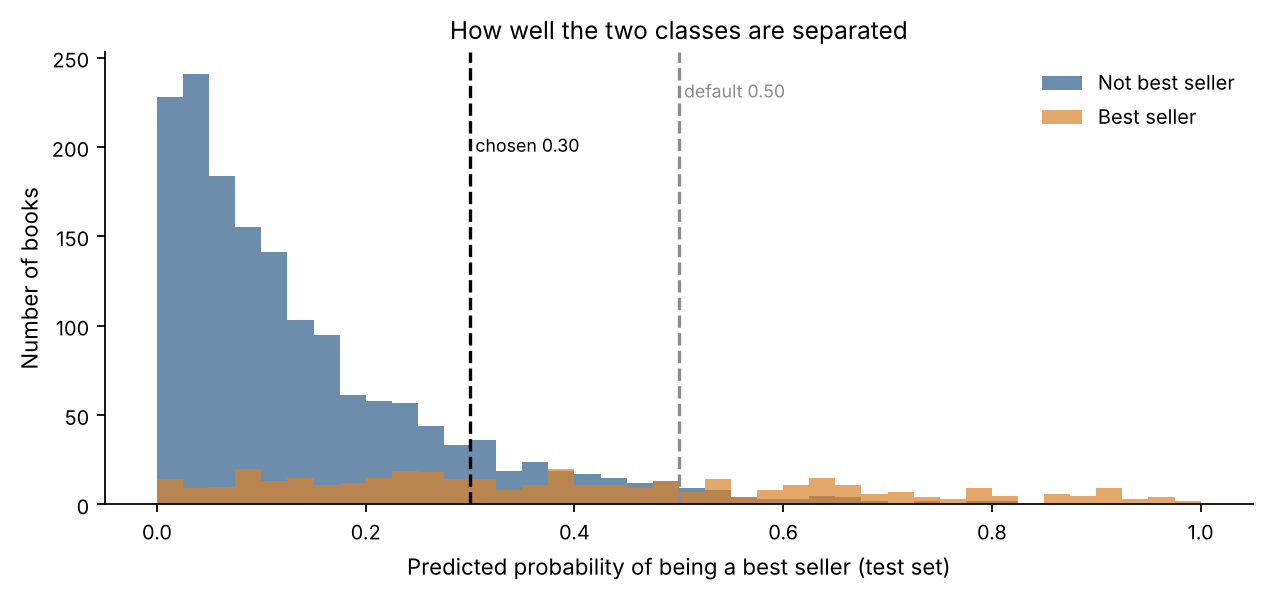

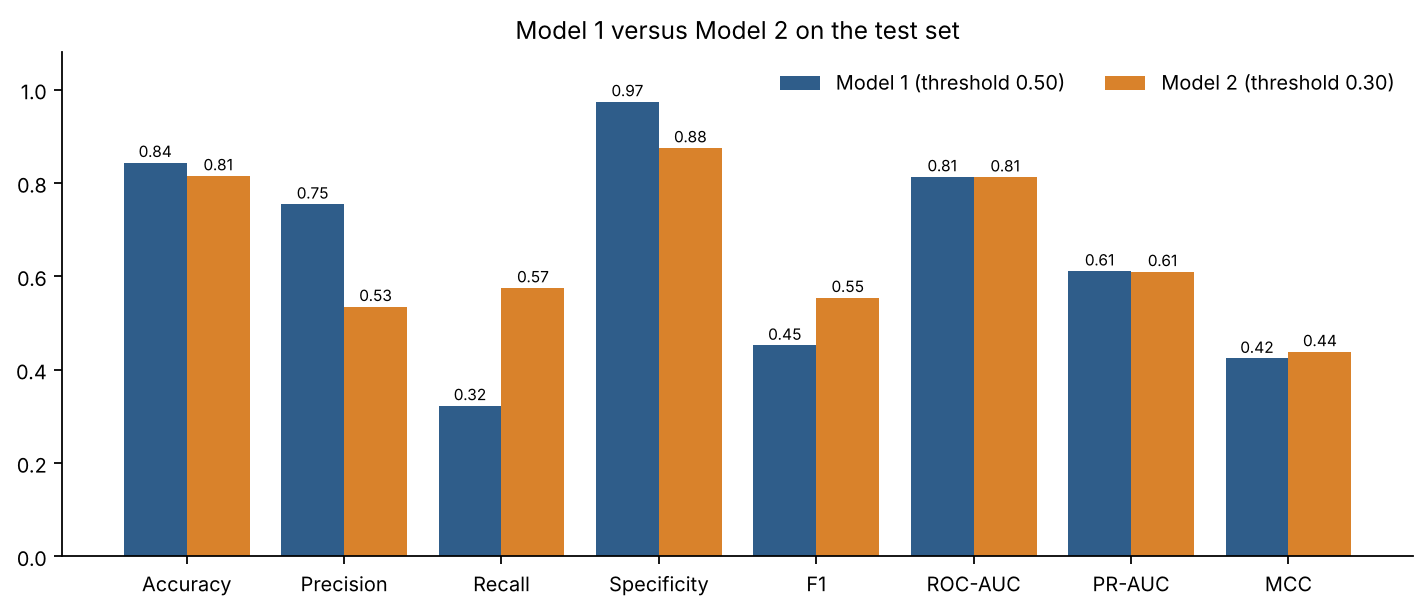

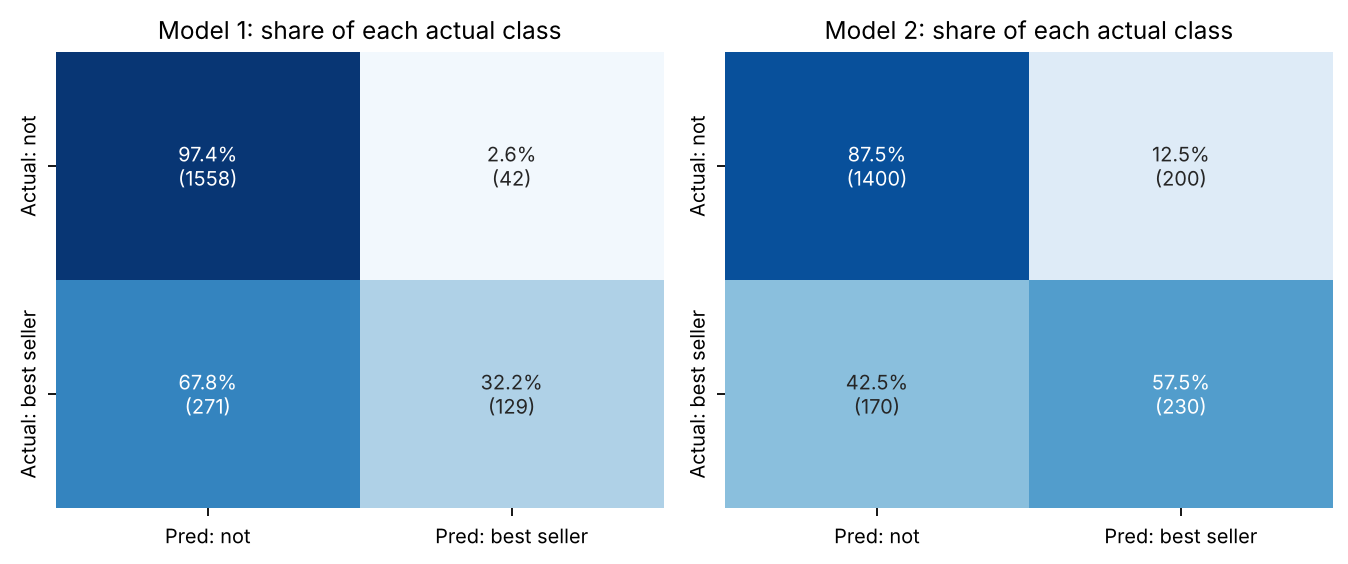

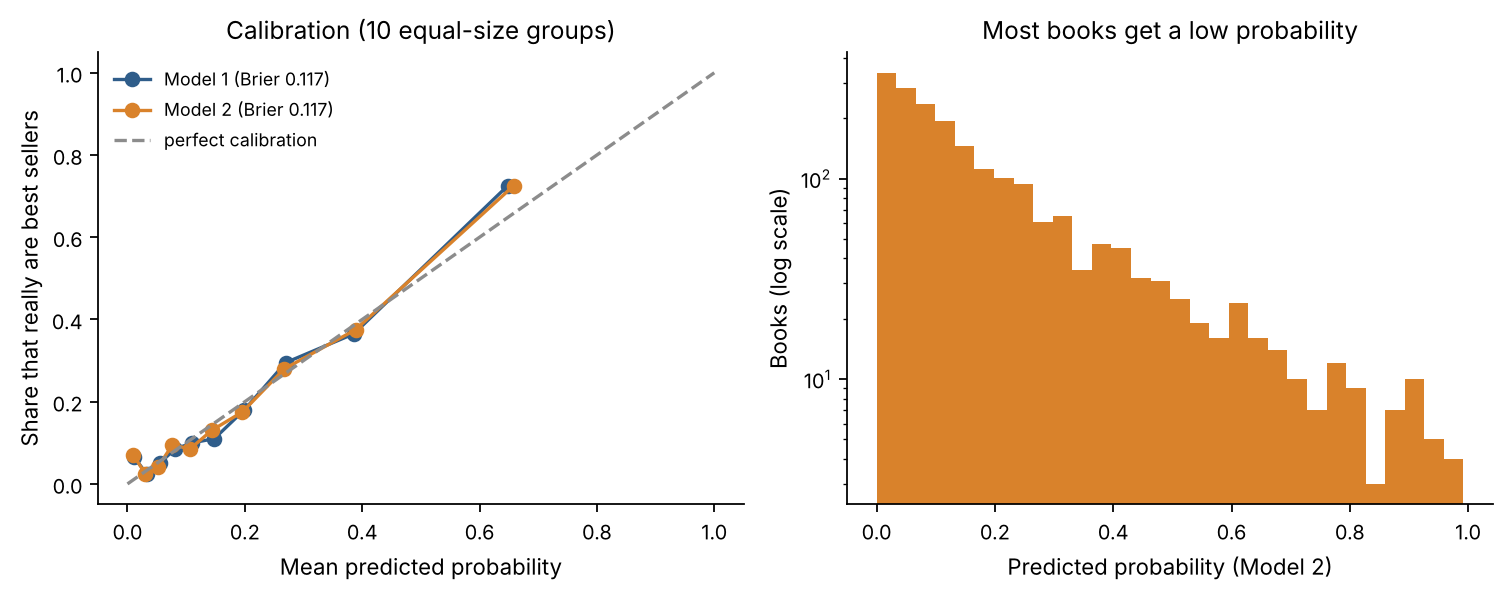

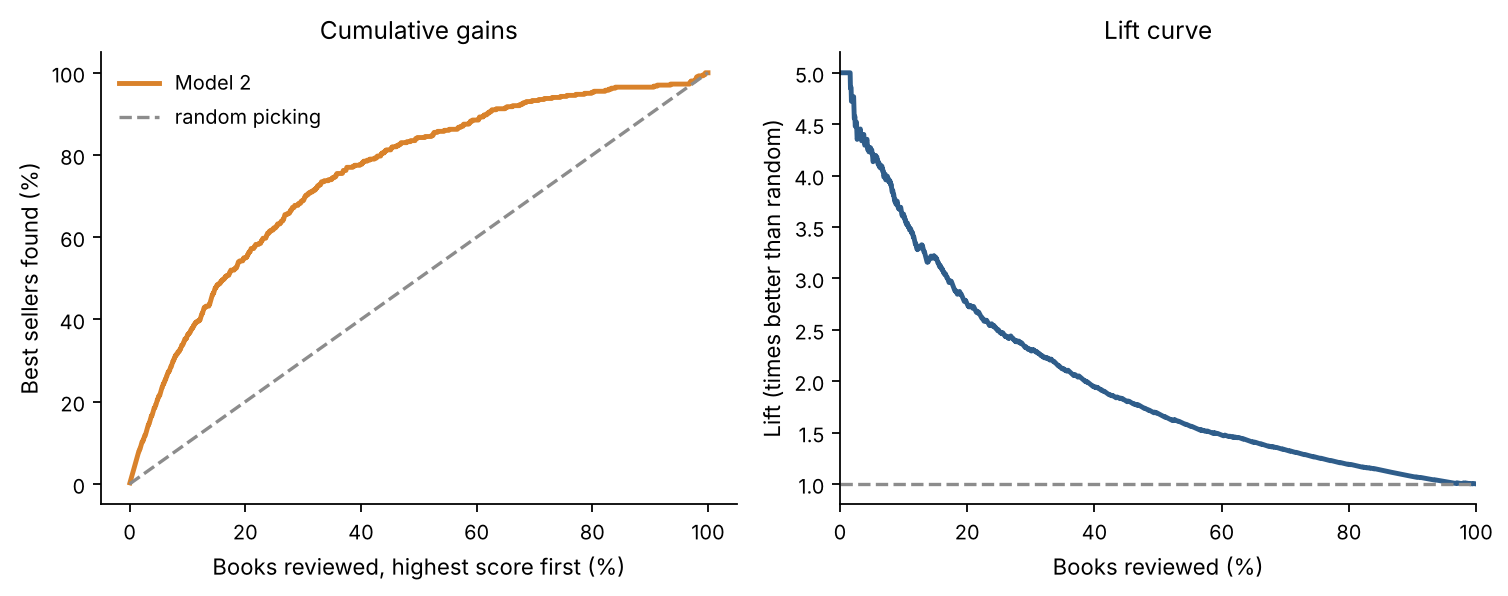

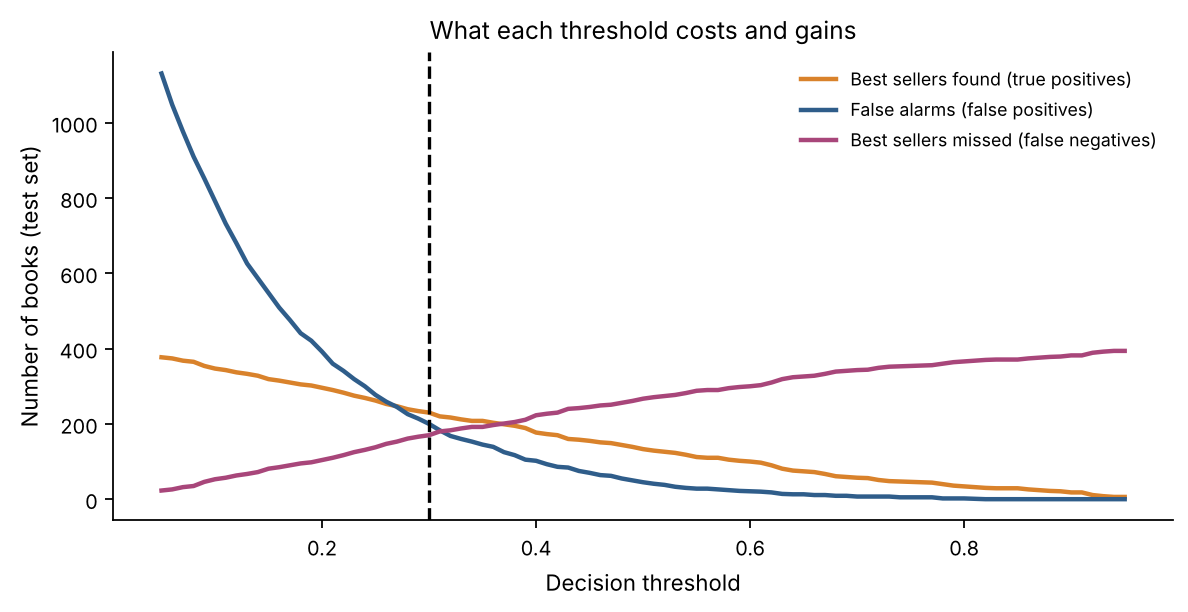

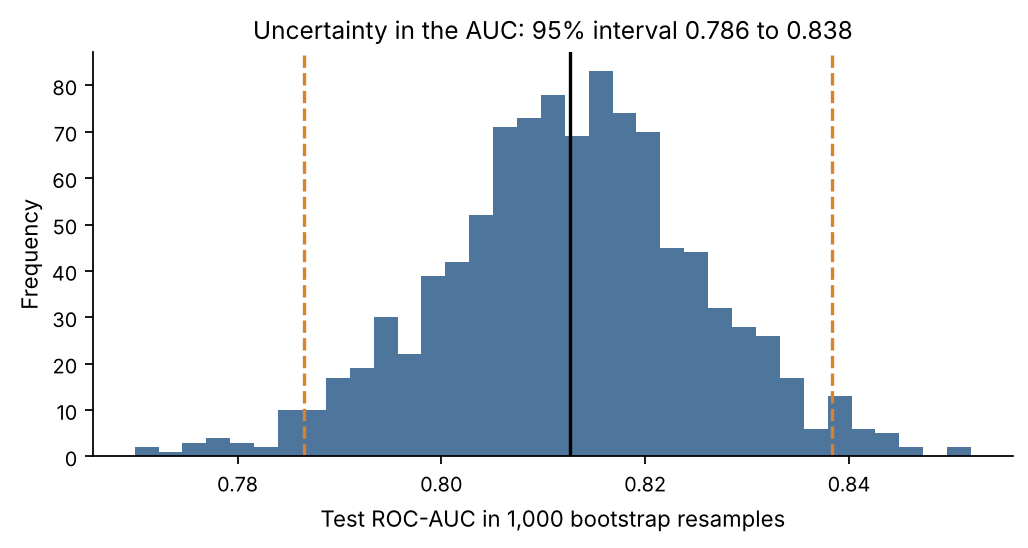

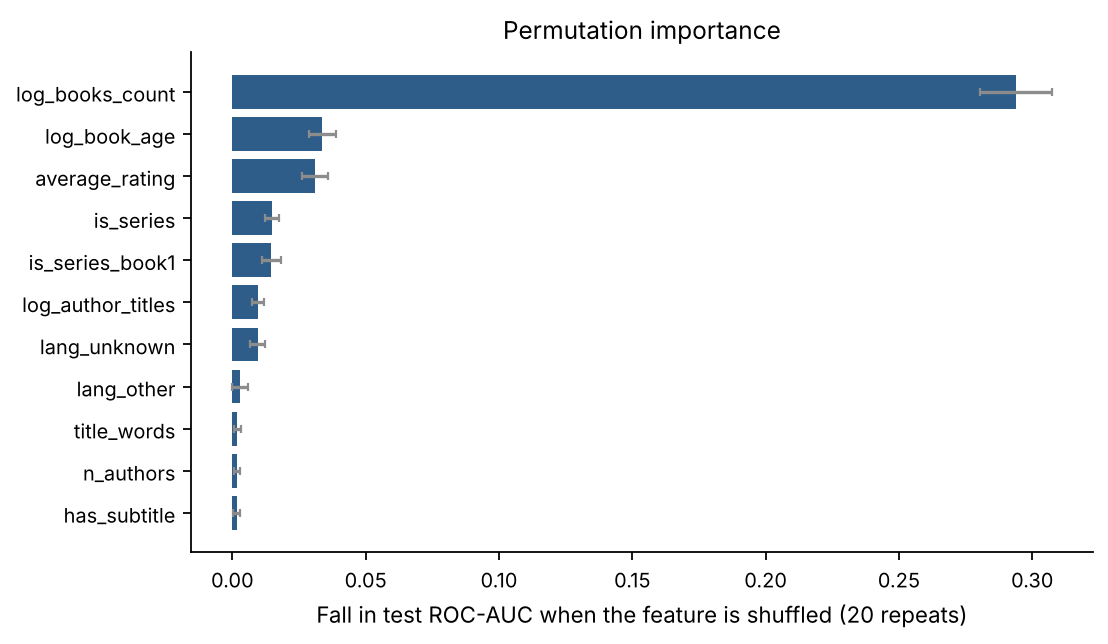

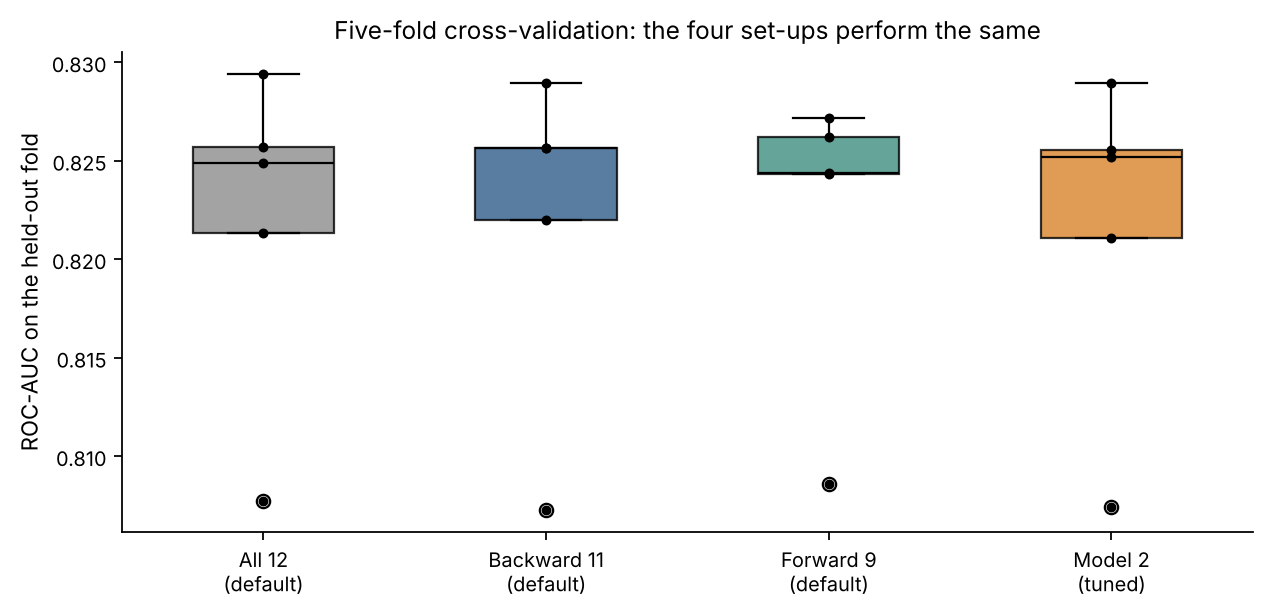

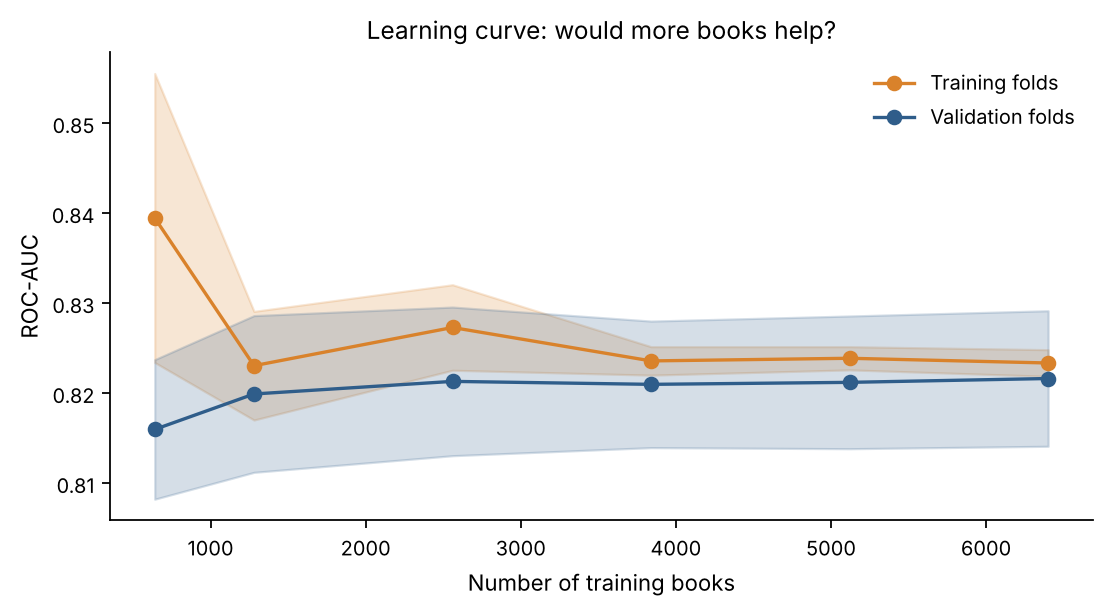

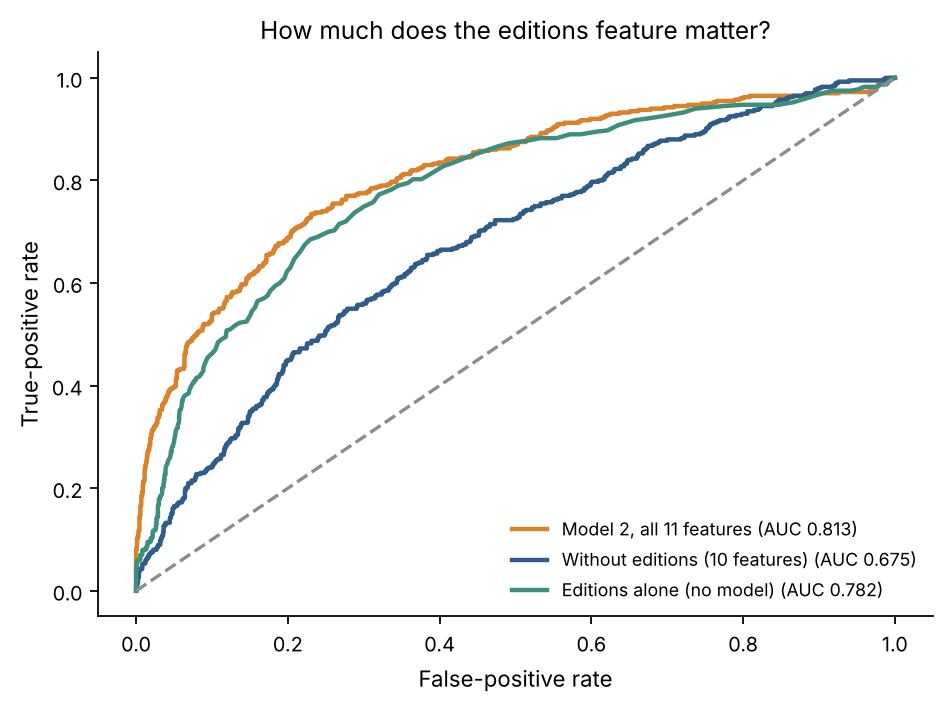

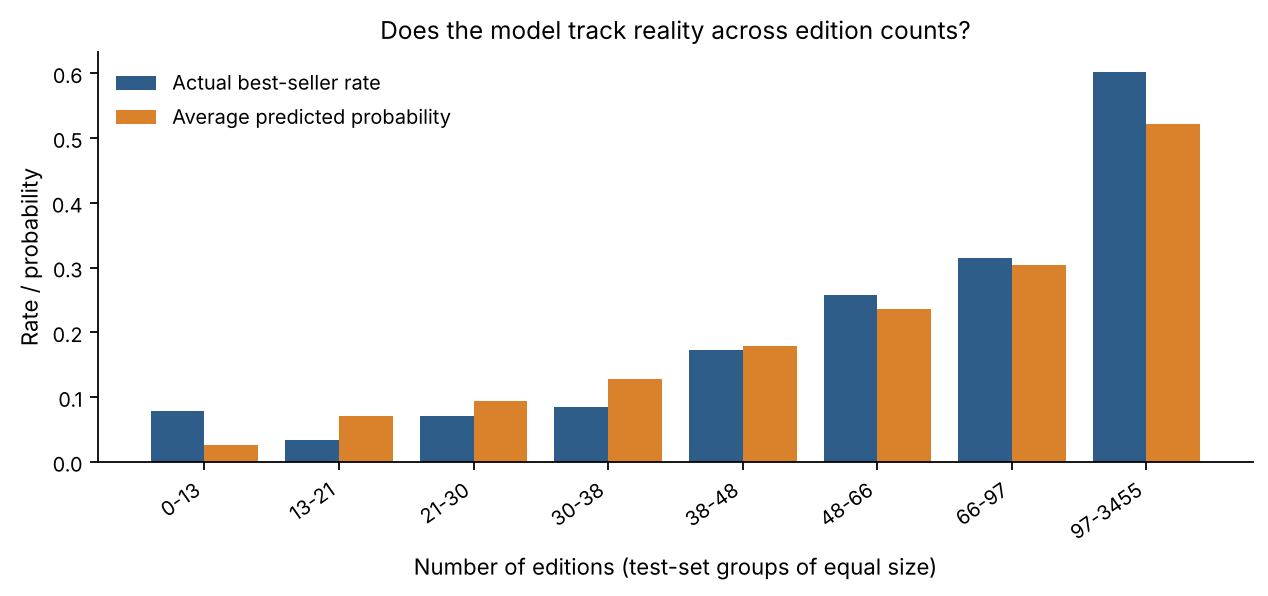

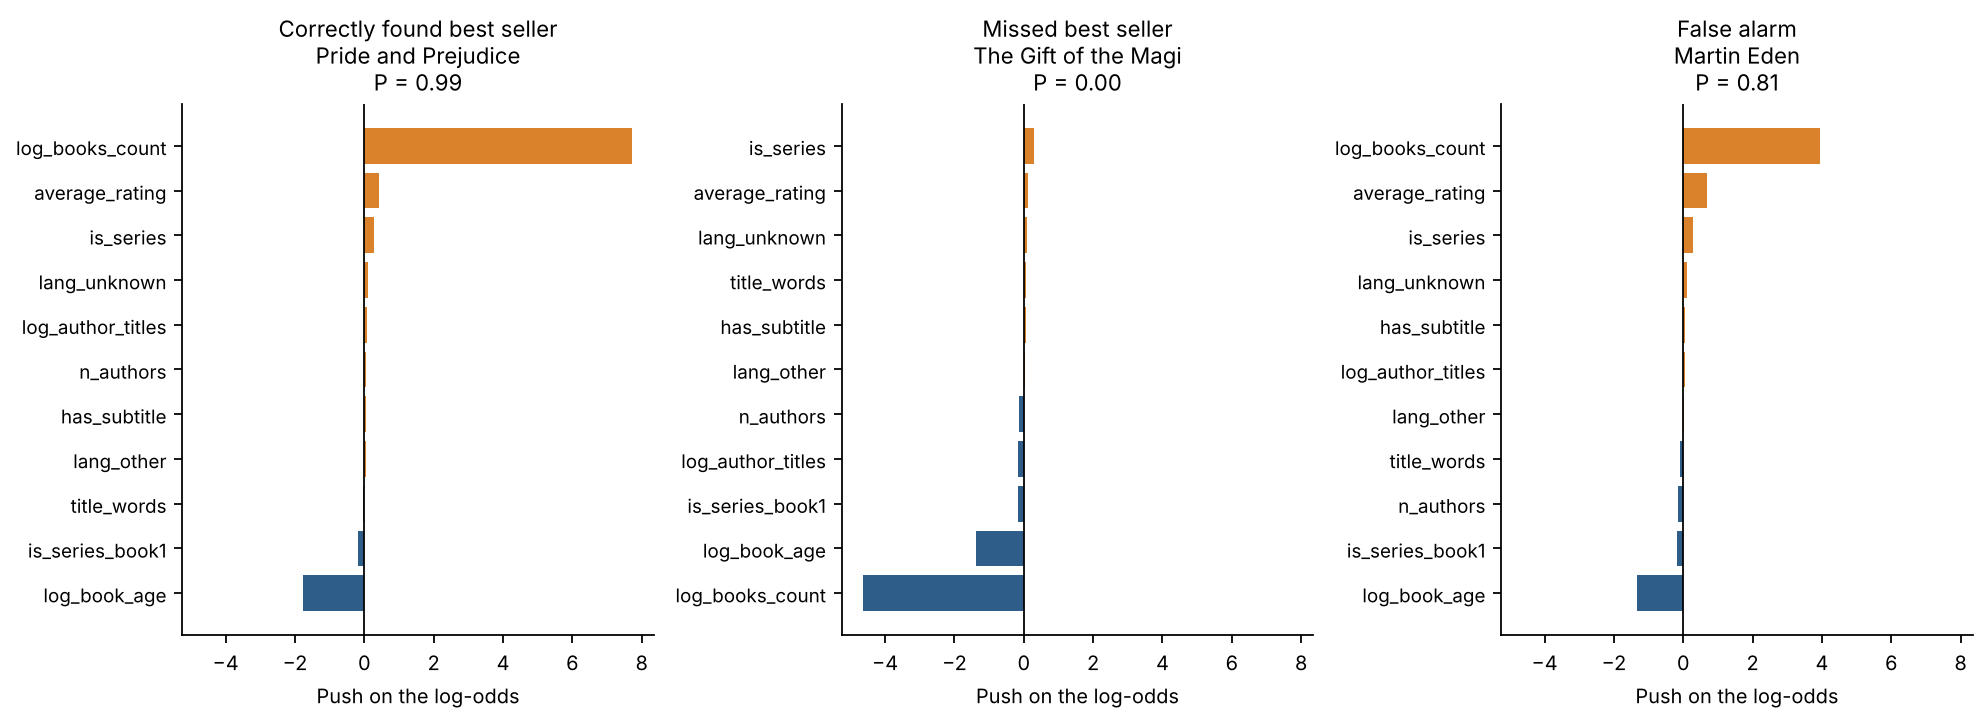

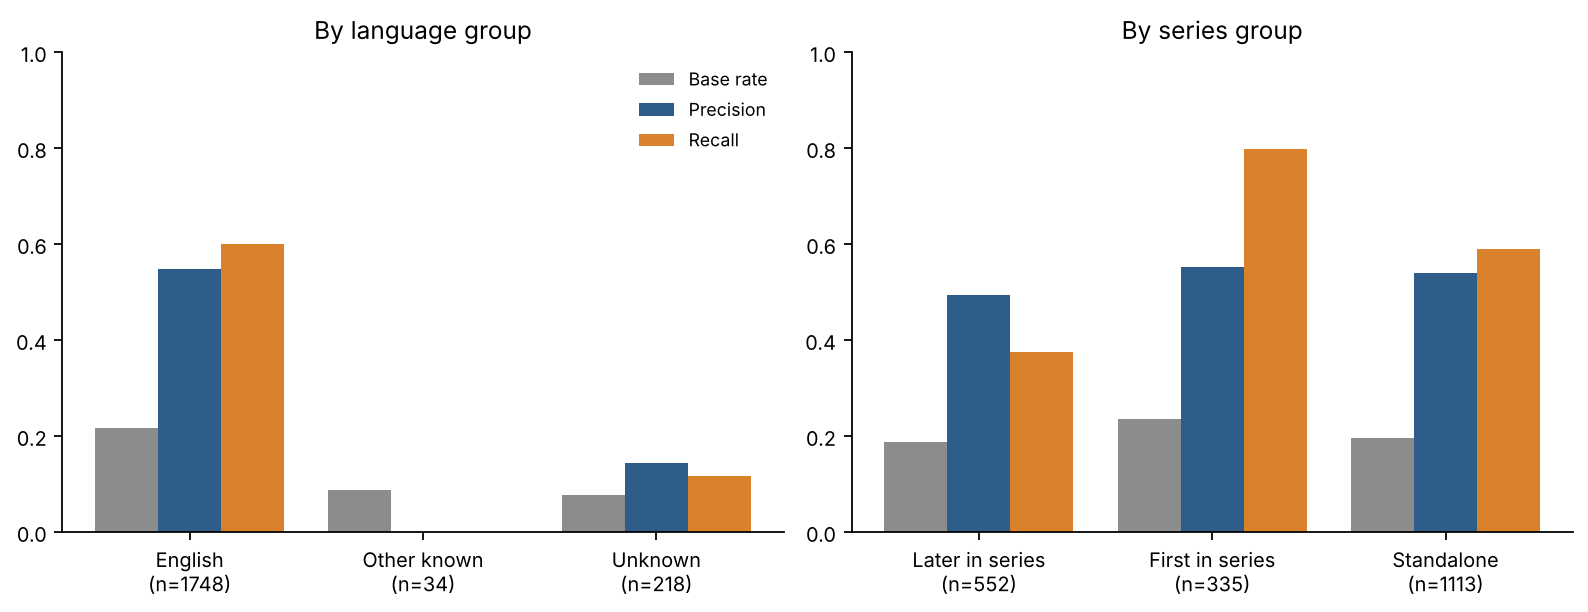

In [16]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

EXTRA2 = {}
CLS = {0: "Not best seller", 1: "Best seller"}

# --- 9.9a Theory: sigmoid and log-loss -------------------------------------------------------------------------
zz = np.linspace(-8, 8, 400)
pp_ = np.linspace(0.001, 0.999, 400)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax[0].plot(zz, sigmoid(zz), color=BLUE, lw=2.2)
ax[0].axhline(0.5, color=GREY, ls=":"); ax[0].axvline(0, color=GREY, ls=":")
ax[0].set_xlabel("score z = w.x + b"); ax[0].set_ylabel("probability p")
ax[0].set_title("Sigmoid: any score becomes a probability")
ax[1].plot(pp_, -np.log(pp_), color=ORANGE, lw=2.2, label="actual = best seller (y = 1)")
ax[1].plot(pp_, -np.log(1 - pp_), color=BLUE, lw=2.2, label="actual = not (y = 0)")
ax[1].set_ylim(0, 5); ax[1].set_xlabel("predicted probability p"); ax[1].set_ylabel("loss for one book")
ax[1].set_title("Log-loss: confident mistakes cost the most"); ax[1].legend(frameon=False, fontsize=8)
savefig("fig27_sigmoid_logloss")

# --- 9.9b Loss surface and the gradient-descent path (2 features so it can be drawn) ---------------------------
i1, i2 = SELECTED.index("log_books_count"), SELECTED.index("average_rating")
X2 = Xs_train[:, [i1, i2]]


def loss2(w, b):
    p = sigmoid(X2 @ w + b)
    return -np.mean(y_train * np.log(p + 1e-12) + (1 - y_train) * np.log(1 - p + 1e-12))


ref = LogisticRegressionScratch(lr=0.5, n_iter=3000, tol=1e-12).fit(X2, y_train)      # converged 2-feature model
w_, b_ = np.zeros(2), 0.0
path = [(w_[0], w_[1], loss2(w_, b_))]
for _ in range(90):                                                                     # plain gradient descent
    p = sigmoid(X2 @ w_ + b_)
    w_ = w_ - 0.5 * (X2.T @ (p - y_train) / len(y_train)); b_ = b_ - 0.5 * np.mean(p - y_train)
    path.append((w_[0], w_[1], loss2(w_, b_)))
path = np.array(path)
g1, g2 = np.linspace(-0.3, 1.9, 70), np.linspace(-0.3, 1.0, 70)
surf = np.array([[loss2(np.array([a, c]), ref.b) for a in g1] for c in g2])
fig, ax = plt.subplots(figsize=(6.8, 4.6))
cs = ax.contourf(g1, g2, surf, levels=22, cmap="Blues_r"); plt.colorbar(cs, label="log-loss")
ax.plot(path[:, 0], path[:, 1], color=ORANGE, lw=2, marker="o", markersize=3, label="gradient descent path")
ax.scatter([ref.w[0]], [ref.w[1]], color="black", marker="*", s=120, zorder=4, label="converged solution")
ax.set_xlabel("weight on log_books_count"); ax.set_ylabel("weight on average_rating")
ax.set_title("Gradient descent walks downhill to the lowest loss"); ax.legend(frameon=False, loc="upper left", fontsize=8)
savefig("fig28_loss_surface")
EXTRA2["gd_path"] = {"start_loss": float(path[0, 2]), "end_loss": float(path[-1, 2]), "steps": 90, "final_w": [float(w_[0]), float(w_[1])],
                     "ref_w": [float(ref.w[0]), float(ref.w[1])]}

# --- 9.9c Learning rates compared ----------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 3.8))
lr_final = {}
for lr_, col in zip([0.01, 0.05, 0.1, 0.5], [GREY, "#6C5B9E", BLUE, ORANGE]):
    m_ = LogisticRegressionScratch(lr=lr_, n_iter=300, tol=0).fit(Xs_train, y_train)
    ax.plot(m_.loss_history, color=col, lw=2, label=f"learning rate {lr_}")
    lr_final[str(lr_)] = float(m_.loss_history[-1])
ax.set_xlabel("Iteration"); ax.set_ylabel("Training log-loss"); ax.set_title("Effect of the learning rate on convergence (first 300 iterations)")
ax.legend(frameon=False)
savefig("fig29_learning_rates")
EXTRA2["loss_after_300"] = lr_final

# --- 9.9d Predicted probabilities by true class ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 3.8))
bins_ = np.linspace(0, 1, 41)
ax.hist(p2_test[y_test == 0], bins=bins_, alpha=0.7, color=BLUE, label="Not best seller")
ax.hist(p2_test[y_test == 1], bins=bins_, alpha=0.7, color=ORANGE, label="Best seller")
ax.axvline(0.5, color=GREY, ls="--"); ax.text(0.505, ax.get_ylim()[1] * 0.9, "default 0.50", fontsize=8, color=GREY)
ax.axvline(best_thr, color="black", ls="--"); ax.text(best_thr + 0.005, ax.get_ylim()[1] * 0.78, f"chosen {best_thr:.2f}", fontsize=8)
ax.set_xlabel("Predicted probability of being a best seller (test set)"); ax.set_ylabel("Number of books")
ax.set_title("How well the two classes are separated"); ax.legend(frameon=False)
savefig("fig30_probability_distribution")
EXTRA2["median_prob"] = {CLS[c]: float(np.median(p2_test[y_test == c])) for c in (0, 1)}

# --- 9.9e Metrics side by side ------------------------------------------------------------------------------------------
keys = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "mcc"]
fig, ax = plt.subplots(figsize=(9, 3.9))
x_ = np.arange(len(keys))
b1 = ax.bar(x_ - 0.2, [m1_test[k] for k in keys], 0.4, color=BLUE, label="Model 1 (threshold 0.50)")
b2 = ax.bar(x_ + 0.2, [m2_test[k] for k in keys], 0.4, color=ORANGE, label=f"Model 2 (threshold {best_thr:.2f})")
for bars in (b1, b2):
    for r_ in bars:
        ax.text(r_.get_x() + r_.get_width() / 2, r_.get_height() + 0.012, f"{r_.get_height():.2f}", ha="center", fontsize=7)
ax.set_xticks(x_); ax.set_xticklabels(["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "PR-AUC", "MCC"])
ax.set_ylim(0, 1.08); ax.set_title("Model 1 versus Model 2 on the test set"); ax.legend(frameon=False, ncol=2, loc="upper right")
savefig("fig31_metrics_comparison")

# --- 9.9f Normalised confusion matrices ---------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(8.5, 3.6))
for a, m, title in [(ax[0], m1_test, "Model 1"), (ax[1], m2_test, "Model 2")]:
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], dtype=float)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cmn[i, j]:.1%}\n({int(cm[i, j])})" for j in range(2)] for i in range(2)]), fmt="",
                cmap="Blues", cbar=False, ax=a, vmin=0, vmax=1,
                xticklabels=["Pred: not", "Pred: best seller"], yticklabels=["Actual: not", "Actual: best seller"])
    a.set_title(f"{title}: share of each actual class")
savefig("fig32_confusion_normalised")

# --- 9.9g Calibration ----------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
calib = {}
for proba, lab, col in [(p1_test, "Model 1", BLUE), (p2_test, "Model 2", ORANGE)]:
    fr, mp = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
    ax[0].plot(mp, fr, marker="o", color=col, label=f"{lab} (Brier {brier_score_loss(y_test, proba):.3f})")
    calib[lab] = {"brier": float(brier_score_loss(y_test, proba)), "pred": mp.round(3).tolist(), "actual": fr.round(3).tolist()}
ax[0].plot([0, 1], [0, 1], color=GREY, ls="--", label="perfect calibration")
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Share that really are best sellers")
ax[0].set_title("Calibration (10 equal-size groups)"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(p2_test, bins=30, color=ORANGE); ax[1].set_yscale("log")
ax[1].set_xlabel("Predicted probability (Model 2)"); ax[1].set_ylabel("Books (log scale)"); ax[1].set_title("Most books get a low probability")
savefig("fig33_calibration")
EXTRA2["calibration"] = calib
EXTRA2["brier_baseline"] = float(brier_score_loss(y_test, np.full_like(y_test, y_train.mean())))

# --- 9.9h Cumulative gains and lift --------------------------------------------------------------------------------------
order_ = np.argsort(-p2_test)
cum_pos = np.cumsum(y_test[order_]) / y_test.sum()
frac = np.arange(1, len(y_test) + 1) / len(y_test)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
ax[0].plot(frac * 100, cum_pos * 100, color=ORANGE, lw=2.2, label="Model 2"); ax[0].plot([0, 100], [0, 100], color=GREY, ls="--", label="random picking")
ax[0].set_xlabel("Books reviewed, highest score first (%)"); ax[0].set_ylabel("Best sellers found (%)"); ax[0].set_title("Cumulative gains"); ax[0].legend(frameon=False)
ax[1].plot(frac * 100, cum_pos / frac, color=BLUE, lw=2.2); ax[1].axhline(1, color=GREY, ls="--")
ax[1].set_xlabel("Books reviewed (%)"); ax[1].set_ylabel("Lift (times better than random)"); ax[1].set_title("Lift curve"); ax[1].set_xlim(0, 100)
savefig("fig34_gains_lift")
dec_tab = []
for q in (0.1, 0.2, 0.3, 0.5):
    k_ = int(len(y_test) * q)
    dec_tab.append({"reviewed_pct": int(q * 100), "found_pct": round(float(cum_pos[k_ - 1] * 100), 1), "lift": round(float(cum_pos[k_ - 1] / q), 2)})
EXTRA2["gains"] = dec_tab

# --- 9.9i What happens as the threshold moves? ----------------------------------------------------------------------------
thr_ = np.linspace(0.05, 0.95, 91)
tp_ = np.array([((p2_test >= t) & (y_test == 1)).sum() for t in thr_]); fp_ = np.array([((p2_test >= t) & (y_test == 0)).sum() for t in thr_])
fn_ = np.array([((p2_test < t) & (y_test == 1)).sum() for t in thr_])
fig, ax = plt.subplots(figsize=(7.5, 3.9))
ax.plot(thr_, tp_, color=ORANGE, lw=2, label="Best sellers found (true positives)")
ax.plot(thr_, fp_, color=BLUE, lw=2, label="False alarms (false positives)")
ax.plot(thr_, fn_, color="#A8467A", lw=2, label="Best sellers missed (false negatives)")
ax.axvline(best_thr, color="black", ls="--"); ax.set_xlabel("Decision threshold"); ax.set_ylabel("Number of books (test set)")
ax.set_title("What each threshold costs and gains"); ax.legend(frameon=False, fontsize=8)
savefig("fig35_threshold_outcomes")
EXTRA2["threshold_table"] = [{"thr": float(t), "found": int(tp_[np.argmin(abs(thr_ - t))]), "false_alarms": int(fp_[np.argmin(abs(thr_ - t))]),
                              "missed": int(fn_[np.argmin(abs(thr_ - t))])} for t in (0.2, 0.3, 0.4, 0.5, 0.6)]

# --- 9.9j Bootstrap distribution of the AUC -----------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(boot, bins=35, color=BLUE, alpha=0.85)
ax.axvline(auc_ci[0], color=ORANGE, ls="--"); ax.axvline(auc_ci[1], color=ORANGE, ls="--"); ax.axvline(np.mean(boot), color="black")
ax.set_xlabel("Test ROC-AUC in 1,000 bootstrap resamples"); ax.set_ylabel("Frequency")
ax.set_title(f"Uncertainty in the AUC: 95% interval {auc_ci[0]:.3f} to {auc_ci[1]:.3f}")
savefig("fig36_bootstrap_auc")

# --- 9.9k Permutation importance (how much does AUC fall when one feature is shuffled?) -----------------------------
rng2 = np.random.default_rng(RANDOM_STATE)
base_auc = roc_auc_score(y_test, p2_test)
perm = {}
for j, f in enumerate(SELECTED):
    drops = []
    for _ in range(20):
        Xp = Xs_test.copy(); Xp[:, j] = rng2.permutation(Xp[:, j])
        drops.append(base_auc - roc_auc_score(y_test, model2.predict_proba(Xp)))
    perm[f] = (float(np.mean(drops)), float(np.std(drops)))
perm_s = pd.DataFrame(perm, index=["drop", "sd"]).T.sort_values("drop")
fig, ax = plt.subplots(figsize=(7, 4.1))
ax.barh(perm_s.index, perm_s["drop"], xerr=perm_s["sd"], color=BLUE, ecolor=GREY, capsize=2)
ax.set_xlabel("Fall in test ROC-AUC when the feature is shuffled (20 repeats)"); ax.set_title("Permutation importance")
savefig("fig37_permutation_importance")
EXTRA2["permutation"] = {k: [round(v[0], 4), round(v[1], 4)] for k, v in perm.items()}

# --- 9.9l Stability across cross-validation folds --------------------------------------------------------------------------
def fold_aucs(params, features, n_splits=5):
    cols = [col_idx[f] for f in features]; Xcv = X_train_raw[:, cols]; out = []
    for tr, va in StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE).split(Xcv, y_train):
        m_, s_ = fit_scaler(Xcv[tr])
        mdl = LogisticRegressionScratch(**params).fit((Xcv[tr] - m_) / s_, y_train[tr])
        out.append(roc_auc_score(y_train[va], mdl.predict_proba((Xcv[va] - m_) / s_)))
    return out


fold_sets = {"All 12\n(default)": (FEATURES, default_params), "Backward 11\n(default)": (SELECTED, default_params),
             "Forward 9\n(default)": (fs[ALPHA_MAIN]["forward_selected"], default_params), "Model 2\n(tuned)": (SELECTED, best_params)}
fold_res = {k: fold_aucs(p_, f_) for k, (f_, p_) in fold_sets.items()}
fig, ax = plt.subplots(figsize=(8, 3.9))
bp = ax.boxplot(list(fold_res.values()), patch_artist=True, widths=0.5, medianprops=dict(color="black"), tick_labels=list(fold_res.keys()))
for patch, col in zip(bp["boxes"], [GREY, BLUE, "#3E8E7E", ORANGE]):
    patch.set_facecolor(col); patch.set_alpha(0.8)
for i, v in enumerate(fold_res.values(), start=1):
    ax.scatter([i] * len(v), v, color="black", s=12, zorder=3)
ax.set_ylabel("ROC-AUC on the held-out fold"); ax.set_title("Five-fold cross-validation: the four set-ups perform the same")
savefig("fig38_cv_folds")
EXTRA2["cv_folds"] = {k.replace("\n", " "): {"mean": round(float(np.mean(v)), 4), "sd": round(float(np.std(v)), 4), "min": round(float(np.min(v)), 4), "max": round(float(np.max(v)), 4)} for k, v in fold_res.items()}

# --- 9.9m Learning curve ------------------------------------------------------------------------------------------------------
cols_sel = [col_idx[f] for f in SELECTED]; Xlc = X_train_raw[:, cols_sel]
sizes = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]; lc_tr, lc_va = {s: [] for s in sizes}, {s: [] for s in sizes}
rng3 = np.random.default_rng(RANDOM_STATE)
for tr, va in StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(Xlc, y_train):
    perm_idx = rng3.permutation(tr)
    for s in sizes:
        sub = perm_idx[: int(len(tr) * s)]
        m_, s_ = fit_scaler(Xlc[sub])
        mdl = LogisticRegressionScratch(**best_params).fit((Xlc[sub] - m_) / s_, y_train[sub])
        lc_tr[s].append(roc_auc_score(y_train[sub], mdl.predict_proba((Xlc[sub] - m_) / s_)))
        lc_va[s].append(roc_auc_score(y_train[va], mdl.predict_proba((Xlc[va] - m_) / s_)))
n_axis = [int(len(y_train) * 0.8 * s) for s in sizes]
fig, ax = plt.subplots(figsize=(7, 3.9))
for dct, col, lab in [(lc_tr, ORANGE, "Training folds"), (lc_va, BLUE, "Validation folds")]:
    mu_ = np.array([np.mean(dct[s]) for s in sizes]); sd_ = np.array([np.std(dct[s]) for s in sizes])
    ax.plot(n_axis, mu_, marker="o", color=col, label=lab); ax.fill_between(n_axis, mu_ - sd_, mu_ + sd_, color=col, alpha=0.2)
ax.set_xlabel("Number of training books"); ax.set_ylabel("ROC-AUC"); ax.set_title("Learning curve: would more books help?"); ax.legend(frameon=False)
savefig("fig39_learning_curve")
EXTRA2["learning_curve"] = {"sizes": n_axis, "train": [round(float(np.mean(lc_tr[s])), 4) for s in sizes], "val": [round(float(np.mean(lc_va[s])), 4) for s in sizes]}

# --- 9.9n ROC with and without editions ---------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4.5))
ed_col = col_idx["log_books_count"]
for score, lab, col in [(p2_test, "Model 2, all 11 features", ORANGE), (p_ne, "Without editions (10 features)", BLUE),
                        (X_test_raw[:, ed_col], "Editions alone (no model)", "#3E8E7E")]:
    fpr_, tpr_, _ = roc_curve(y_test, score)
    ax.plot(fpr_, tpr_, color=col, lw=2, label=f"{lab} (AUC {roc_auc_score(y_test, score):.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--"); ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title("How much does the editions feature matter?"); ax.legend(frameon=False, fontsize=8, loc="lower right")
savefig("fig40_roc_without_editions")
EXTRA2["editions_alone_auc"] = float(roc_auc_score(y_test, X_test_raw[:, ed_col]))

# --- 9.9o Predicted versus actual rate by editions group -----------------------------------------------------------------------
te = model_df.iloc[idx_test].copy(); te["p"] = p2_test
te["ed_bin"] = pd.qcut(te["log_books_count"], 8, duplicates="drop")
gb = te.groupby("ed_bin", observed=True).agg(actual=("bestseller", "mean"), predicted=("p", "mean"), n=("p", "size"))
fig, ax = plt.subplots(figsize=(8, 3.8))
xg = np.arange(len(gb))
ax.bar(xg - 0.2, gb["actual"], 0.4, color=BLUE, label="Actual best-seller rate"); ax.bar(xg + 0.2, gb["predicted"], 0.4, color=ORANGE, label="Average predicted probability")
ax.set_xticks(xg); ax.set_xticklabels([f"{int(np.expm1(iv.left))}-{int(np.expm1(iv.right))}" for iv in gb.index], rotation=35, ha="right")
ax.set_xlabel("Number of editions (test-set groups of equal size)"); ax.set_ylabel("Rate / probability"); ax.set_title("Does the model track reality across edition counts?"); ax.legend(frameon=False)
savefig("fig41_actual_vs_predicted")
EXTRA2["editions_groups"] = [{"bin": f"{int(np.expm1(iv.left))}-{int(np.expm1(iv.right))}", "actual": round(float(r.actual), 3), "pred": round(float(r.predicted), 3), "n": int(r.n)} for iv, r in gb.iterrows()]

# --- 9.9p Explaining individual predictions ---------------------------------------------------------------------------------------
pos_idx, neg_idx = np.where(y_test == 1)[0], np.where(y_test == 0)[0]
cases = [("Correctly found best seller", pos_idx[np.argmax(p2_test[pos_idx])]),
         ("Missed best seller", pos_idx[np.argmin(p2_test[pos_idx])]),
         ("False alarm", neg_idx[np.argmax(p2_test[neg_idx])])]
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.6), sharex=True)
case_info = []
for a, (lab, i) in zip(axes, cases):
    contrib = pd.Series(model2.w * Xs_test[i], index=SELECTED).sort_values()
    a.barh(contrib.index, contrib.values, color=[ORANGE if v > 0 else BLUE for v in contrib.values])
    ttl = model_df.iloc[idx_test[i]]["title"]; ttl = ttl if len(ttl) < 28 else ttl[:26] + "..."
    a.set_title(f"{lab}\n{ttl}\nP = {p2_test[i]:.2f}", fontsize=10); a.axvline(0, color="black", lw=0.8); a.set_xlabel("Push on the log-odds", fontsize=9); a.tick_params(axis='y', labelsize=8.5)
    case_info.append({"case": lab, "title": model_df.iloc[idx_test[i]]["title"], "p": round(float(p2_test[i]), 3),
                      "top_up": contrib.sort_values(ascending=False).index[0], "top_down": contrib.index[0]})
savefig("fig42_local_explanations")
EXTRA2["cases"] = case_info

# --- 9.9q Performance by segment ------------------------------------------------------------------------------------------------------
seg_rows = []
lg_te, sg_te = lang_grp[idx_test], series_grp[idx_test]
pred_te = (p2_test >= best_thr).astype(int)
for name, arr in [("Language", lg_te), ("Series", sg_te)]:
    for g_ in pd.unique(arr):
        m = arr == g_
        seg_rows.append({"type": name, "group": g_, "n": int(m.sum()), "rate": float(y_test[m].mean()),
                         "precision": float(precision_score(y_test[m], pred_te[m], zero_division=0)),
                         "recall": float(recall_score(y_test[m], pred_te[m])) if y_test[m].sum() else float("nan")})
seg = pd.DataFrame(seg_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
for a, tname in zip(axes, ["Language", "Series"]):
    s_ = seg[seg.type == tname]; xs_ = np.arange(len(s_))
    a.bar(xs_ - 0.27, s_["rate"], 0.27, color=GREY, label="Base rate"); a.bar(xs_, s_["precision"], 0.27, color=BLUE, label="Precision")
    a.bar(xs_ + 0.27, s_["recall"], 0.27, color=ORANGE, label="Recall")
    a.set_xticks(xs_); a.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(s_["group"], s_["n"])]); a.set_title(f"By {tname.lower()} group"); a.set_ylim(0, 1)
axes[0].legend(frameon=False, fontsize=8)
savefig("fig43_segments")
EXTRA2["segments"] = seg.round(3).to_dict("records")

RESULTS["extra_eda"] = EXTRA
RESULTS["extra_model"] = EXTRA2

## 9b. Extended evaluation and training diagnostics
This section looks at the models from many more angles:
* **How the metrics compare** (bar chart, radar chart, prediction outcomes as donut charts)
* **How the scores behave** (score distributions, KS statistic, calibration, deciles)
* **How useful the ranking is for a publisher** (cumulative gains and lift)
* **How costly mistakes change the best threshold**
* **How stable the model is** (learning curve, fold-to-fold variation, bootstrap, subgroups)
* **What the model relies on** (permutation importance, adding features one at a time)
* **How training behaves** (learning rates, convergence, the loss surface, regularisation path, decision surface)

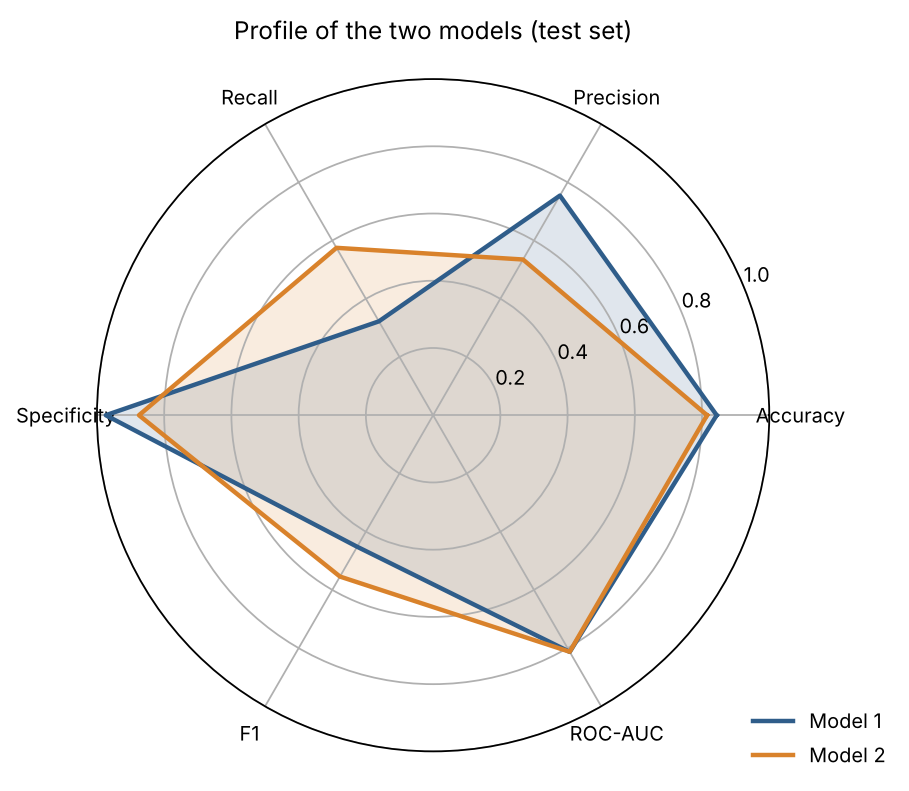

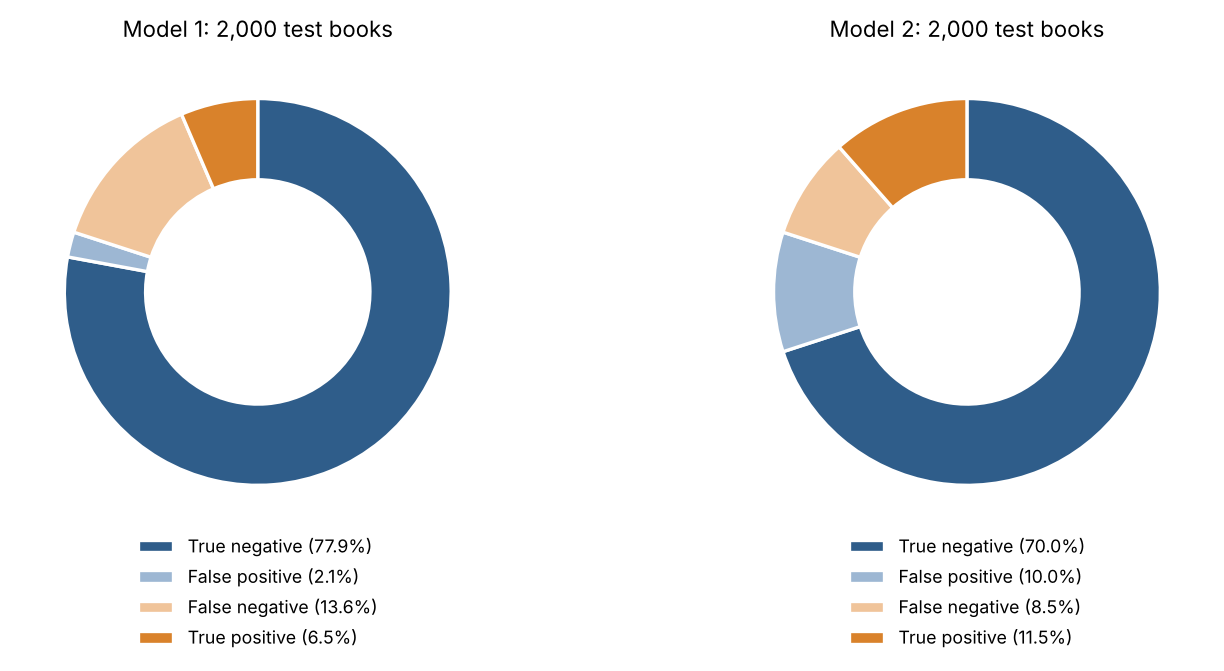

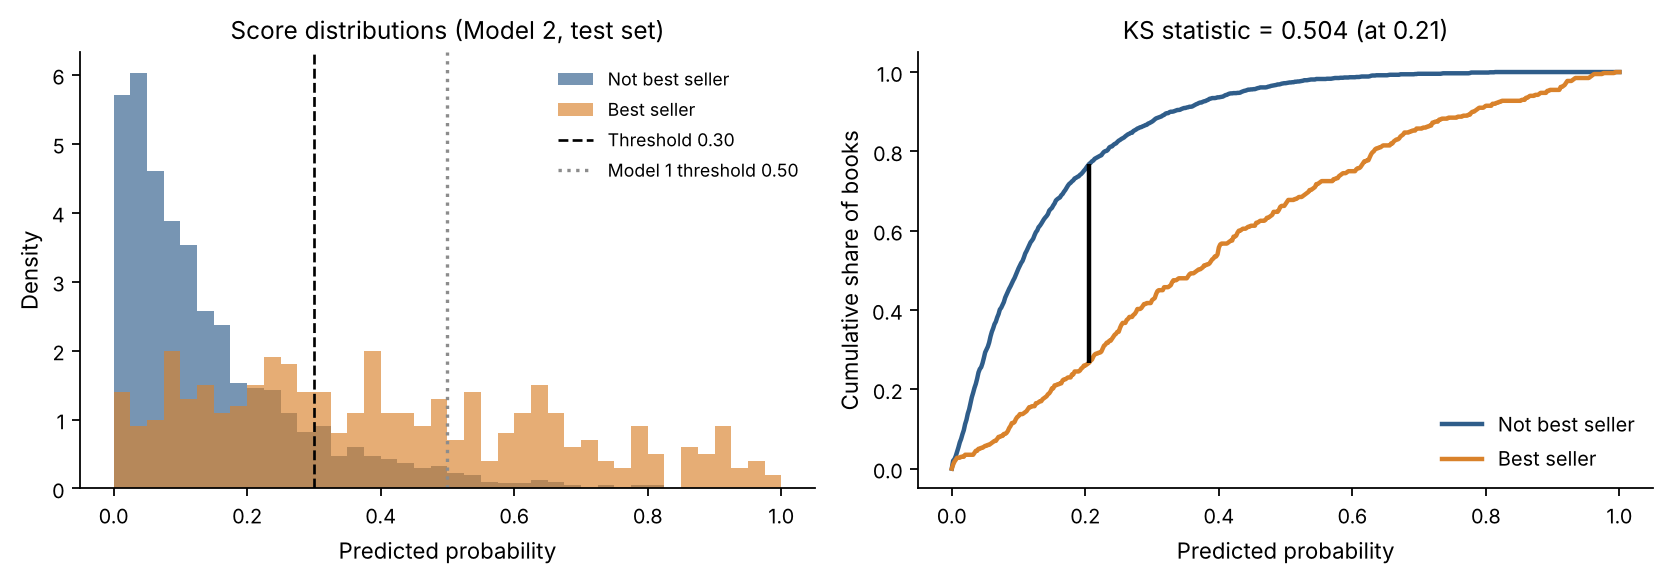

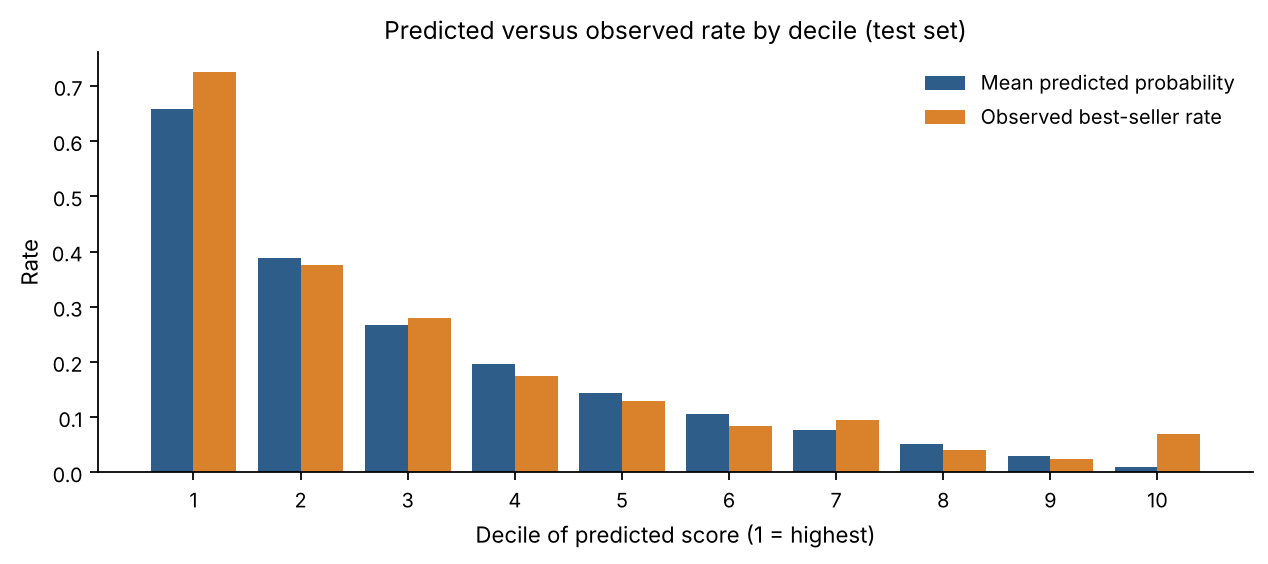

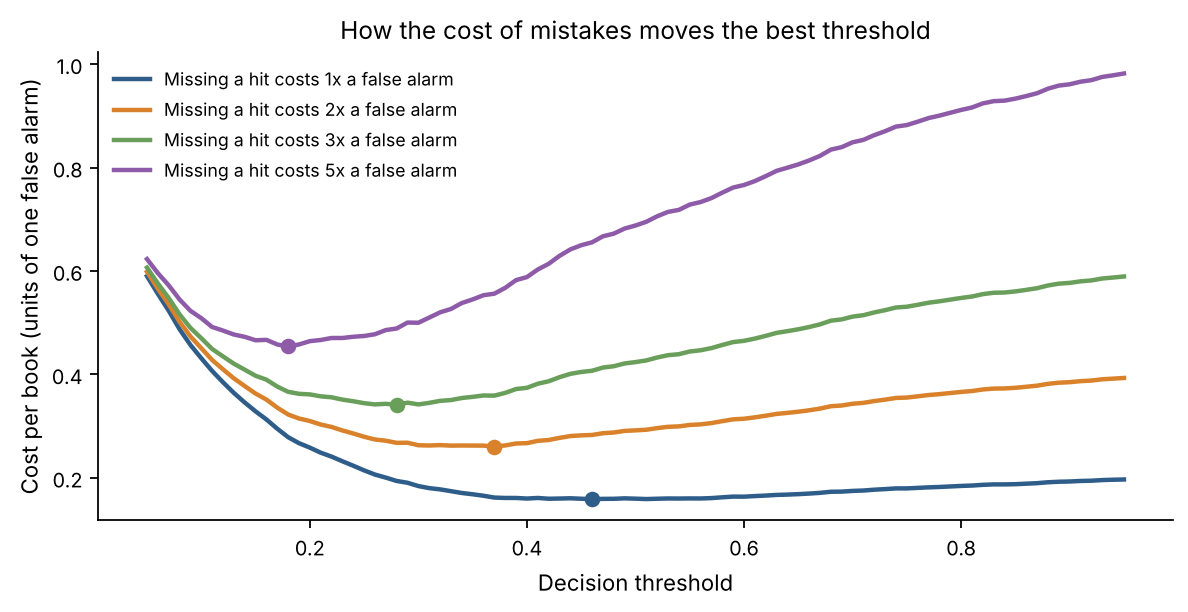

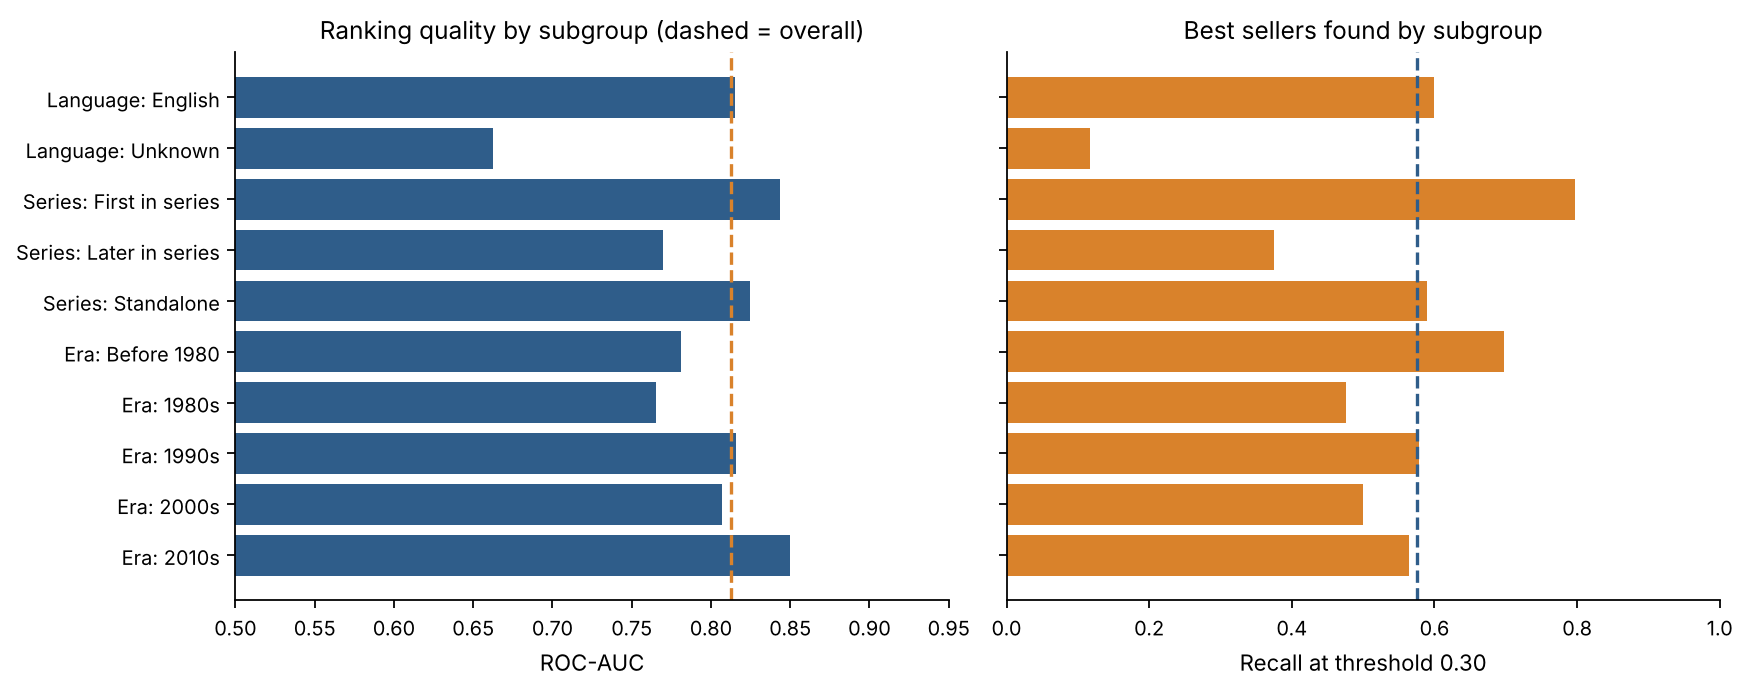

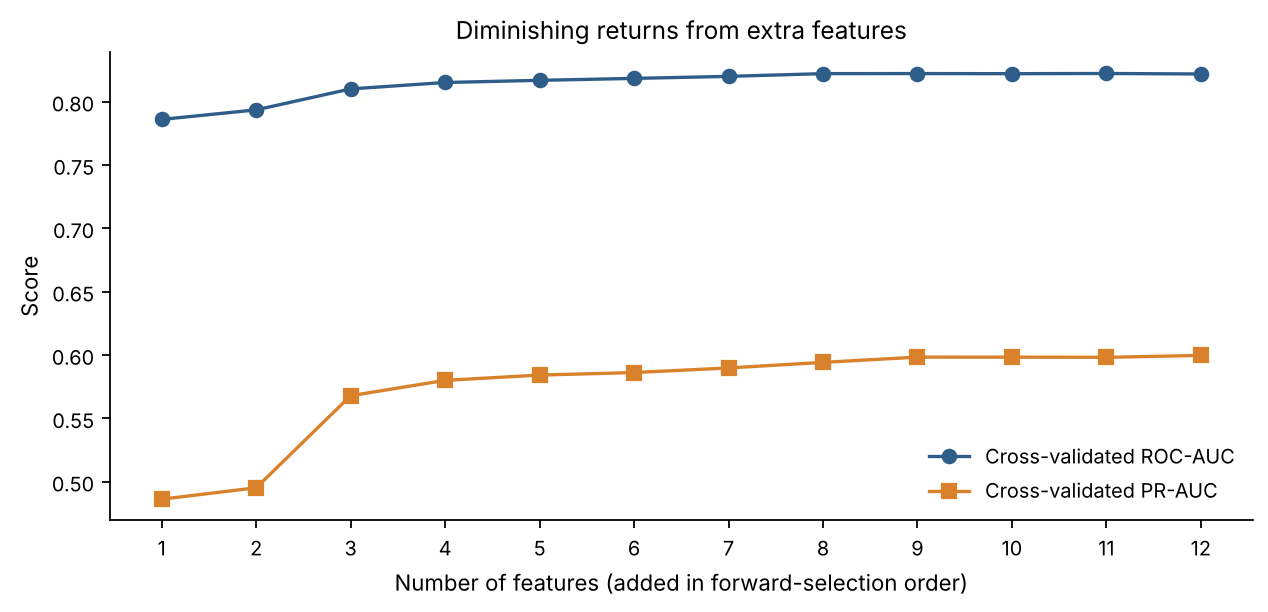

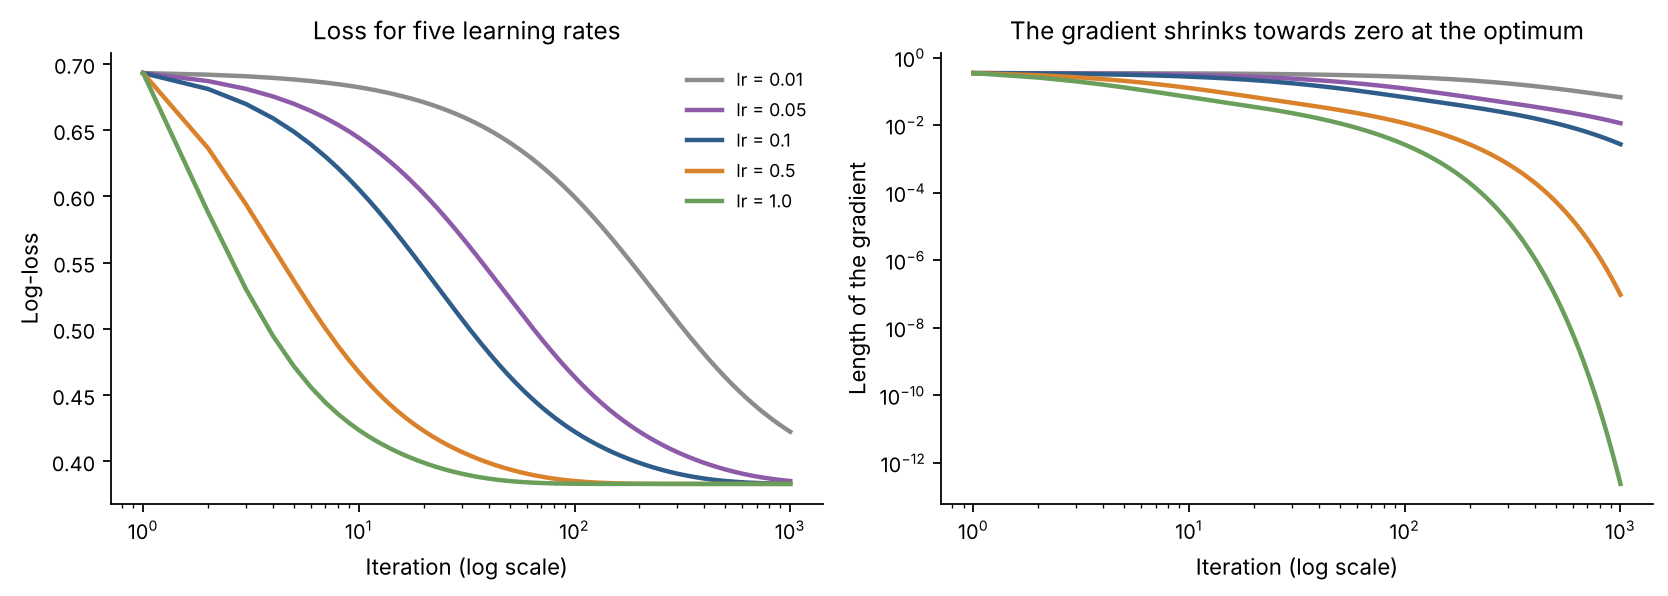

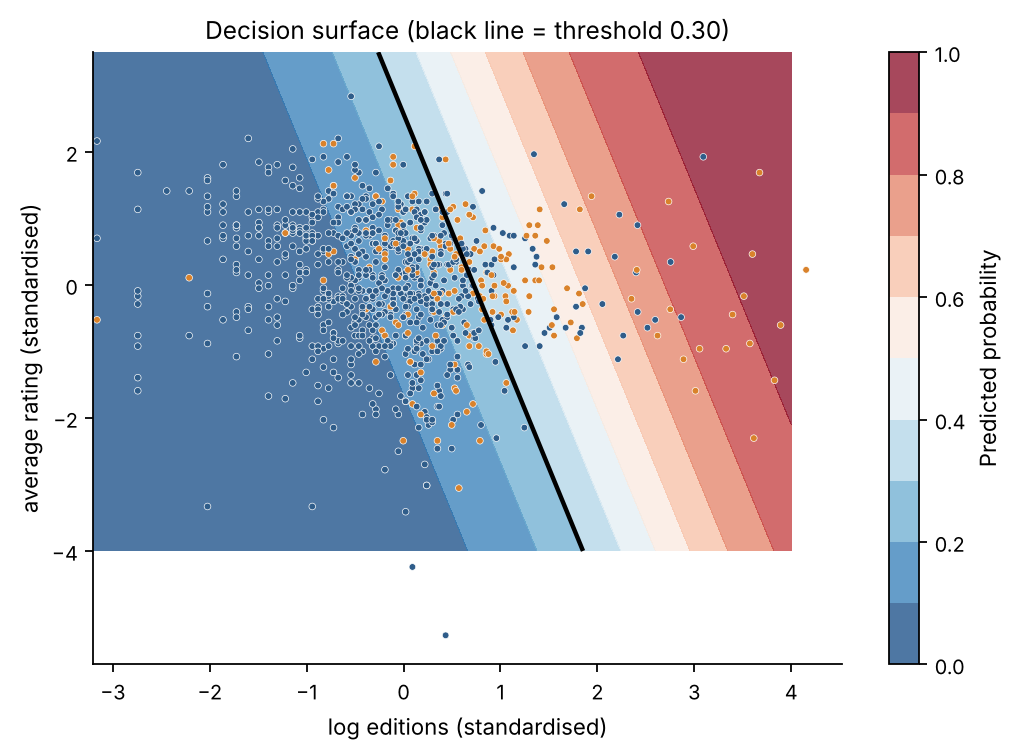

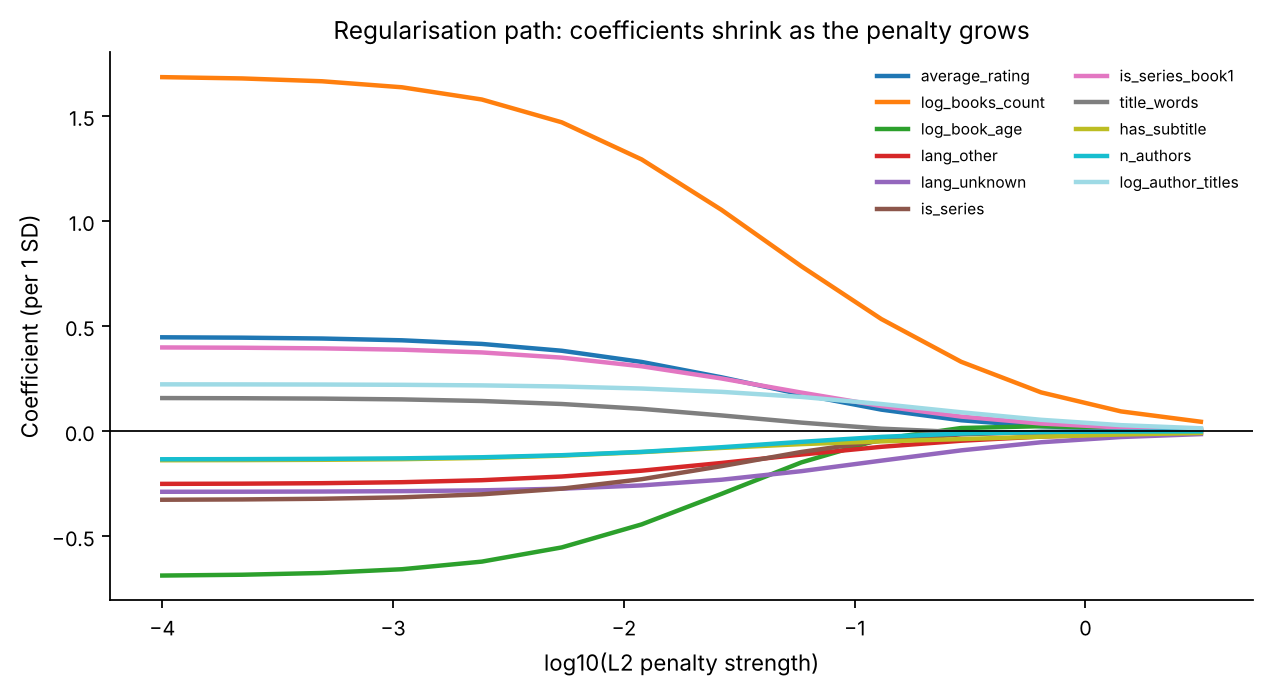

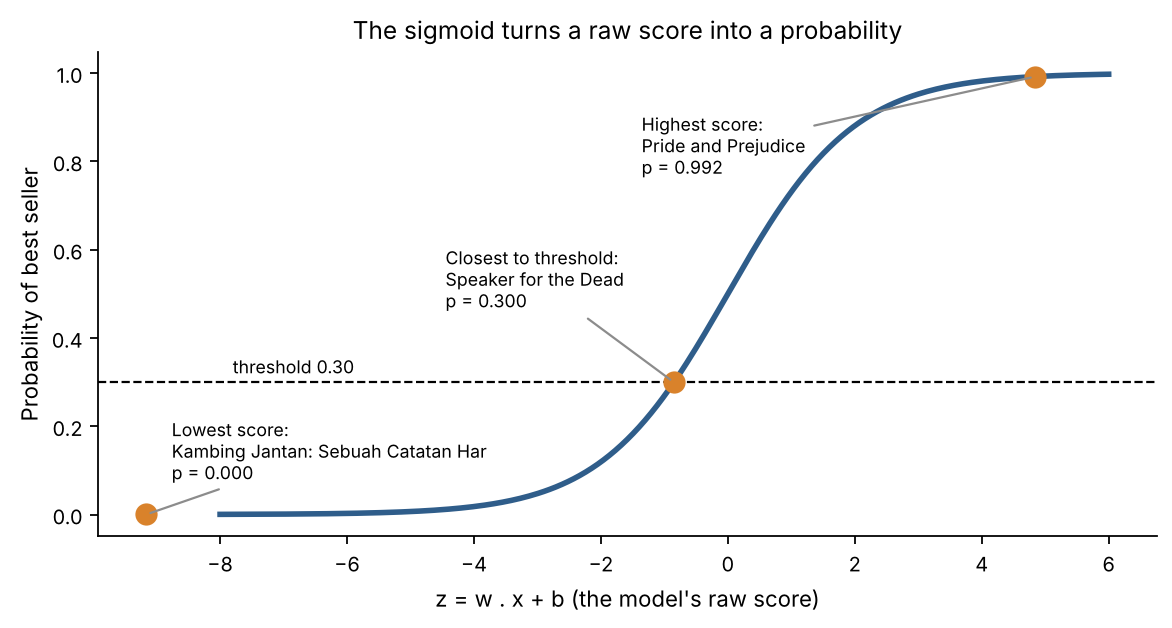

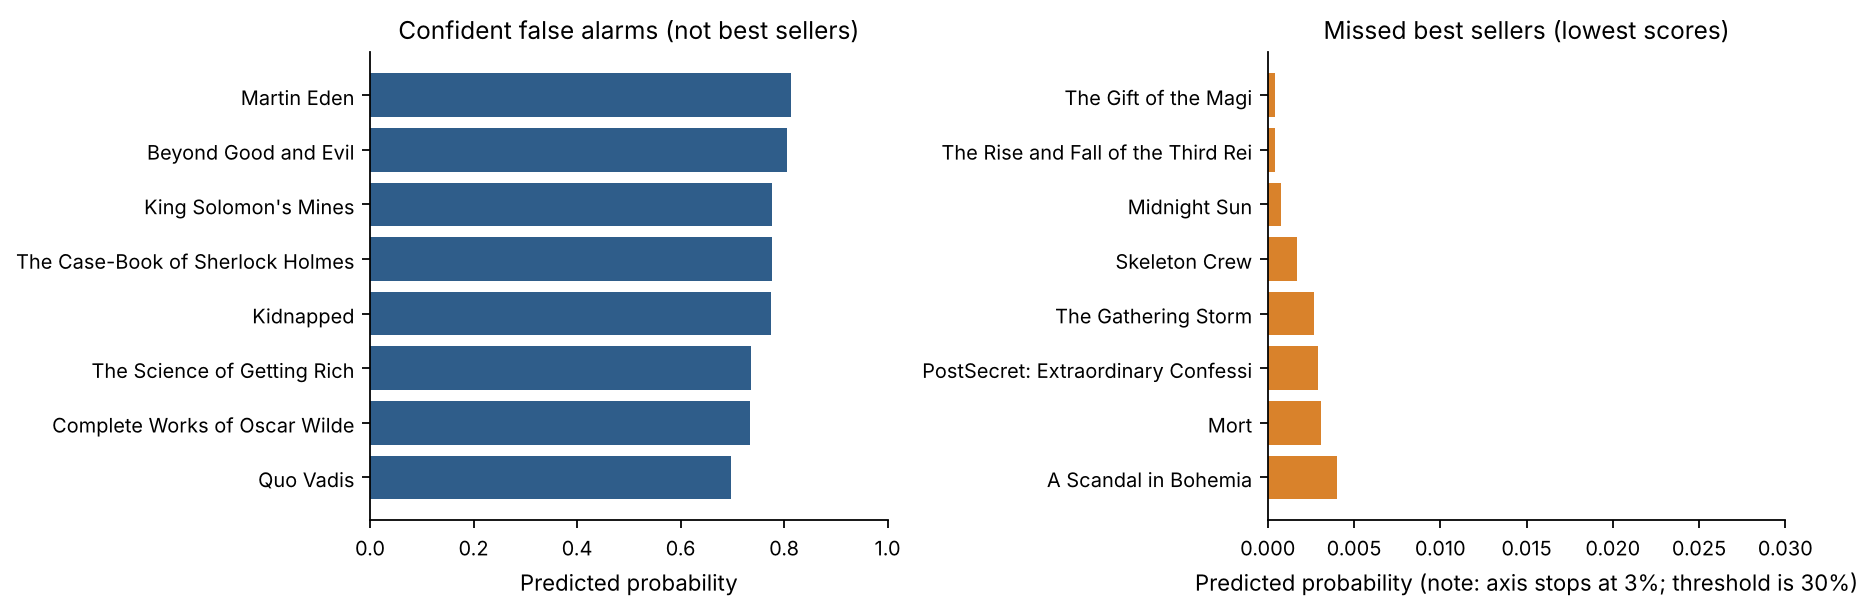

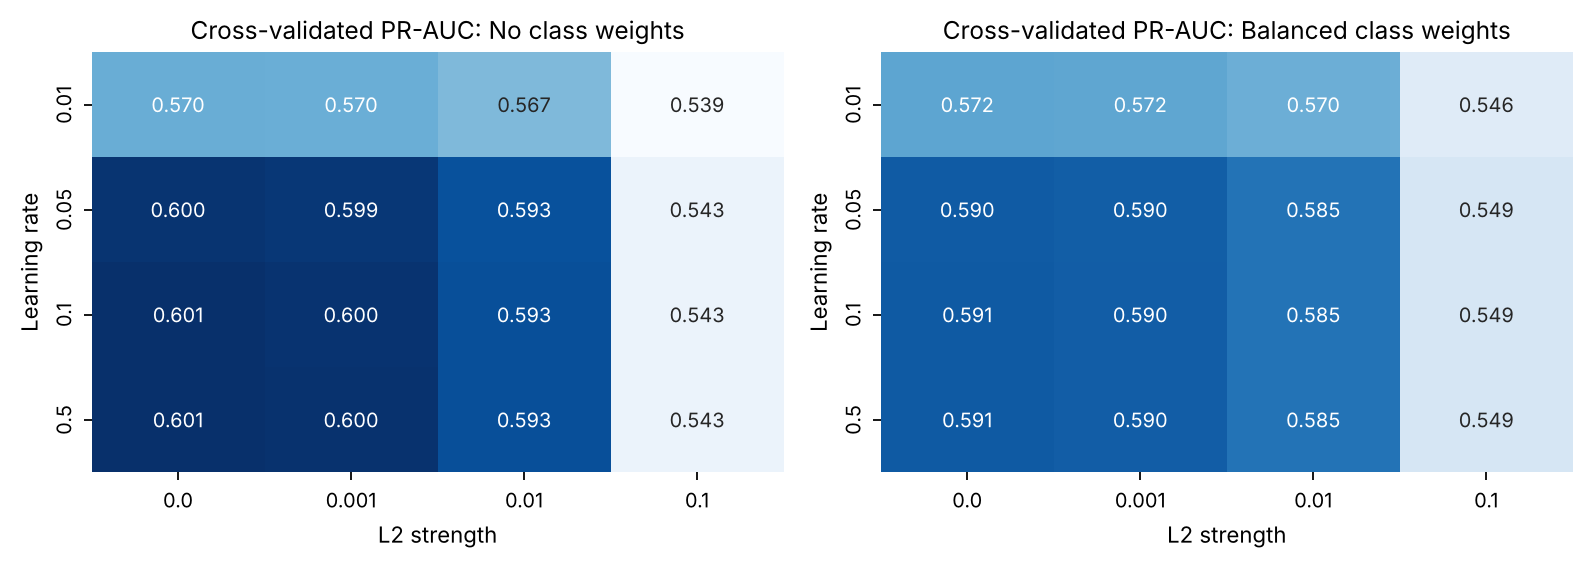

In [17]:
EV = {}                                              # extra numbers for the report
M_KEYS = ["accuracy", "precision", "recall", "f1", "mcc", "roc_auc", "pr_auc"]
M_LAB = ["Accuracy", "Precision", "Recall", "F1", "MCC", "ROC-AUC", "PR-AUC"]

# --- 9b.1 Metric comparison (grouped bars) and radar chart --------------------------------------------------------------------
r_keys = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc"]
r_lab = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC"]
ang = np.linspace(0, 2 * np.pi, len(r_keys), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(5.4, 5.0)); axr = plt.subplot(111, polar=True)
for m_, lab_, col_ in [(m1_test, "Model 1", BLUE), (m2_test, "Model 2", ORANGE)]:
    v_ = [m_[k] for k in r_keys]; v_ += v_[:1]
    axr.plot(ang, v_, color=col_, lw=2, label=lab_); axr.fill(ang, v_, color=col_, alpha=0.15)
axr.set_xticks(ang[:-1]); axr.set_xticklabels(r_lab); axr.set_ylim(0, 1)
axr.set_title("Profile of the two models (test set)", pad=18); axr.legend(loc="lower right", bbox_to_anchor=(1.2, -0.05), frameon=False)
savefig("fig34_radar")

# --- 9b.2 What the predictions look like: outcomes as donut charts ---------------------------------------------------------------
conf_cols = [BLUE, "#9DB7D3", "#F0C49A", ORANGE]
conf_lab = ["True negative", "False positive", "False negative", "True positive"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for a, m_, ttl_ in [(axes[0], m1_test, "Model 1: 2,000 test books"), (axes[1], m2_test, "Model 2: 2,000 test books")]:
    donut(a, [m_["tn"], m_["fp"], m_["fn"], m_["tp"]], conf_lab, conf_cols, ttl_)
savefig("fig35_outcome_donuts")

# --- 9b.3 Score distributions, KS statistic ------------------------------------------------------------------------------------------
pos_s, neg_s = p2_test[y_test == 1], p2_test[y_test == 0]
ks_stat, ks_p = stats.ks_2samp(pos_s, neg_s)
grid_s = np.linspace(0, 1, 501)
cdf_pos = np.searchsorted(np.sort(pos_s), grid_s, side="right") / len(pos_s)
cdf_neg = np.searchsorted(np.sort(neg_s), grid_s, side="right") / len(neg_s)
ks_at = grid_s[np.argmax(np.abs(cdf_neg - cdf_pos))]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].hist(neg_s, bins=40, range=(0, 1), alpha=0.65, color=BLUE, density=True, label="Not best seller")
axes[0].hist(pos_s, bins=40, range=(0, 1), alpha=0.65, color=ORANGE, density=True, label="Best seller")
axes[0].axvline(best_thr, color="black", ls="--", lw=1.2, label=f"Threshold {best_thr:.2f}")
axes[0].axvline(0.5, color=GREY, ls=":", lw=1.5, label="Model 1 threshold 0.50")
axes[0].set_xlabel("Predicted probability"); axes[0].set_ylabel("Density"); axes[0].set_title("Score distributions (Model 2, test set)")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(grid_s, cdf_neg, color=BLUE, lw=2, label="Not best seller"); axes[1].plot(grid_s, cdf_pos, color=ORANGE, lw=2, label="Best seller")
axes[1].vlines(ks_at, cdf_pos[np.argmax(np.abs(cdf_neg - cdf_pos))], cdf_neg[np.argmax(np.abs(cdf_neg - cdf_pos))], color="black", lw=2)
axes[1].set_xlabel("Predicted probability"); axes[1].set_ylabel("Cumulative share of books")
axes[1].set_title(f"KS statistic = {ks_stat:.3f} (at {ks_at:.2f})"); axes[1].legend(frameon=False)
savefig("fig36_scores_ks")
EV["ks"] = float(ks_stat); EV["ks_at"] = float(ks_at)
EV["median_score_pos"], EV["median_score_neg"] = float(np.median(pos_s)), float(np.median(neg_s))

# --- 9b.6 Deciles of predicted probability ---------------------------------------------------------------------------------------------------
dec_idx = pd.qcut(pd.Series(p2_test).rank(method="first"), 10, labels=False)
dec_tab = pd.DataFrame({"decile": dec_idx, "p": p2_test, "y": y_test}).groupby("decile").agg(n=("y", "size"), best_sellers=("y", "sum"),
                        mean_pred=("p", "mean"), observed=("y", "mean")).reset_index()
dec_tab["decile"] = 10 - dec_tab["decile"]          # decile 1 = highest scores
dec_tab = dec_tab.sort_values("decile").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(dec_tab["decile"] - 0.2, dec_tab["mean_pred"], 0.4, color=BLUE, label="Mean predicted probability")
ax.bar(dec_tab["decile"] + 0.2, dec_tab["observed"], 0.4, color=ORANGE, label="Observed best-seller rate")
ax.set_xticks(range(1, 11)); ax.set_xlabel("Decile of predicted score (1 = highest)"); ax.set_ylabel("Rate")
ax.set_title("Predicted versus observed rate by decile (test set)"); ax.legend(frameon=False)
savefig("fig39_deciles")
EV["decile_table"] = dec_tab.round(3).to_dict("records")

# --- 9b.7 Cost-sensitive threshold choice (on out-of-fold training predictions) ---------------------------------------------------
_, _, oof_final = cross_validate(best_params)
thr_g2 = np.linspace(0.05, 0.95, 91)
fp_c = np.array([((oof_final >= t) & (y_train == 0)).sum() for t in thr_g2])
fn_c = np.array([((oof_final < t) & (y_train == 1)).sum() for t in thr_g2])
fig, ax = plt.subplots(figsize=(7.5, 3.9))
EV["cost_opt"] = {}
for ratio, col_ in zip([1, 2, 3, 5], [BLUE, ORANGE, "#6A9E5B", "#8E5BA8"]):
    cost = (fp_c + ratio * fn_c) / len(y_train)
    ax.plot(thr_g2, cost, color=col_, lw=2, label=f"Missing a hit costs {ratio}x a false alarm")
    ax.plot(thr_g2[cost.argmin()], cost.min(), "o", color=col_)
    EV["cost_opt"][str(ratio)] = {"threshold": float(thr_g2[cost.argmin()]), "cost_per_book": float(cost.min())}
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Cost per book (units of one false alarm)")
ax.set_title("How the cost of mistakes moves the best threshold"); ax.legend(frameon=False, fontsize=8)
savefig("fig40_cost_threshold")

# --- 9b.10 Performance by subgroup (test set) -------------------------------------------------------------------------------------------------
tdf = df.iloc[idx_test].copy()
tdf["score"], tdf["y"] = p2_test, y_test
tdf["pred"] = (p2_test >= best_thr).astype(int)
sub_rows = []
for col_ in ["lang_group", "series_type", "era"]:
    for lvl, g_ in tdf.groupby(col_, observed=True):
        n_pos = int(g_["y"].sum())
        row = {"group": col_, "level": str(lvl), "n": int(len(g_)), "best_sellers": n_pos,
               "auc": float(roc_auc_score(g_["y"], g_["score"])) if 0 < n_pos < len(g_) and n_pos >= 10 else None,
               "recall": float(g_.loc[g_.y == 1, "pred"].mean()) if n_pos else None,
               "precision": float(g_.loc[g_.pred == 1, "y"].mean()) if (g_.pred == 1).sum() else None,
               "flag_rate": float(g_["pred"].mean())}
        sub_rows.append(row)
sub_df = pd.DataFrame(sub_rows)
sub_plot = sub_df.dropna(subset=["auc"]).reset_index(drop=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
ylab = (sub_plot["group"].str.replace("lang_group", "Language").str.replace("series_type", "Series").str.replace("era", "Era") + ": " + sub_plot["level"])
yy = np.arange(len(sub_plot))[::-1]
axes[0].barh(yy, sub_plot["auc"], color=BLUE); axes[0].set_xlim(0.5, 0.95); axes[0].axvline(m2_test["roc_auc"], color=ORANGE, ls="--")
axes[0].set_yticks(yy); axes[0].set_yticklabels(ylab); axes[0].set_xlabel("ROC-AUC"); axes[0].set_title("Ranking quality by subgroup (dashed = overall)")
axes[1].barh(yy, sub_plot["recall"], color=ORANGE); axes[1].axvline(m2_test["recall"], color=BLUE, ls="--")
axes[1].set_xlim(0, 1); axes[1].set_xlabel(f"Recall at threshold {best_thr:.2f}"); axes[1].set_title("Best sellers found by subgroup")
savefig("fig43_subgroups")
EV["subgroups"] = sub_df.round(3).where(sub_df.notna(), None).to_dict("records")

# --- 9b.12 Adding features one at a time (cross-validated ROC-AUC) -------------------------------------------------------------------------
order_all = order_f + [f_ for f_ in FEATURES if f_ not in order_f]
cv_auc_k, cv_ap_k = [], []
for k_ in range(1, len(order_all) + 1):
    ap_, auc_, _ = cross_validate(default_params, order_all[:k_])
    cv_auc_k.append(auc_); cv_ap_k.append(ap_)
fig, ax = plt.subplots(figsize=(8, 3.9))
ax.plot(range(1, 13), cv_auc_k, "o-", color=BLUE, label="Cross-validated ROC-AUC")
ax.plot(range(1, 13), cv_ap_k, "s-", color=ORANGE, label="Cross-validated PR-AUC")
ax.set_xticks(range(1, 13)); ax.set_xticklabels([f"{i}" for i in range(1, 13)]); ax.set_xlabel("Number of features (added in forward-selection order)")
ax.set_ylabel("Score"); ax.set_title("Diminishing returns from extra features"); ax.legend(frameon=False)
savefig("fig45_feature_addition")
EV["feature_addition"] = [{"k": k_, "feature": order_all[k_ - 1], "cv_auc": round(float(a_), 4), "cv_pr_auc": round(float(b_), 4)}
                          for k_, a_, b_ in zip(range(1, 13), cv_auc_k, cv_ap_k)]

# --- 9b.13 Learning rates compared, convergence and gradient size -----------------------------------------------------------------------------
def gd_trace(X, y, lr, n_iter):
    """Plain gradient descent that records the loss, the gradient length and the weights at every step."""
    w_, b_ = np.zeros(X.shape[1]), 0.0
    L, G, path = [], [], []
    for _ in range(n_iter):
        p_ = sigmoid(X @ w_ + b_); err = p_ - y
        L.append(float(-np.mean(y * np.log(p_ + 1e-12) + (1 - y) * np.log(1 - p_ + 1e-12))))
        gw, gb = X.T @ err / len(y), float(err.mean())
        G.append(float(np.sqrt(gw @ gw + gb ** 2))); path.append((w_.copy(), b_))
        w_ = w_ - lr * gw; b_ = b_ - lr * gb
    return np.array(L), np.array(G), path


fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
lr_cols = {0.01: GREY, 0.05: "#8E5BA8", 0.1: BLUE, 0.5: ORANGE, 1.0: "#6A9E5B"}
EV["lr_final_loss"] = {}
for lr_, col_ in lr_cols.items():
    L_, G_, _ = gd_trace(Xs_train, y_train, lr_, 1000)
    axes[0].plot(np.arange(1, 1001), L_, color=col_, lw=2, label=f"lr = {lr_}")
    axes[1].plot(np.arange(1, 1001), G_, color=col_, lw=2, label=f"lr = {lr_}")
    EV["lr_final_loss"][str(lr_)] = {"loss_100": float(L_[99]), "loss_1000": float(L_[-1]), "grad_1000": float(G_[-1])}
axes[0].set_xscale("log"); axes[0].set_xlabel("Iteration (log scale)"); axes[0].set_ylabel("Log-loss"); axes[0].set_title("Loss for five learning rates")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlabel("Iteration (log scale)"); axes[1].set_ylabel("Length of the gradient")
axes[1].set_title("The gradient shrinks towards zero at the optimum"); axes[0].legend(frameon=False, fontsize=8)
savefig("fig46_learning_rates")

# --- 9b.14 Loss surface with the gradient-descent path (two-feature illustration) ----------------------------------------------------------------
i_ed, i_rt = SELECTED.index("log_books_count"), SELECTED.index("average_rating")
X2 = Xs_train[:, [i_ed, i_rt]]
# --- 9b.15 Decision surface for the same two features ---------------------------------------------------------------------------------------------
L3, G3, path3 = gd_trace(X2, y_train, 0.5, 1500)
w3, b3 = path3[-1]
gx = np.linspace(-3.2, 4.0, 200); gy = np.linspace(-4.0, 3.5, 200)
GX, GY = np.meshgrid(gx, gy)
PZ = sigmoid(w3[0] * GX + w3[1] * GY + b3)
smp = np.random.default_rng(3).choice(len(y_train), 900, replace=False)
fig, ax = plt.subplots(figsize=(6.6, 4.8))
cs = ax.contourf(GX, GY, PZ, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.75); plt.colorbar(cs, ax=ax, label="Predicted probability")
ax.contour(GX, GY, PZ, levels=[best_thr], colors="black", linewidths=2)
ax.scatter(X2[smp, 0], X2[smp, 1], c=np.where(y_train[smp] == 1, ORANGE, BLUE), s=9, edgecolor="white", linewidth=0.3)
ax.set_xlabel("log editions (standardised)"); ax.set_ylabel("average rating (standardised)")
ax.set_title(f"Decision surface (black line = threshold {best_thr:.2f})")
savefig("fig48_decision_surface")

# --- 9b.16 Regularisation path ------------------------------------------------------------------------------------------------------------------------
lams = np.logspace(-4, 0.5, 14)
coef_path = []
for lam in lams:
    coef_path.append(LogisticRegressionScratch(lr=0.5, n_iter=2000, l2=lam).fit(Xs_train, y_train).w.copy())
coef_path = np.array(coef_path)
fig, ax = plt.subplots(figsize=(8, 4.4))
cmap20 = plt.cm.tab20(np.linspace(0, 1, len(SELECTED)))
for j_, f_ in enumerate(SELECTED):
    ax.plot(np.log10(lams), coef_path[:, j_], color=cmap20[j_], lw=2, label=f_)
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("log10(L2 penalty strength)"); ax.set_ylabel("Coefficient (per 1 SD)")
ax.set_title("Regularisation path: coefficients shrink as the penalty grows"); ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper right")
savefig("fig49_reg_path")
EV["reg_path_editions"] = {"lam_small": float(lams[0]), "coef_small": float(coef_path[0, SELECTED.index("log_books_count")]),
                           "lam_large": float(lams[-1]), "coef_large": float(coef_path[-1, SELECTED.index("log_books_count")])}

# --- 9b.17 Sigmoid with real books ----------------------------------------------------------------------------------------------------------------------
z_test = Xs_test @ model2.w + model2.b
zz_ = np.linspace(-8, 6, 300)
picks = {"Highest score": int(np.argmax(z_test)), "Closest to threshold": int(np.argmin(np.abs(p2_test - best_thr))), "Lowest score": int(np.argmin(z_test))}
fig, ax = plt.subplots(figsize=(7.4, 4.0))
ax.plot(zz_, sigmoid(zz_), color=BLUE, lw=2.5)
ax.axhline(best_thr, color="black", ls="--", lw=1); ax.text(-7.8, best_thr + 0.02, f"threshold {best_thr:.2f}", fontsize=8)
EV["sigmoid_examples"] = []
for (lab_, j_), off in zip(picks.items(), [(-6.2, -0.22), (-3.6, 0.17), (0.4, 0.08)]):
    ax.plot(z_test[j_], p2_test[j_], "o", color=ORANGE, markersize=9)
    ttl_ = str(model_df.iloc[idx_test[j_]]["title"]).split(" (")[0][:34]
    ax.annotate(f"{lab_}:\n{ttl_}\np = {p2_test[j_]:.3f}", (z_test[j_], p2_test[j_]), xytext=(z_test[j_] + off[0], p2_test[j_] + off[1]), fontsize=8,
                arrowprops=dict(arrowstyle="-", color=GREY))
    EV["sigmoid_examples"].append({"label": lab_, "title": ttl_, "z": float(z_test[j_]), "p": float(p2_test[j_]), "actual": int(y_test[j_])})
ax.set_xlabel("z = w . x + b (the model's raw score)"); ax.set_ylabel("Probability of best seller"); ax.set_title("The sigmoid turns a raw score into a probability")
savefig("fig50_sigmoid")

# --- 9b.18 Error analysis (most confident mistakes) ----------------------------------------------------------------------------------------------------
fp8 = test_info[test_info.actual == 0].nlargest(8, "proba"); fn8 = test_info[test_info.actual == 1].nsmallest(8, "proba")
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
axes[0].barh([str(t).split(" (")[0][:34] for t in fp8["title"]][::-1], fp8["proba"].values[::-1], color=BLUE)
axes[0].set_xlim(0, 1); axes[0].set_xlabel("Predicted probability"); axes[0].set_title("Confident false alarms (not best sellers)")
axes[1].barh([str(t).split(" (")[0][:34] for t in fn8["title"]][::-1], fn8["proba"].values[::-1], color=ORANGE)
axes[1].set_xlim(0, 0.03); axes[1].set_xlabel("Predicted probability (note: axis stops at 3%; threshold is 30%)")
axes[1].set_title("Missed best sellers (lowest scores)")
savefig("fig51_error_bars")
raw_ed = raw.set_index("title")["books_count"]
EV["fp_editions"] = [int(raw[raw.title == t]["books_count"].iloc[0]) for t in fp8["title"]]
EV["fn_editions"] = [int(raw[raw.title == t]["books_count"].iloc[0]) for t in fn8["title"]]

# --- 9b.19 Tuning grids for both class-weight settings --------------------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for a, cw_, ttl_ in [(axes[0], None, "No class weights"), (axes[1], "balanced", "Balanced class weights")]:
    sub = grid[grid.class_weight.isna()] if cw_ is None else grid[grid.class_weight == cw_]
    sns.heatmap(sub.pivot(index="lr", columns="l2", values="cv_pr_auc"), annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=a,
                vmin=grid["cv_pr_auc"].min(), vmax=grid["cv_pr_auc"].max())
    a.set_title(f"Cross-validated PR-AUC: {ttl_}"); a.set_xlabel("L2 strength"); a.set_ylabel("Learning rate")
savefig("fig52_grid_both")
EV["grid_range"] = {"min": float(grid["cv_pr_auc"].min()), "max": float(grid["cv_pr_auc"].max())}

RESULTS["extra_eval"] = EV

## 10. Validate the scratch implementation against scikit-learn
If my maths is right, an un-penalised scratch model should give (almost) the same
coefficients and predictions as scikit-learn's `LogisticRegression(penalty=None)`.

In [18]:
scratch_check = LogisticRegressionScratch(lr=0.5, n_iter=20000, l2=0.0, tol=1e-12).fit(Xs_train, y_train)
sk = LogisticRegression(penalty=None, max_iter=5000).fit(Xs_train, y_train)
coef_diff = float(np.max(np.abs(scratch_check.w - sk.coef_.ravel())))
newton_diff = float(np.max(np.abs(final_fit["coef"].drop("intercept").values - sk.coef_.ravel())))
auc_scratch = roc_auc_score(y_test, scratch_check.predict_proba(Xs_test))
auc_sk = roc_auc_score(y_test, sk.predict_proba(Xs_test)[:, 1])
print(f"Max |coef difference|  gradient-descent vs sklearn : {coef_diff:.5f}")
print(f"Max |coef difference|  Newton-Raphson   vs sklearn : {newton_diff:.5f}")
print(f"Test AUC scratch = {auc_scratch:.4f}   sklearn = {auc_sk:.4f}")
RESULTS["validation"] = {"gd_vs_sklearn_max_coef_diff": coef_diff, "newton_vs_sklearn_max_coef_diff": newton_diff,
                         "auc_scratch": float(auc_scratch), "auc_sklearn": float(auc_sk)}

Max |coef difference|  gradient-descent vs sklearn : 0.00237
Max |coef difference|  Newton-Raphson   vs sklearn : 0.00238
Test AUC scratch = 0.8125   sklearn = 0.8125


In [19]:
with open(f"{OUT_DIR}/results.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))
print("\nAll figures, tables and results.json saved in:", OUT_DIR)


All figures, tables and results.json saved in: outputs
